cat qubits, from losing photons to reading a bit

this follows the introductory track, then the standard track of the supplied
duquantum 2026 prompt. the small comments are there so the calculations can be
walked through, not just run. all times below are in microseconds.

the questions i want to keep asking: is this a real cat or just two blobs?
is a small error physical, or did the fock-space ceiling manufacture it?
and can the buffer's ringing help a measurement instead of just delaying it?

the numbers below are computed by these cells, not typed in from the prompt's expectations.

In [1]:
%pip install -r requirements.txt


[notice] A new release of pip is available: 26.0 -> 26.2.2
[notice] To update, run: /private/tmp/cat-clean-validation.AuhXse/venv/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip check

No broken requirements found.


Note: you may need to restart the kernel to use updated packages.


In [3]:
import os  # keep caches local when this runs on another computer
from pathlib import Path  # portable paths for the saved tables and figures
os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd() / ".cache" / "matplotlib"))

import time  # records the cost of the numerical checks
import json  # saves a small machine-readable summary at the end
import hashlib  # ties cached full-model runs to the actual matrices and solver settings
import importlib.metadata as metadata  # records exactly which package versions ran
import numpy as np  # ordinary arrays for analysis and plotting
import pandas as pd  # puts the convergence results in readable tables
import matplotlib.pyplot as plt  # makes the figures
import scipy.linalg as la  # dense linear algebra for small verification problems
from scipy.optimize import curve_fit  # fits decay rates rather than eyeballing them
from scipy.sparse.linalg import eigs  # finds slow modes without evolving for seconds
from scipy.integrate import cumulative_trapezoid  # accumulates readout information
from scipy.special import erfc  # gaussian discrimination error, with caveats below
import qutip as qt  # independent sparse solver and wigner-function calculation
import dynamiqs as dq  # the master-equation solver requested in the challenge
import jax  # dynamiqs uses jax underneath
import jax.numpy as jnp  # arrays which the compiled solver understands
from IPython.display import display  # keeps tables readable inside the notebook

dq.set_precision("double")  # tiny decay rates need 64-bit, not the tutorial's 32-bit
dq.set_progress_meter(False)  # a separate progress bar for every solve gets noisy
plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False, "axes.spines.right": False})
artifacts = Path("artifacts")  # these are generated results, not input data
artifacts.mkdir(exist_ok=True)
g2 = 2 * np.pi * 0.763  # mhz -> angular frequency per microsecond
kb = 2 * np.pi * 2.6  # intentionally leaky buffer
ka = 2 * np.pi * 0.0093  # unwanted single-photon memory loss
alpha = 2.1  # target separation in coherent-state amplitude
k2 = 4 * g2**2 / kb  # eliminated-buffer prediction, not automatically valid
eps_d = g2 * alpha**2  # buffer drive with the sign convention of this prompt
versions = {name: metadata.version(name) for name in ["dynamiqs", "jax", "qutip", "numpy", "scipy", "matplotlib", "pandas"]}
print(versions)
print(f"jax double precision: {jax.config.x64_enabled}; devices: {jax.devices()}")
display(pd.Series({"g2": g2, "kb": kb, "ka": ka, "k2": k2, "eps_d": eps_d}, name="per microsecond"))

Matplotlib is building the font cache; this may take a moment.


{'dynamiqs': '0.3.7', 'jax': '0.12.0.1', 'qutip': '5.3.1', 'numpy': '2.5.4', 'scipy': '1.18.1', 'matplotlib': '3.11.2', 'pandas': '3.1.0'}
jax double precision: True; devices: [CpuDevice(id=0)]


g2        4.794070
kb       16.336282
ka        0.058434
k2        5.627501
eps_d    21.141850
Name: per microsecond, dtype: float64

a few reusable pieces, so changing a cutoff really changes the same model.

a density matrix contains populations on its diagonal and coherences off its
diagonal. the two-mode matrix is indexed as `(memory, buffer)` on each side.
tracing out the buffer means summing over its matching row/column indices.
i save the reduced memory state during a solve, rather than hundreds of large
two-mode matrices. this changes storage, not the equation being integrated.

In [4]:
def cat_ket(n, amplitude, sign=1):
    plus = dq.coherent(n, amplitude)  # one well
    minus = dq.coherent(n, -amplitude)  # the other well
    return dq.unit(plus + sign * minus)  # normalization includes their overlap


def two_mode(na, nb, amplitude=alpha, loss=ka, drive=0.0, coupling=g2, buffer_loss=kb):
    a, b = dq.destroy(na, nb)  # tensor-product operators, not two unrelated matrices
    h = coupling * (a @ a @ b.dag() + a.dag() @ a.dag() @ b)
    h = h - coupling * amplitude**2 * (b + b.dag())  # same target wells at every cutoff
    h = h + drive * (a + a.dag())  # optional real resonant memory drive
    jumps = [np.sqrt(buffer_loss) * b, np.sqrt(loss) * a]  # rates belong inside square roots
    tail_a = dq.tensor(dq.fock_dm(na, na - 2) + dq.fock_dm(na, na - 1), dq.eye(nb))
    tail_b = dq.tensor(dq.eye(na), dq.fock_dm(nb, nb - 1))  # include the transient, not only the end
    parity = dq.tensor(dq.parity(na), dq.eye(nb))  # only memory parity is the cat observable
    observables = [a.dag() @ a, b.dag() @ b, a, b, parity, tail_a, tail_b]
    return h, jumps, observables, a, b


def evolve(h, jumps, initial, times, observables, dims=None, rtol=2e-8, atol=2e-10):
    extra = None  # single-mode calculations can simply save their small matrices
    if dims is not None:
        extra = lambda t, rho: dq.to_jax(dq.ptrace(rho, 0))  # keep memory, discard buffer
    result = dq.mesolve(h, jumps, initial, jnp.asarray(times), exp_ops=observables,
                       method=dq.method.Tsit5(rtol=rtol, atol=atol, max_steps=2_000_000),
                       save_states=dims is None, save_extra=extra)  # sparse operators accelerate the rhs
    values = np.asarray(result.expects)  # this also waits for the actual computation to finish
    states = np.asarray(result.extra if dims is not None else dq.to_numpy(result.states))
    return {"t": np.asarray(times), "e": values, "rho": states, "final": result.final_state}


def run_key(h, jumps, initial, times, ops, rtol, atol):
    key = hashlib.sha256(f"memory-ptrace-v1:Tsit5:{rtol}:{atol}:{versions}".encode())
    for value in [h, *jumps, initial, *ops]:
        array = np.asarray(dq.to_numpy(value))  # hash actual operators, not just a descriptive filename
        key.update(str((array.shape, array.dtype)).encode())
        key.update(array.tobytes())
    key.update(np.asarray(times, dtype=np.float64).tobytes())
    folder = artifacts / "checkpoints"
    folder.mkdir(exist_ok=True)
    return folder / f"{key.hexdigest()}.npz"


def save_run(path, run):
    np.savez_compressed(path, t=run["t"], e=run["e"], rho=run["rho"], final=dq.to_numpy(run["final"]))


def full_run(na, nb, times, amplitude=alpha, seed=0.0, even=False, loss=ka, drive=0.0,
             rtol=2e-8, atol=2e-10):
    h, jumps, ops, a, b = two_mode(na, nb, amplitude, loss, drive)  # one model for every experiment
    memory = cat_ket(na, amplitude) if even else dq.coherent(na, seed)
    initial = dq.tensor(memory, dq.fock(nb, 0))  # buffer starts empty
    path = run_key(h, jumps, initial, times, ops, rtol, atol)
    if path.exists():
        with np.load(path, allow_pickle=False) as saved:  # optional speed-up; no pickle or hidden dependencies
            run = {name: saved[name] for name in ["t", "e", "rho"]}
            run["final"] = dq.asqarray(saved["final"], dims=(na, nb))
            return run
    run = evolve(h, jumps, initial, times, ops, (na, nb), rtol, atol)
    save_run(path, run)  # delete artifacts/checkpoints to force every solve to run again
    return run


def checks(run):
    rho = run["rho"]  # reduced states still must be valid density matrices
    trace_error = np.max(np.abs(np.trace(rho, axis1=-2, axis2=-1) - 1))
    herm_error = np.max(np.abs(rho - rho.swapaxes(-1, -2).conj()))
    minimum_eigenvalue = np.linalg.eigvalsh(rho).min()  # negative beyond solver error is a warning
    return {"trace error": trace_error, "hermiticity error": herm_error, "min eigenvalue": minimum_eigenvalue}


def plot_wigners(states, titles, filename):
    grid = np.linspace(-3.8, 3.8, 151)  # axes are real and imaginary coherent amplitude
    fig, axes = plt.subplots(1, len(states), figsize=(3.1 * len(states), 2.8), constrained_layout=True)
    for axis, state, title in zip(np.atleast_1d(axes), states, titles):
        w = qt.wigner(qt.Qobj(state), grid, grid, g=2)  # g=2 means x=real(alpha), p=imag(alpha)
        axis.contourf(grid, grid, w, levels=np.linspace(-2 / np.pi, 2 / np.pi, 65), cmap="RdBu_r", extend="both")
        axis.set(title=title, xlabel="real amplitude", ylabel="imaginary amplitude", aspect="equal")
    fig.savefig(artifacts / filename, bbox_inches="tight")  # the notebook also retains the picture
    plt.show()


def table(frame, name):
    frame.to_csv(artifacts / f"{name}.csv", index=False)  # enough precision for independent replotting
    display(frame)


def finish_figure(fig, name):
    fig.tight_layout()  # don't cut off axis labels
    fig.savefig(artifacts / f"{name}.png", bbox_inches="tight")
    plt.show()

1.0a — one photon at a time

here the whole state stays coherent: its amplitude is
$2\exp[-(\kappa/2+i\Delta)t]$. squaring its magnitude gives the predicted
photon number. this is a useful check on units, normalization, and the solver.

maximum photon-number error: 1.994e-11


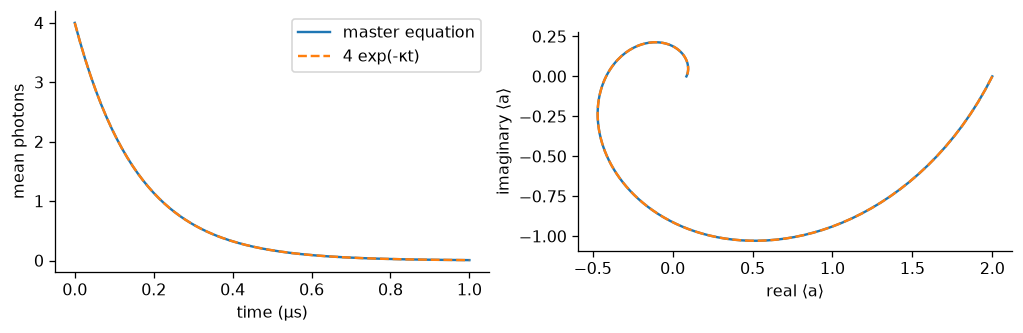

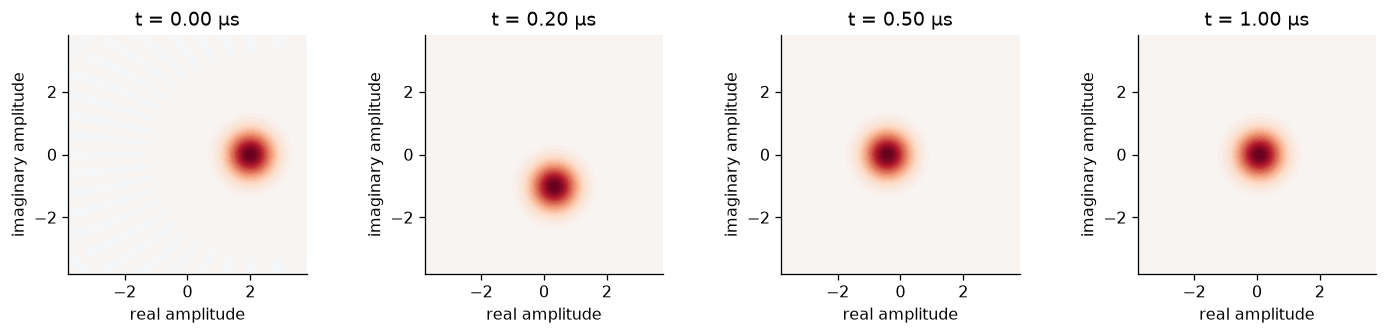

In [5]:
n = 30  # the warm-up cutoff requested in the prompt
c = dq.destroy(n)  # a single memory mode for now
number = c.dag() @ c  # counts photons
warm_t = np.linspace(0, 1, 151)  # one microsecond
warm = evolve(2 * np.pi * number, [np.sqrt(2 * np.pi) * c], dq.coherent(n, 2), warm_t, [number, c])
analytic_n = 4 * np.exp(-2 * np.pi * warm_t)  # the loss rate is angular, as specified
analytic_a = 2 * np.exp(-(np.pi + 2j * np.pi) * warm_t)  # rotating and shrinking
warm_error = np.max(np.abs(warm["e"][0].real - analytic_n))
print(f"maximum photon-number error: {warm_error:.3e}")
assert warm_error < 2e-6  # fail visibly if an elementary case is wrong
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(warm_t, warm["e"][0].real, label="master equation")
axes[0].plot(warm_t, analytic_n, "--", label="4 exp(-κt)")
axes[0].set(xlabel="time (μs)", ylabel="mean photons")
axes[0].legend()
axes[1].plot(warm["e"][1].real, warm["e"][1].imag, label="simulation")
axes[1].plot(analytic_a.real, analytic_a.imag, "--", label="analytic amplitude")
axes[1].set(xlabel="real ⟨a⟩", ylabel="imaginary ⟨a⟩", aspect="equal")
finish_figure(fig, "01_single_photon_loss")
plot_wigners(warm["rho"][[0, 30, 75, 150]], [f"t = {warm_t[i]:.2f} μs" for i in [0, 30, 75, 150]], "02_shrinking_coherent.png")

1.0b — losing pairs leaves an odd photon behind

$a^2$ annihilates both $|0\rangle$ and $|1\rangle$. more importantly, it never
changes even/odd parity. every initially odd fock population can cascade down
to $|1\rangle$, not just the population that started there. so the limiting
photon number is the *total initial odd probability*,
$(1-e^{-2|\alpha_0|^2})/2$, not $P(n=1)$.

final n = 0.499832269; total odd probability = 0.499832269


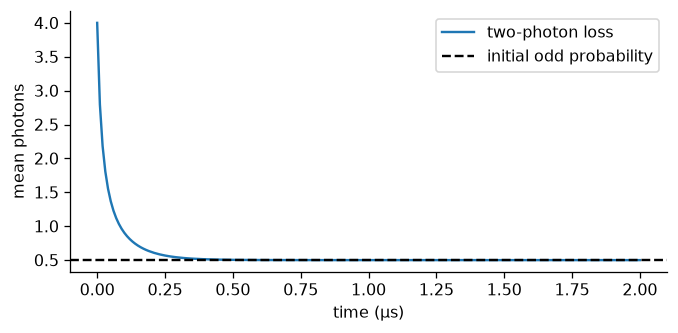

In [6]:
pair_t = np.linspace(0, 2, 201)  # enough time for all higher fock levels to empty
pair = evolve(0 * number, [np.sqrt(k2) * c @ c], dq.coherent(n, 2), pair_t, [number, dq.parity(n)])
odd_probability = (1 - np.exp(-8)) / 2  # coherent-state poisson distribution, summed over odd n
print(f"final n = {pair['e'][0, -1].real:.9f}; total odd probability = {odd_probability:.9f}")
assert abs(pair["e"][0, -1].real - odd_probability) < 2e-6
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(pair_t, pair["e"][0].real, label="two-photon loss")
ax.axhline(odd_probability, ls="--", color="black", label="initial odd probability")
ax.set(xlabel="time (μs)", ylabel="mean photons")
ax.legend()
finish_figure(fig, "03_pair_loss")

1.0c — add the drive inside the two-photon jump

if $\kappa_a=0$, multiplying $\kappa_2$ multiplies the *entire* generator, so
changing $\kappa_2$ is exactly rescaling time. with fixed nonzero $\kappa_a$,
that statement is only approximate, and the final photon numbers can differ
slightly too. the steady state is not exactly a pure even cat under loss.

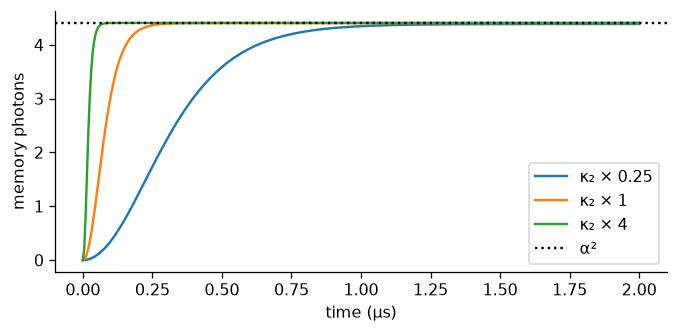

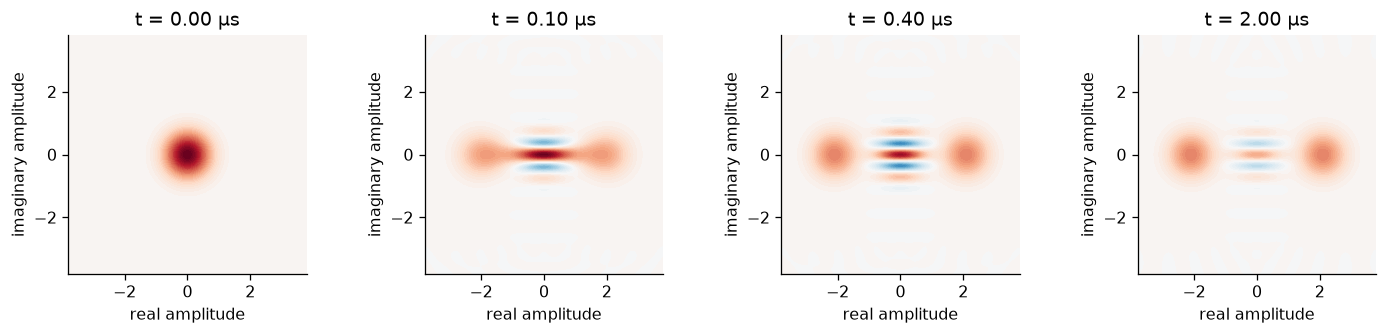

In [7]:
inflate_t = np.linspace(0, 2, 401)  # resolves the early overshoot in the next task too
effective = {}  # keep all three runs for later comparisons
for factor in [0.25, 1.0, 4.0]:
    l2 = np.sqrt(factor * k2) * (c @ c - alpha**2 * dq.eye(n))
    effective[factor] = evolve(0 * number, [l2, np.sqrt(ka) * c], dq.fock(n, 0), inflate_t, [number, dq.parity(n)])
fig, ax = plt.subplots(figsize=(6, 3))
for factor, run in effective.items():
    ax.plot(inflate_t, run["e"][0].real, label=f"κ₂ × {factor:g}")
ax.axhline(alpha**2, ls=":", color="black", label="α²")
ax.set(xlabel="time (μs)", ylabel="memory photons")
ax.legend()
finish_figure(fig, "04_effective_stabilization")
plot_wigners(effective[1.0]["rho"][[0, 20, 80, 400]], [f"t = {inflate_t[i]:.2f} μs" for i in [0, 20, 80, 400]], "05_effective_cat.png")

1.1 and 1.2 — let the buffer be a real mode, and move both ceilings

the workshop hint was to vary the memory hilbert-space truncation too.
here each axis is swept separately. a tiny final buffer occupation does not
excuse cutting off its earlier transient. the reference is the largest tested
pair, not a claim to have simulated an infinite oscillator.

the declared observable tolerance is 0.2% relative to that reference, for both
final photon number and transient peak. tails are a separate diagnostic:
a small tail alone is not a convergence proof. a 0.005 μs output grid locates
the peak; a finer-grid check below tests that choice.

In [8]:
cutoff_pairs = [(na, 12) for na in [16, 20, 24, 32, 40]]  # memory sweep with buffer held fixed
cutoff_pairs += [(40, nb) for nb in [4, 6, 8, 10, 16]]  # buffer sweep; (40,12) already exists
cutoff_pairs += [(24, 6)]  # the suggested starting point deserves a direct comparison
inflations = {}  # keep reduced states, not all the large joint density matrices
cutoff_rows = []
for na, nb in cutoff_pairs:
    start = time.perf_counter()  # includes compilation when this dimension is new
    run = full_run(na, nb, inflate_t)
    inflations[na, nb] = run
    cutoff_rows.append({"na": na, "nb": nb, "final n": run["e"][0, -1].real,
                        "peak n": run["e"][0].real.max(), "peak buffer n": run["e"][1].real.max(),
                        "max memory tail": run["e"][5].real.max(), "max buffer tail": run["e"][6].real.max(),
                        "seconds": time.perf_counter() - start})
    print(f"cutoffs ({na}, {nb}) finished in {cutoff_rows[-1]['seconds']:.1f}s", flush=True)
convergence = pd.DataFrame(cutoff_rows)
reference_row = convergence.query("na == 40 and nb == 16").iloc[0]
for quantity in ["final n", "peak n"]:
    convergence[f"relative error: {quantity}"] = abs(convergence[quantity] / reference_row[quantity] - 1)
table(convergence, "cutoff_convergence")
observable_tolerance = 0.002  # 0.2%, stated before selecting a cutoff
for column, fixed_column, fixed_value in [("na", "nb", 12), ("nb", "na", 40)]:
    subset = convergence[convergence[fixed_column] == fixed_value].sort_values(column)
    for quantity in ["final n", "peak n"]:
        passing = subset[f"relative error: {quantity}"].to_numpy() < observable_tolerance
        stable = np.logical_and.accumulate(passing[::-1])[::-1]  # every larger tested value must pass too
        print(f"smallest tested {column} passing {quantity}: {subset.loc[stable, column].min()}")

cutoffs (16, 12) finished in 4.6s


cutoffs (20, 12) finished in 4.4s


cutoffs (24, 12) finished in 4.2s


cutoffs (32, 12) finished in 3.9s


cutoffs (40, 12) finished in 5.1s


...

cutoffs (40, 10) finished in 3.5s


cutoffs (40, 16) finished in 2.8s


cutoffs (24, 6) finished in 2.4s


,na,nb,final n,peak n,peak buffer n,max memory tail,max buffer tail,seconds,relative error: final n,relative error: peak n
0,16,12,4.407074,6.373158,1.996227,5.712957e-02,0.003595,4.626164,1.162128e-03,0.077840
1,20,12,4.402086,6.807557,1.992262,1.259750e-02,0.001286,4.398155,2.894579e-05,0.014985
2,24,12,4.401970,6.896737,1.991880,2.000029e-03,0.000385,4.199467,2.485057e-06,0.002081
3,32,12,4.401958,6.908426,1.991853,1.364555e-05,0.000169,3.894958,2.495303e-07,0.000390
4,40,12,4.401958,6.908440,1.991853,3.303086e-07,0.000169,5.138537,2.108464e-07,0.000387
5,40,4,4.402302,4.462028,1.487084,1.916149e-08,0.193312,5.910110,7.799770e-05,0.354370
6,40,6,4.402091,6.114285,1.889598,7.172523e-09,0.046242,1.524479,3.014314e-05,0.115297
7,40,8,4.401975,6.744151,1.980652,3.087124e-07,0.008641,3.272712,3.794704e-06,0.024159
8,40,10,4.401958,6.886450,1.990910,2.631637e-07,0.001326,3.460646,2.230506e-07,0.003569
9,40,16,4.401959,6.911117,1.991905,4.535692e-07,0.000002,2.768017,0.000000e+00,0.000000


smallest tested na passing final n: 16
smallest tested na passing peak n: 32
smallest tested nb passing final n: 4
smallest tested nb passing peak n: 12


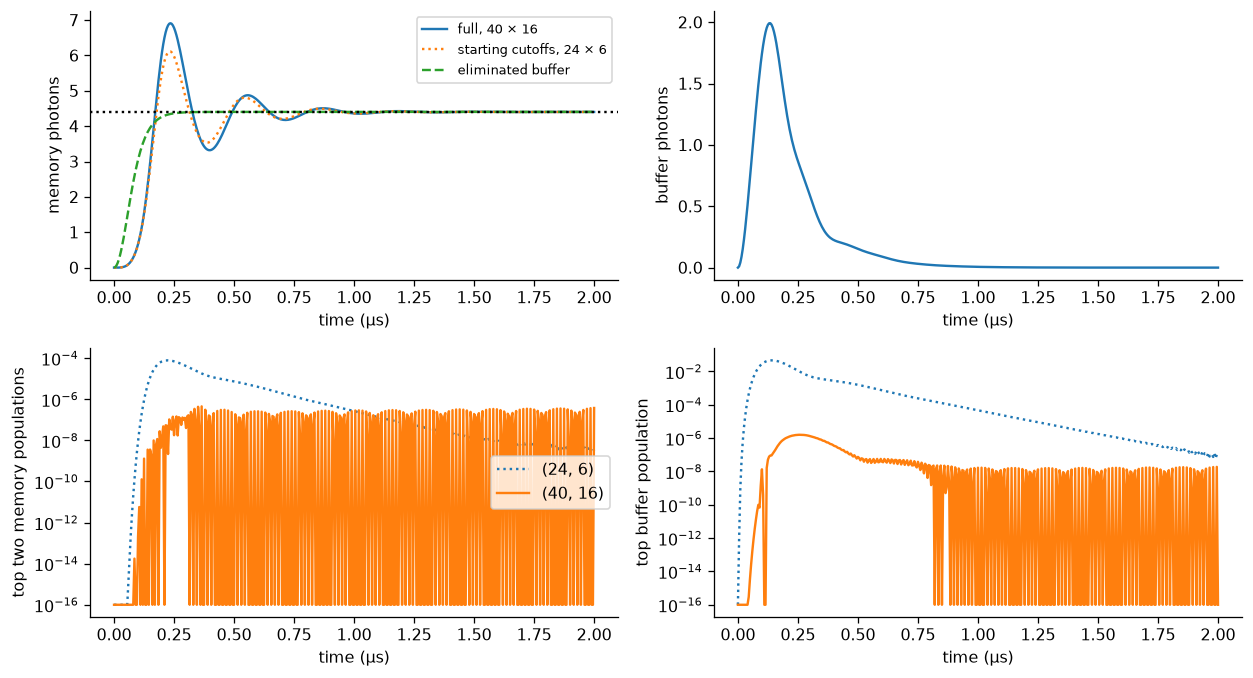

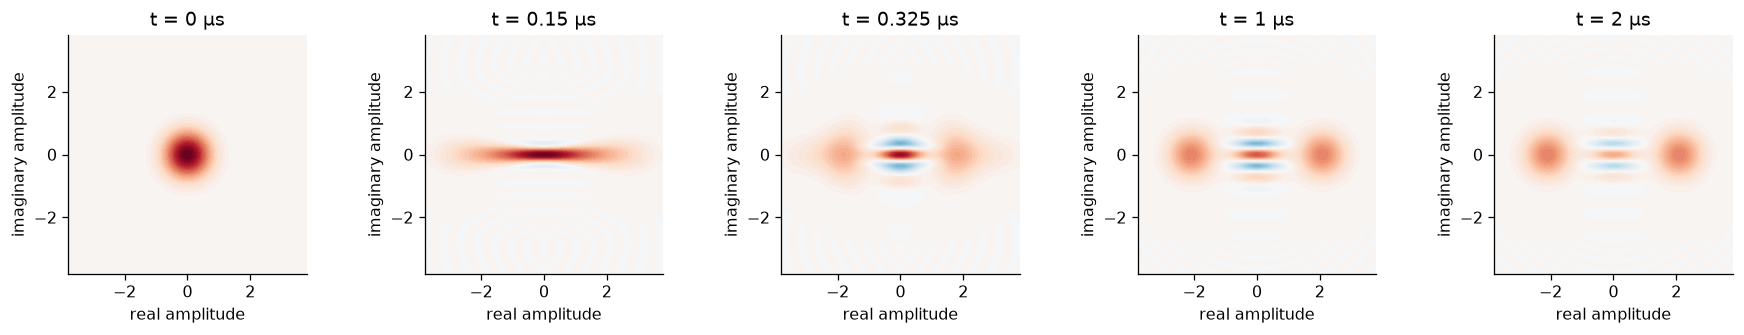

g2/kb = 0.2935; eps_d/kb = 1.2942
final n differs from alpha² by -0.182%
reference reduced-state checks: {'trace error': np.float64(1.9984014443252818e-15), 'hermiticity error': np.float64(0.0), 'min eigenvalue': np.float64(-1.742935356532031e-06)}


In [9]:
inflation = inflations[40, 16]  # safest tested run for figures and cat-state diagnostics
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
axes[0, 0].plot(inflate_t, inflation["e"][0].real, label="full, 40 × 16")
axes[0, 0].plot(inflate_t, inflations[24, 6]["e"][0].real, ":", label="starting cutoffs, 24 × 6")
axes[0, 0].plot(inflate_t, effective[1.0]["e"][0].real, "--", label="eliminated buffer")
axes[0, 0].axhline(alpha**2, ls=":", color="black")
axes[0, 0].set(ylabel="memory photons")
axes[0, 0].legend(fontsize=8)
axes[0, 1].plot(inflate_t, inflation["e"][1].real)
axes[0, 1].set(ylabel="buffer photons")
for pair, style in [((24, 6), ":"), ((40, 16), "-")]:
    run = inflations[pair]
    axes[1, 0].semilogy(inflate_t, np.maximum(run["e"][5].real, 1e-16), style, label=str(pair))
    axes[1, 1].semilogy(inflate_t, np.maximum(run["e"][6].real, 1e-16), style, label=str(pair))
axes[1, 0].set(ylabel="top two memory populations")
axes[1, 1].set(ylabel="top buffer population")
for axis in axes.flat:
    axis.set(xlabel="time (μs)")
axes[1, 0].legend()
finish_figure(fig, "06_full_inflation_and_tails")
plot_wigners(inflation["rho"][[0, 30, 65, 200, 400]], [f"t = {inflate_t[i]:.3g} μs" for i in [0, 30, 65, 200, 400]], "07_full_cat.png")
print(f"g2/kb = {g2/kb:.4f}; eps_d/kb = {eps_d/kb:.4f}")
print(f"final n differs from alpha² by {100*(inflation['e'][0,-1].real/alpha**2-1):.3f}%")
print("reference reduced-state checks:", checks(inflation))
assert abs(inflation["e"][0, -1].real / alpha**2 - 1) < 0.02
assert checks(inflation)["trace error"] < 1e-7

the eliminated-buffer assumptions are not satisfied: $g_2/\kappa_b\simeq0.293$
and $\epsilon_d/\kappa_b\simeq1.294$. the buffer stores excitation and feeds it
back before it leaks away. linearizing near either well gives poles

$$\lambda_\pm=-\kappa_b/4\pm\sqrt{(\kappa_b/4)^2-(2g_2\alpha)^2}.$$

these are complex here: ringing is physical. also, with memory loss the
semiclassical stationary value is $|a|^2=\alpha^2-\kappa_a\kappa_b/(8g_2^2)$,
not precisely $\alpha^2$. settling of photon number is not settling of parity.

In [10]:
fine = full_run(32, 12, np.linspace(0, 2, 801), rtol=4e-9, atol=4e-11)  # tighter tolerance and twice the output resolution
coarse = inflations[32, 12]
print(f"peak change with tighter integration/finer output: {abs(fine['e'][0].real.max()-coarse['e'][0].real.max()):.3e}")
print(f"maximum matched-time n change: {np.max(abs(fine['e'][0, ::2]-coarse['e'][0])):.3e}")
late = inflate_t >= 1.5  # check an interval, not just the last point
print(f"late-time n variation / alpha²: {np.ptp(inflation['e'][0, late].real)/alpha**2:.3e}")
print(f"semiclassical loss-corrected n: {alpha**2-ka*kb/(8*g2**2):.6f}")

peak change with tighter integration/finer output: 8.762e-09
maximum matched-time n change: 9.021e-08
late-time n variation / alpha²: 1.803e-03
semiclassical loss-corrected n: 4.404808


1.3 — what state did inflation actually make?

$[P,H]=0$ and the buffer jump commutes with memory parity, but $Pa=-aP$.
without memory loss, vacuum's even parity stays even. with memory loss,
$d\langle P\rangle/dt=-2\kappa_a\langle n_aP\rangle$; it is not conserved.

i use squared pure-state fidelity $F_+=\langle C_+|\rho_a|C_+\rangle$.
the equal incoherent mixture of the two coherent states has parity
$e^{-2\alpha^2}$ and $F_+=(1+e^{-2\alpha^2})/2$. exceeding those baselines,
together with the negative central wigner fringes, distinguishes coherence
from merely seeing two lobes. there is no sharp universal 'cat lifetime'.

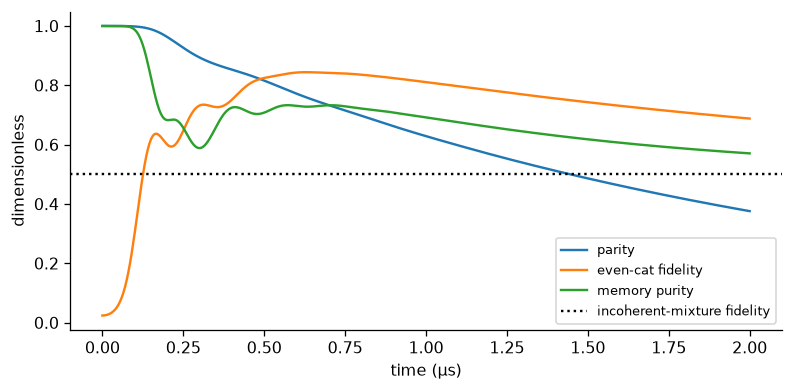

best even-cat fidelity = 0.844302 at t = 0.630 μs


prepared-cat parity 1/e time: 1.960 μs; simple prediction: 1.940 μs


maximum parity drift with ka=0: 1.998e-15


In [11]:
even40 = np.asarray(dq.to_numpy(cat_ket(40, alpha))).ravel()
cat_fidelity = np.einsum("i,tij,j->t", even40.conj(), inflation["rho"], even40).real
purity = np.einsum("tij,tji->t", inflation["rho"], inflation["rho"]).real
mixture_fidelity = (1 + np.exp(-2 * alpha**2)) / 2
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(inflate_t, inflation["e"][4].real, label="parity")
ax.plot(inflate_t, cat_fidelity, label="even-cat fidelity")
ax.plot(inflate_t, purity, label="memory purity")
ax.axhline(mixture_fidelity, ls=":", color="black", label="incoherent-mixture fidelity")
ax.set(xlabel="time (μs)", ylabel="dimensionless")
ax.legend(fontsize=8)
finish_figure(fig, "08_which_cat")
best_cat_index = int(np.argmax(cat_fidelity))
print(f"best even-cat fidelity = {cat_fidelity[best_cat_index]:.6f} at t = {inflate_t[best_cat_index]:.3f} μs")
coherence_t = np.linspace(0, 8, 401)  # long enough to cross an explicit 1/e coherence threshold
long_cat = full_run(28, 6, coherence_t, even=True)  # start from a prepared cat to isolate its lifetime
baseline_parity = np.exp(-2 * alpha**2)
crossings = np.flatnonzero(long_cat["e"][4].real - baseline_parity < (1-baseline_parity)/np.e)
print(f"prepared-cat parity 1/e time: {coherence_t[crossings[0]]:.3f} μs; simple prediction: {1/(2*ka*alpha**2):.3f} μs")
zero_loss = full_run(28, 10, inflate_t, loss=0.0)  # remove only the term that breaks parity
print(f"maximum parity drift with ka=0: {np.max(abs(zero_loss['e'][4]-1)):.3e}")
assert np.max(abs(zero_loss["e"][4] - 1)) < 1e-7

for a definite logical bit, a coherent seed breaks the sign symmetry *before*
inflation. this is not just initializing the final target: the seed sweep
below starts with amplitudes below 2.1 and lets the same stabilizer grow them.
the cost is a calibrated, phase-referenced memory displacement pulse (and its
control port), not measurement postselection. the seed preparation itself is
idealized as an instantaneous displacement here.

,seed amplitude,initial photons,final real a,final fidelity to +alpha
0,0.0,0.00,0.000000,0.500020
1,0.5,0.25,1.441737,0.843560
2,1.0,1.00,2.007259,0.978297
3,1.5,2.25,2.093251,0.998781


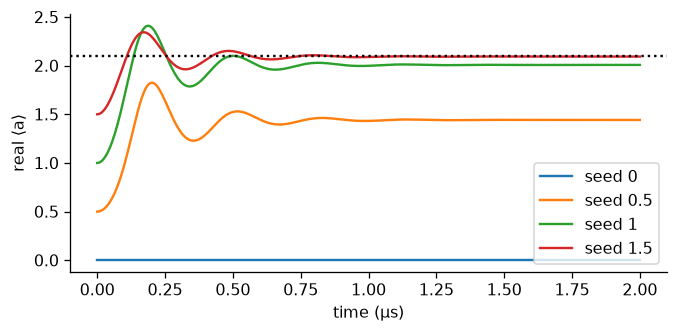

In [12]:
seed_rows = []
seed_runs = {}
target28 = np.asarray(dq.to_numpy(dq.coherent(28, alpha))).ravel()
for seed in [0.0, 0.5, 1.0, 1.5]:
    run = full_run(28, 10, inflate_t, seed=seed)
    seed_runs[seed] = run
    final_f = np.vdot(target28, run["rho"][-1] @ target28).real  # no square root convention ambiguity
    seed_rows.append({"seed amplitude": seed, "initial photons": seed**2,
                      "final real a": run["e"][2, -1].real, "final fidelity to +alpha": final_f})
table(pd.DataFrame(seed_rows), "logical_state_preparation")
fig, ax = plt.subplots(figsize=(6, 3))
for seed, run in seed_runs.items():
    ax.plot(inflate_t, run["e"][2].real, label=f"seed {seed:g}")
ax.axhline(alpha, color="black", ls=":")
ax.set(xlabel="time (μs)", ylabel="real ⟨a⟩")
ax.legend()
finish_figure(fig, "09_seeded_preparation")

2.1 — measure a slow bit decay, without mistaking it for a numerical floor

the prompt calls the decay of $\mathrm{Re}\langle a\rangle$ $\Gamma_X$.
a symmetric classical bit with single-event rate $r$ has imbalance
$e^{-2rt}$, so the prompt's $\Gamma_X=2r$. several papers quote $r$ instead.
the same factor-of-two issue appears for parity and phase flips.

short-time physics uses dynamiqs. for the very long, stiff small-cat decays i
also use qutip's sparse master-equation solver, with the *same* matrices, and
compare the fitted rates to slow eigenvalues of the full two-mode generator.
this is not adiabatic elimination. a spectral residual, cutoff changes, and
fit-window changes are reported; a pretty straight line is not enough.

In [13]:
def sparse_model(na, nb, amplitude, drive=0.0):
    h, jumps, ops, _, _ = two_mode(na, nb, amplitude, drive=drive)
    dims = [[na, nb], [na, nb]]  # keep tensor information for partial traces
    convert = lambda op: qt.Qobj(dq.to_numpy(op), dims=dims).to("csr")
    return convert(h), [convert(op) for op in jumps], [convert(op) for op in ops]


def slow_bit_mode(na, nb, amplitude, drive=0.0):
    h, jumps, ops = sparse_model(na, nb, amplitude, drive)
    generator = qt.liouvillian(h, jumps).data.as_scipy().tocsc()  # d² by d², but sparse
    vals, vecs = eigs(generator, k=6, sigma=1e-6, tol=1e-10, v0=np.ones(generator.shape[0], dtype=complex))
    d = na * nb
    candidates = []
    for i, value in enumerate(vals):
        rho_mode = vecs[:, i].reshape((d, d), order="F")  # qutip stacks columns
        trace = abs(np.trace(rho_mode))  # stationary mode has nonzero trace; decay modes do not
        overlap = abs(np.trace(ops[2].full() @ rho_mode))  # does this mode actually change the logical bit?
        if trace < 1e-4 and overlap > 1e-3 and value.real < -1e-12:
            candidates.append((value.real, i, overlap))
    if not candidates:
        raise RuntimeError("no resolved bit mode; enlarge the spectral search or precision")
    _, index, overlap = max(candidates)  # slowest decaying mode visible to a
    value = vals[index]
    residual = np.linalg.norm(generator @ vecs[:, index] - value * vecs[:, index])
    return {"rate": -value.real, "imaginary part": value.imag, "residual": residual, "a overlap": overlap}


def fit_decay(times, signal, start=0.0, offset=False):
    keep = np.asarray(times) >= start  # discard the fast adjustment to the metastable manifold
    t = np.asarray(times)[keep]
    y = np.asarray(signal).real[keep]
    scale_t = t[-1] - t[0]  # scale time so the optimizer handles very slow rates well
    x = (t - t[0]) / scale_t
    if offset:
        model = lambda x, amp, decay, floor: amp * np.exp(-decay * x) + floor
        guess = [y[0] - y[-1], 2.0, y[-1]]
        bounds = ([-2, 0, -1], [2, 100, 1])
    else:
        model = lambda x, amp, decay: amp * np.exp(-decay * x)
        guess = [y[0], 1.0]
        bounds = ([-10, 0], [10, 100])
    parameters, covariance = curve_fit(model, x, y, p0=guess, bounds=bounds, maxfev=20000, xtol=1e-12, ftol=1e-12, gtol=1e-12)
    prediction = model(x, *parameters)
    return {"rate": parameters[1] / scale_t, "rmse": np.sqrt(np.mean((prediction - y)**2)),
            "floor": parameters[2] if offset else 0.0, "fit t": t, "fit y": prediction}


def sparse_decay(na, nb, amplitude, times):
    h, jumps, ops = sparse_model(na, nb, amplitude)
    initial = qt.tensor(qt.coherent(na, amplitude), qt.basis(nb, 0))
    result = qt.mesolve(h, initial, times, jumps, e_ops=ops,
                       options={"method": "bdf", "rtol": 2e-8, "atol": 2e-10,
                                "nsteps": 2_000_000, "store_states": False})
    return np.asarray(result.expect)  # includes tails over the entire long run

alpha=0.6, fitted Γx=0.0132034/μs


alpha=0.8, fitted Γx=0.00642262/μs


alpha=1.0, fitted Γx=0.00230058/μs


alpha=1.2, fitted Γx=0.00059969/μs


alpha=1.4, fitted Γx=0.000119916/μs


,alpha,alpha²,fit rate,spectral rate,larger cutoff rate,fit rmse,window relative change,cutoff relative change,spectral residual,observed fraction of lifetime,memory tail,buffer tail
0,0.6,0.36,0.013203,0.013203,0.013203,5.300734e-14,4.085621e-13,1.667983e-08,3.550224e-12,1.320339,9.827247e-09,1.421238e-09
1,0.8,0.64,0.006423,0.006423,0.006423,5.053863e-14,2.944311e-13,1.160699e-06,4.414609e-12,0.642262,5.760691e-10,5.269760e-09
2,1.0,1.00,0.002301,0.002301,0.002301,7.367636e-12,8.256129e-11,3.125411e-05,2.014089e-13,0.230059,1.724726e-10,3.203882e-08
3,1.2,1.44,0.000600,0.000600,0.000600,7.326191e-14,9.103829e-14,4.213806e-04,7.168364e-15,0.059969,1.714535e-10,1.134167e-07
4,1.4,1.96,0.000120,0.000120,0.000120,1.063785e-14,1.406009e-10,2.805662e-03,9.179577e-15,0.011992,8.141938e-10,2.185148e-07


finite-range suppression exponent gamma = 2.9545


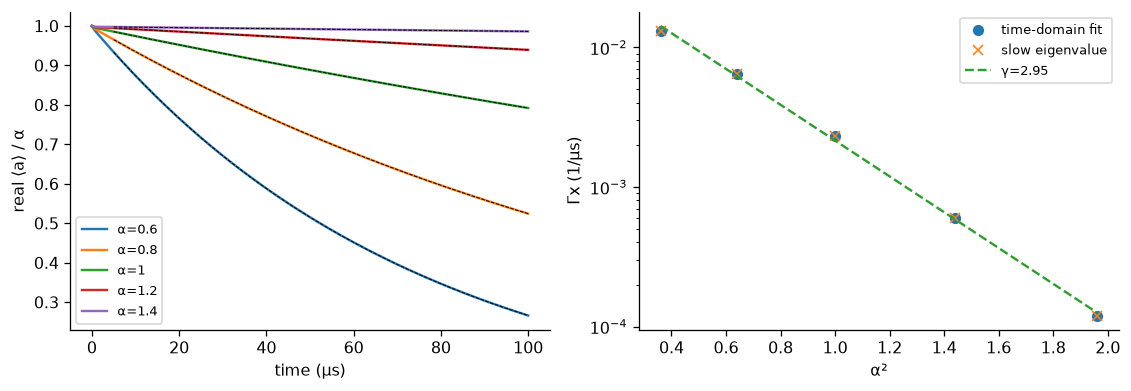

dynamiqs versus qutip: maximum observable difference = 3.302e-06


In [14]:
bit_rows = []
bit_traces = {}
for size in [0.6, 0.8, 1.0, 1.2, 1.4]:
    mode = slow_bit_mode(18, 4, size)  # low buffer occupation here, unlike vacuum inflation
    end = min(100.0, 1.5 / mode["rate"])  # finite early decay is resolvable; don't simulate experimental seconds
    times = np.linspace(0, end, 161)
    signal = sparse_decay(18, 4, size, times)
    fit = fit_decay(times, signal[2].real, start=max(2.0, 0.05 * end))
    later = fit_decay(times, signal[2].real, start=0.3 * end)  # test sensitivity to the fitting window
    check_mode = slow_bit_mode(22, 5, size)  # rates, not only photon numbers, need cutoff tests
    bit_rows.append({"alpha": size, "alpha²": size**2, "fit rate": fit["rate"], "spectral rate": mode["rate"],
                     "larger cutoff rate": check_mode["rate"], "fit rmse": fit["rmse"],
                     "window relative change": abs(later["rate"] / fit["rate"] - 1),
                     "cutoff relative change": abs(check_mode["rate"] / mode["rate"] - 1),
                     "spectral residual": mode["residual"], "observed fraction of lifetime": end * mode["rate"],
                     "memory tail": signal[5].real.max(), "buffer tail": signal[6].real.max()})
    bit_traces[size] = (times, signal, fit)
    print(f"alpha={size:.1f}, fitted Γx={fit['rate']:.6g}/μs", flush=True)
bit_table = pd.DataFrame(bit_rows)
table(bit_table, "bit_flip_rates")
log_slope, log_intercept = np.polyfit(bit_table["alpha²"], np.log(bit_table["fit rate"]), 1)
print(f"finite-range suppression exponent gamma = {-log_slope:.4f}")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for size, (times, signal, fit) in bit_traces.items():
    axes[0].plot(times, signal[2].real / size, label=f"α={size:g}")
    axes[0].plot(fit["fit t"], fit["fit y"] / size, "--", color="black", lw=0.6)
axes[0].set(xlabel="time (μs)", ylabel="real ⟨a⟩ / α")
axes[0].legend(fontsize=8)
axes[1].semilogy(bit_table["alpha²"], bit_table["fit rate"], "o", label="time-domain fit")
axes[1].semilogy(bit_table["alpha²"], bit_table["spectral rate"], "x", label="slow eigenvalue")
axes[1].semilogy(bit_table["alpha²"], np.exp(log_intercept + log_slope * bit_table["alpha²"]), "--", label=f"γ={-log_slope:.2f}")
axes[1].set(xlabel="α²", ylabel="Γx (1/μs)")
axes[1].legend(fontsize=8)
finish_figure(fig, "10_bit_flip_scaling")
cross_t = np.linspace(0, 4, 101)  # independent solver comparison on a common short window
cross_dq = full_run(18, 4, cross_t, amplitude=1.0, seed=1.0)
cross_qt = sparse_decay(18, 4, 1.0, cross_t)
cross_error = np.max(abs(cross_dq["e"] - cross_qt))
print(f"dynamiqs versus qutip: maximum observable difference = {cross_error:.3e}")
assert cross_error < 2e-5

the naive matrix element is
$|\langle-\alpha|a|\alpha\rangle|^2=\alpha^2e^{-4\alpha^2}$.
it ignores excursions outside the code space and the way stabilization
returns that leaked probability. [dubovitskii, 2025](https://arxiv.org/abs/2407.17299)
finds a second-order single-loss contribution proportional to
$(\kappa_a^2/2\kappa_2)e^{-2\alpha^2}$ in the eliminated model's *event-rate*
convention. that term can dominate even without thermal photons.

so neither an exponent of exactly 2 nor a pure exponential over all sizes is
required here. the prefactor, finite fitting interval, and two-mode dynamics
matter. this also corrects the draft prompt's suggestion that zero temperature
alone explains every exponent above 2. the small-cat fit is not an extrapolation
of hardware lifetimes at α=2.1.

2.2 — phase flips are fast enough to watch directly

each lost photon changes parity. approximately independent jumps at rate
$\kappa_a\alpha^2$ give $\Gamma_Z=2\kappa_a\alpha^2$ for the parity decay.
i fit an offset as well: at smaller cats the limiting parity is not exactly
zero. imposing a zero floor there biases the fitted rate.

,alpha,alpha²,fitted Γz,2 ka alpha²,fitted parity floor,fit rmse,memory tail,buffer tail
0,1.2,1.44,0.168535,0.168289,0.114963,7.248898e-07,9.101355e-08,8.338222e-08
1,1.5,2.25,0.262159,0.262951,0.023115,9.662618e-07,1.126569e-07,1.343325e-07
2,1.8,3.24,0.377812,0.378650,0.003239,7.835360e-07,3.689268e-09,1.763217e-07
3,2.1,4.41,0.514557,0.515385,0.000317,9.111685e-07,4.874473e-09,1.292988e-07
4,2.4,5.76,0.672334,0.673155,0.000022,1.117763e-06,4.532535e-09,8.475570e-08


fitted slope 0.116684; predicted 2ka = 0.116867; intercept 1.87e-05


largest-cat Γz cutoff change: 9.332e-07


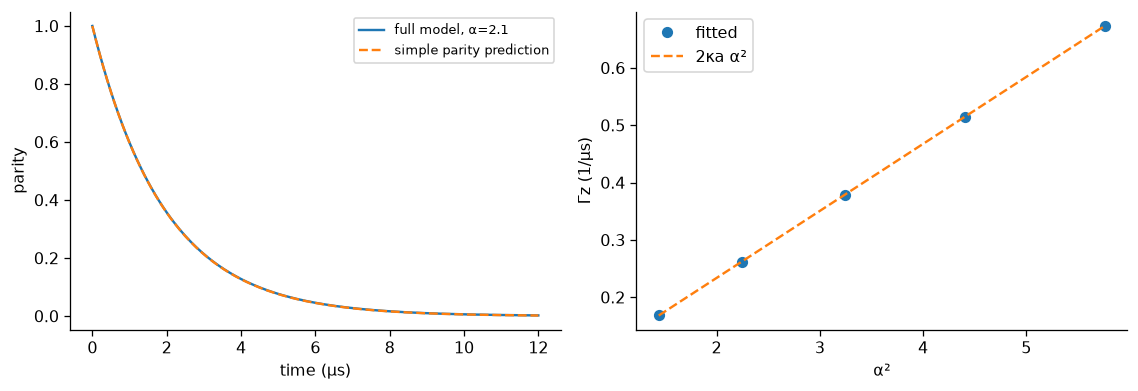

In [15]:
phase_rows = []
phase_traces = {}
phase_t = np.linspace(0, 12, 241)  # includes several lifetimes at the physical target
for size in [1.2, 1.5, 1.8, 2.1, 2.4]:
    run = full_run(32, 5, phase_t, amplitude=size, even=True)
    fit = fit_decay(phase_t, run["e"][4].real, start=0.3, offset=True)
    phase_traces[size] = run
    phase_rows.append({"alpha": size, "alpha²": size**2, "fitted Γz": fit["rate"],
                       "2 ka alpha²": 2 * ka * size**2, "fitted parity floor": fit["floor"],
                       "fit rmse": fit["rmse"], "memory tail": run["e"][5].real.max(),
                       "buffer tail": run["e"][6].real.max()})
phase_table = pd.DataFrame(phase_rows)
table(phase_table, "phase_flip_rates")
phase_slope, phase_intercept = np.polyfit(phase_table["alpha²"], phase_table["fitted Γz"], 1)
print(f"fitted slope {phase_slope:.6f}; predicted 2ka = {2*ka:.6f}; intercept {phase_intercept:.3g}")
phase_check = full_run(36, 7, phase_t, amplitude=2.4, even=True)  # largest cat is the demanding endpoint
phase_check_fit = fit_decay(phase_t, phase_check["e"][4].real, start=0.3, offset=True)
print(f"largest-cat Γz cutoff change: {abs(phase_check_fit['rate']/phase_rows[-1]['fitted Γz']-1):.3e}")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(phase_t, phase_traces[2.1]["e"][4].real, label="full model, α=2.1")
axes[0].plot(phase_t, np.exp(-2 * ka * alpha**2 * phase_t), "--", label="simple parity prediction")
axes[0].set(xlabel="time (μs)", ylabel="parity")
axes[0].legend(fontsize=8)
axes[1].plot(phase_table["alpha²"], phase_table["fitted Γz"], "o", label="fitted")
axes[1].plot(phase_table["alpha²"], phase_table["2 ka alpha²"], "--", label="2κa α²")
axes[1].set(xlabel="α²", ylabel="Γz (1/μs)")
axes[1].legend()
finish_figure(fig, "11_phase_flip_scaling")

2.3 — ask the buffer which well the memory occupies

a weak real memory drive pushes the memory in its imaginary quadrature.
the two wells convert that displacement into opposite real buffer amplitudes.
the buffer also has a small *common imaginary* displacement from memory loss;
it is the difference between the two output signals that carries the bit.
'steady' here means a metastable measurement plateau, before rare bit flips
eventually erase the initial sign. it is not two different infinite-time
steady states of a mixing lindblad equation.

contrast plateau -0.047576; linear estimate -0.047619
2% settling time within the 3 μs window: 0.815 μs
linearized ringing period: 0.319 μs


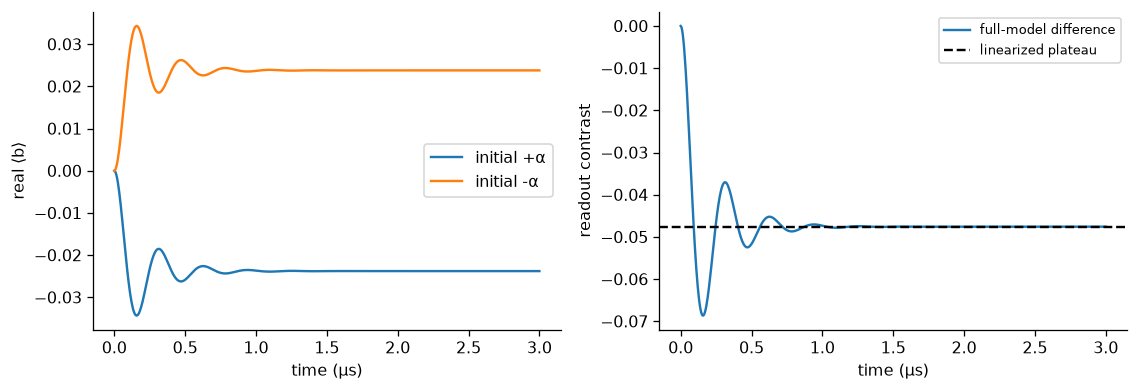

In [16]:
weak_drive = 0.1 * g2  # comfortably smaller than the exchange coupling
read_t = np.linspace(0, 3, 601)  # resolves the underdamped oscillation
read_plus = full_run(28, 6, read_t, seed=alpha, drive=weak_drive)
read_minus = full_run(28, 6, read_t, seed=-alpha, drive=weak_drive)
contrast = read_plus["e"][3] - read_minus["e"][3]  # common buffer offset cancels
linear_contrast = -weak_drive / (alpha * g2)  # twice the single-well displacement
plateau = np.mean(contrast[read_t > 2.0].real)
outside = np.flatnonzero(abs(contrast.real - plateau) > 0.02 * abs(plateau))
settling_time = read_t[outside[-1] + 1] if outside[-1] + 1 < len(read_t) else np.nan
print(f"contrast plateau {plateau:.6f}; linear estimate {linear_contrast:.6f}")
print(f"2% settling time within the 3 μs window: {settling_time:.3f} μs")
omega = 2 * g2 * alpha  # local memory-buffer exchange frequency
print(f"linearized ringing period: {2*np.pi/np.sqrt(omega**2-(kb/4)**2):.3f} μs")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(read_t, read_plus["e"][3].real, label="initial +α")
axes[0].plot(read_t, read_minus["e"][3].real, label="initial -α")
axes[0].set(xlabel="time (μs)", ylabel="real ⟨b⟩")
axes[0].legend()
axes[1].plot(read_t, contrast.real, label="full-model difference")
axes[1].axhline(linear_contrast, ls="--", color="black", label="linearized plateau")
axes[1].set(xlabel="time (μs)", ylabel="readout contrast")
axes[1].legend(fontsize=8)
finish_figure(fig, "12_buffer_readout")

2.4a — put the drive back into the circuit

one concrete implementation is a capacitive memory port:
$H_{\mathrm{port}}=2\epsilon_Z(t)\cos(\omega_a t+\theta)(a+a^\dagger)$.
in the rotating frame its resonant part is
$\epsilon_Z(t)(e^{i\theta}a+e^{-i\theta}a^\dagger)$; there are also terms
oscillating at $2\omega_a$. choosing $\theta=0$ gives the requested drive.
this is an explicit extra control port, just as the problem already permits a
separate capacitive buffer drive. it is not secretly another flux pump.

an alternative flux pump at $\omega_a$ has additional resonant cubic terms.
writing its amplitude as $\epsilon_r$, the first-order rotating-wave result is

$$E_J\epsilon_r\varphi_a\left[\left(1-\frac{\varphi_a^2}{2}
-\frac{\varphi_b^2}{2}\right)(a+a^\dagger)
-\frac{\varphi_a^2}{2}(a^\dagger a^2+a^{\dagger2}a)
-\varphi_b^2(a+a^\dagger)n_b\right].$$

this follows from the resonant part of $X_a^3$, which is
$3(a^\dagger a^2+a)+\mathrm{h.c.}$, and the dc part of $X_b^2=2n_b+1$.
stronger flux readout therefore does not scale a clean linear drive alone.
the numerical protocol below chooses the capacitive implementation to avoid
those specific resonant cubic readout terms.

there is a sign inconsistency worth making explicit in the supplied draft:
at its stated +π/2 differential bias, the cubic term of
$+2E_J\epsilon_p\cos(\omega_pt)\sin\varphi$ gives *negative* resonant g₂.
the quoted positive formula is its magnitude. reversing the pump phase gives
our positive-g₂ convention; the buffer-drive phase must be calibrated with it.
the workshop slide's opposite differential bias also reverses this sign.

for the stabilizing pump, the cubic rotating-wave term is the intended
$a^2b^\dagger+\mathrm{h.c.}$, but fifth and higher odd orders dress its fock-state
matrix elements. at fifth order the forward matrix element is multiplied by

$$1-\frac{\varphi_a^2}{6}(2n_a-1)-\frac{\varphi_b^2}{2}(n_b+1).$$

below i keep the *entire sine*, then retain exactly resonant matrix elements.
this checks the small-phase expansion without resolving GHz time steps. it
does not include second-order virtual off-resonant shifts, pump-induced changes
to dissipators, thermal noise, or a real measurement amplifier. those are
limitations, not effects this rotating-wave calculation has verified away.

In [17]:
wa, wb, ej = 2 * np.pi * np.array([4000.0, 4800.0, 40000.0])  # ghz converted to mhz, then angular units
phia, phib = 0.06, 0.3  # zero-point phase fluctuations from the circuit table
eps_p = 2 * g2 / (ej * phia**2 * phib)  # magnitude; use the pump phase discussed above
print(f"required pump amplitude = {eps_p:.8f} rad; pump frequency / 2π = {(2*wa-wb)/(2*np.pi):.1f} MHz")


def sine_exchange(na, nb, calibrate=True, order=None):
    aa = qt.tensor(qt.destroy(na + 8), qt.qeye(nb + 8))  # padding avoids boundary errors in the sine
    bb = qt.tensor(qt.qeye(na + 8), qt.destroy(nb + 8))
    phase = phia * (aa + aa.dag()) + phib * (bb + bb.dag())
    if order is None:
        da = qt.displace(na + 8, 1j * phia).full()[:na, :na]  # exp(i phi_a X_a)
        db = qt.displace(nb + 8, 1j * phib).full()[:nb, :nb]
        displacement = np.kron(da, db)  # commuting mode operators factorize exactly
        sine = (displacement - displacement.conj().T) / (2j)
    else:
        series = phase - phase**3 / 6  # cubic comparison
        if order >= 5:
            series = series + phase**5 / 120
        keep = np.array([i * (nb + 8) + j for i in range(na) for j in range(nb)])
        sine = series.full()[np.ix_(keep, keep)]  # crop only after expanding in the padded space
    energy = np.array([wa * i + wb * j for i in range(na) for j in range(nb)])
    resonant = np.isclose(abs(energy[:, None] - energy[None, :]), 2 * wa - wb, atol=1e-6, rtol=0)
    exchange = -ej * eps_p * sine * resonant  # minus = chosen π pump-phase shift; cos supplies 1/2
    raw_g = exchange[1, 2 * nb].real / np.sqrt(2)  # |2,0> -> |0,1> low-occupancy calibration
    if calibrate:
        exchange = exchange * g2 / raw_g  # separate a recalibratable g shift from number dependence
    return dq.asqarray(exchange, dims=(na, nb), layout=dq.dia), raw_g


exact_exchange, raw_g = sine_exchange(28, 6, calibrate=False)
cubic_exchange, _ = sine_exchange(28, 6, calibrate=False, order=3)
fifth_exchange, _ = sine_exchange(28, 6, calibrate=False, order=5)
entry_rows = []
for memory_n, buffer_n in [(2, 0), (5, 0), (10, 0), (5, 1), (10, 3)]:
    row, column = (memory_n - 2) * 6 + buffer_n + 1, memory_n * 6 + buffer_n
    cubic = dq.to_numpy(cubic_exchange)[row, column].real
    entry_rows.append({"initial memory n": memory_n, "initial buffer n": buffer_n,
                       "exact/cubic": dq.to_numpy(exact_exchange)[row, column].real / cubic,
                       "fifth/cubic": dq.to_numpy(fifth_exchange)[row, column].real / cubic})
table(pd.DataFrame(entry_rows), "circuit_matrix_elements")
print(f"uncalibrated low-occupancy coupling shift: {100*(raw_g/g2-1):.3f}%")

required pump amplitude = 0.03532407 rad; pump frequency / 2π = 3200.0 MHz


,initial memory n,initial buffer n,exact/cubic,fifth/cubic
0,2,0,0.954278,0.9532
1,5,0,0.950846,0.9496
2,10,0,0.945146,0.9436
3,5,1,0.908058,0.9046
4,10,3,0.821350,0.8086


uncalibrated low-occupancy coupling shift: -4.572%


2.4b — measure the contrast/error trade-off

increasing εz increases the coherent buffer separation but also perturbs the
protected manifold. the sweep uses α=1.2 so Γx remains independently resolvable;
it does not pretend these are the target-size rates. the physical-size pulse
comparison follows separately. all points use the same loss and exchange rates.

,drive/g2,contrast at 2.5–3 us,Γx,larger-cutoff Γx,relative cutoff change,spectral residual
0,0.00,0.000000,0.000600,0.000600,0.000421,7.168364e-15
1,0.05,0.040448,0.003158,0.003168,0.003270,1.372495e-13
2,0.10,0.079267,0.010920,0.010959,0.003552,1.755282e-12
3,0.20,0.145594,0.043618,0.043739,0.002768,2.813113e-11
4,0.40,0.192245,0.208040,0.207910,0.000625,1.112278e-09


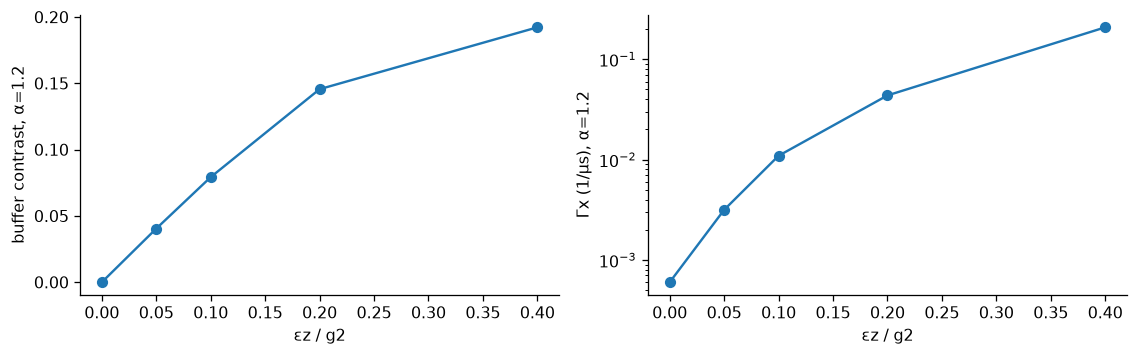

In [18]:
drive_rows = []
for fraction in [0.0, 0.05, 0.1, 0.2, 0.4]:
    drive = fraction * g2
    mode = slow_bit_mode(18, 4, 1.2, drive=drive)
    larger = slow_bit_mode(22, 5, 1.2, drive=drive)
    run = full_run(22, 5, np.linspace(0, 3, 301), amplitude=1.2, seed=1.2, drive=drive)
    contrast_here = 2 * abs(np.mean(run["e"][3, -51:].real))  # exact sign symmetry gives the other branch
    drive_rows.append({"drive/g2": fraction, "contrast at 2.5–3 us": contrast_here,
                       "Γx": mode["rate"], "larger-cutoff Γx": larger["rate"],
                       "relative cutoff change": abs(larger["rate"] / mode["rate"] - 1),
                       "spectral residual": mode["residual"]})
drive_table = pd.DataFrame(drive_rows)
table(drive_table, "dc_readout_tradeoff")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(drive_table["drive/g2"], drive_table["contrast at 2.5–3 us"], "o-")
axes[0].set(xlabel="εz / g2", ylabel="buffer contrast, α=1.2")
axes[1].semilogy(drive_table["drive/g2"], drive_table["Γx"], "o-")
axes[1].set(xlabel="εz / g2", ylabel="Γx (1/μs), α=1.2")
finish_figure(fig, "13_dc_tradeoff")

2.4c — an experiment: use the transient, then listen during ringdown

near either well the real buffer signal obeys
$\ddot b+(\kappa_b/2)\dot b+\Omega^2b=\mp\Omega\epsilon_Z(t)$,
where $\Omega=2g_2\alpha$. this is an underdamped filter, not an instantaneous
displacement. a receiver that averages a changing-sign signal can throw away
information. a matched filter weights the recorded quadrature by its predicted
time-dependent difference, including the passive ringdown after the drive ends.

i compare a constant drive, a short pulse with passive listening, and a smooth
resonant pulse. these are candidates, not assumed winners. they have the same
maximum memory-drive amplitude and the same total observation/recovery time.
a second comparison later rescales amplitudes to equal measured information.

for ideal homodyne detection,
$dY=2\sqrt{\eta\kappa_b}\mathrm{Re}\langle b\rangle dt+dW$.
assuming shot-noise-limited, approximately coherent output, define
$\mathcal I=\eta\kappa_b\int[\mathrm{Re}(b_+-b_-)]^2dt$.
then $\mathrm{SNR}^2=4\mathcal I$ (separation over one standard deviation) and
$P_{\mathrm{assignment}}\simeq\frac12\mathrm{erfc}(\sqrt{\mathcal I/2})$.
this is a mean-signal information proxy, not a stochastic-trajectory validation
of assignment error. it excludes excess output noise and amplifier effects.

a finite pulse has no stationary Γx. after the drive, i let stabilization recover
the state, then report the wrong orthogonal-codeword population and residual
leakage separately. i do not rename temporary displacement as a logical flip.

In [19]:
def pulse_run(na, nb, waveform, total=3.0, amplitude=alpha, corrected=False, sign=1, tolerance=2e-10):
    h, jumps, ops, a, b = two_mode(na, nb, amplitude)
    if corrected:
        exchange, _ = sine_exchange(na, nb, calibrate=True)  # include all resonant odd-phase orders
        h = exchange - g2 * amplitude**2 * (b + b.dag())
    h = h + dq.modulated(waveform, a + a.dag(), discontinuity_ts=[np.pi / omega, 1.5])  # known pulse edges
    times = np.linspace(0, total, int(total * 400) + 1)  # 2.5 ns output grid, independently of solver steps
    initial = dq.tensor(dq.coherent(na, sign * amplitude), dq.fock(nb, 0))
    run = evolve(h, jumps, initial, times, ops, (na, nb), rtol=100*tolerance, atol=tolerance)
    even = np.asarray(dq.to_numpy(cat_ket(na, amplitude, 1))).ravel()
    odd = np.asarray(dq.to_numpy(cat_ket(na, amplitude, -1))).ravel()
    wrong = (even - sign * odd) / np.sqrt(2)  # orthogonal logical basis; coherent wells only approximate it
    rho = run["rho"][-1]
    p_wrong = np.vdot(wrong, rho @ wrong).real
    in_code = np.vdot(even, rho @ even).real + np.vdot(odd, rho @ odd).real
    difference = 2 * run["e"][3].real  # opposite branch checked explicitly below
    information = kb * cumulative_trapezoid(difference**2, times, initial=0)  # eta=1; scale linearly for other efficiencies
    run.update({"wrong": p_wrong, "leakage": 1-in_code, "information": information,
                "box information": kb * np.trapezoid(difference, times)**2 / total})
    return run


def waveform_family(kind, peak, duration=1.5):
    if kind == "constant":
        return lambda t: jnp.where(t < duration, peak, 0.0)  # explicit discontinuity tested with tighter tolerance
    if kind == "short pulse":
        return lambda t: jnp.where(t < np.pi / omega, peak, 0.0)  # roughly half a local exchange cycle
    if kind == "resonant":
        return lambda t: jnp.where(t < duration, peak * jnp.sin(np.pi*t/duration)**2 * jnp.cos(omega*t), 0.0)
    raise ValueError(kind)

,pulse,peak limit/g2,matched information,unweighted information,wrong codeword,residual leakage,information/wrong
0,constant,0.5,1.445384,6.911788e-01,0.000697,0.000009,2073.547547
1,short pulse,0.5,0.242890,7.520205e-03,0.000083,0.000008,2912.367166
2,resonant,0.5,0.989814,4.039736e-07,0.000329,0.000008,3007.034413


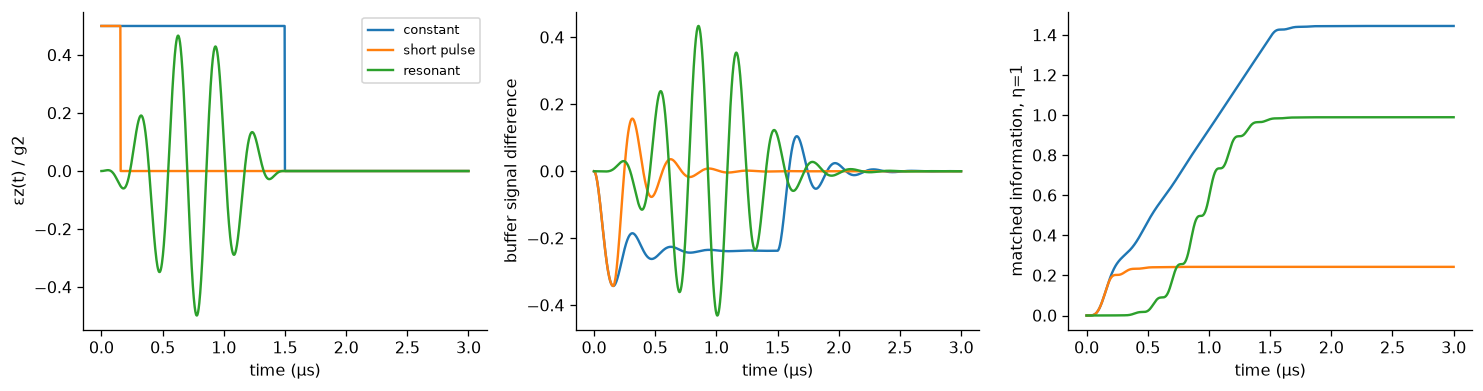

In [20]:
candidate_peak = 0.5 * g2  # explicit common hardware amplitude limit
candidate_runs = {}
candidate_rows = []
for kind in ["constant", "short pulse", "resonant"]:
    run = pulse_run(28, 6, waveform_family(kind, candidate_peak))
    candidate_runs[kind] = run
    candidate_rows.append({"pulse": kind, "peak limit/g2": 0.5, "matched information": run["information"][-1],
                           "unweighted information": run["box information"], "wrong codeword": run["wrong"],
                           "residual leakage": run["leakage"], "information/wrong": run["information"][-1]/run["wrong"]})
table(pd.DataFrame(candidate_rows), "pulse_candidates")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for kind, run in candidate_runs.items():
    waveform = waveform_family(kind, candidate_peak)
    axes[0].plot(run["t"], np.asarray(jax.vmap(waveform)(jnp.asarray(run["t"])))/g2, label=kind)
    axes[1].plot(run["t"], 2 * run["e"][3].real, label=kind)
    axes[2].plot(run["t"], run["information"], label=kind)
axes[0].set(ylabel="εz(t) / g2")
axes[1].set(ylabel="buffer signal difference")
axes[2].set(ylabel="matched information, η=1")
for axis in axes:
    axis.set(xlabel="time (μs)")
axes[0].legend(fontsize=8)
finish_figure(fig, "14_transient_pulse_candidates")

same peak is useful engineering context, but not a fair information/error
comparison by itself: the waveforms deliver different amounts of information.
next i match the two informative long pulses to the same measured $\mathcal I$,
keeping the same 3 μs total protocol and never exceeding the shared peak limit.
amplitude rescaling uses the quadratic small-signal prediction and then checks
the full nonlinear master equation again. no result is selected by ignoring
unsuccessful candidates.

In [21]:
target_information = 0.8 * min(candidate_runs[k]["information"][-1] for k in ["constant", "resonant"])
matched_runs = {}
matched_amplitudes = {}
for kind in ["constant", "resonant"]:
    peak = candidate_peak * np.sqrt(target_information / candidate_runs[kind]["information"][-1])
    for iteration in range(2):
        run = pulse_run(28, 6, waveform_family(kind, peak))
        if iteration == 0:
            peak *= np.sqrt(target_information / run["information"][-1])  # one nonlinear correction, then a fresh solve
    assert peak <= candidate_peak * (1+1e-8)
    assert abs(run["information"][-1]/target_information-1) < 0.01  # explicit 1% equal-information criterion
    matched_runs[kind] = run
    matched_amplitudes[kind] = peak
idle_pulse = pulse_run(28, 6, lambda t: 0.0 * t)  # same 3 μs, no readout drive
matched_rows = []
for kind, run in matched_runs.items():
    matched_rows.append({"pulse": kind, "peak/g2": matched_amplitudes[kind]/g2,
                         "information": run["information"][-1], "wrong codeword": run["wrong"],
                         "excess over idle": run["wrong"]-idle_pulse["wrong"], "leakage": run["leakage"],
                         "effective 2p/T": 2*run["wrong"]/3, "gaussian assignment estimate, eta=1": 0.5*erfc(np.sqrt(run["information"][-1]/2))})
matched_table = pd.DataFrame(matched_rows)
table(matched_table, "equal_information_comparison")
relative_reduction = 1 - matched_runs["resonant"]["wrong"] / matched_runs["constant"]["wrong"]
print(f"recovered wrong-codeword reduction at matched information: {100*relative_reduction:.2f}%")
print(f"idle wrong-codeword population: {idle_pulse['wrong']:.3e}")
print("2p/T is a protocol comparison, not a stationary Γx measurement.")
opposite_pulse = pulse_run(28, 6, waveform_family("resonant", matched_amplitudes["resonant"]), sign=-1)
sign_error = np.max(abs(opposite_pulse["e"][3].real + matched_runs["resonant"]["e"][3].real))
print(f"explicit opposite-codeword symmetry error: {sign_error:.3e}")
assert sign_error < 1e-6

,pulse,peak/g2,information,wrong codeword,excess over idle,leakage,effective 2p/T,"gaussian assignment estimate, eta=1"
0,constant,0.369756,0.791854,0.000317,0.000317,0.000008,0.000212,0.186770
1,resonant,0.446728,0.791866,0.000252,0.000252,0.000008,0.000168,0.186768


recovered wrong-codeword reduction at matched information: 20.43%
idle wrong-codeword population: 5.146e-07
2p/T is a protocol comparison, not a stationary Γx measurement.


explicit opposite-codeword symmetry error: 0.000e+00


2.4d — try to break the apparent improvement

readout starts near a well, so it does not need the same buffer cutoff as
vacuum inflation. that is a reason to test smaller cutoffs, not permission to
assume they work. the checks below vary the memory and buffer separately, then
increase both, tighten the solver, and add the calibrated sine-rwa correction.
frequency mistuning tests whether the result depends on hitting one exact number.
the carrier is still at ωa; these few-mhz envelope sidebands are far below GHz.

In [22]:
robust_rows = []
for label, na, nb, corrected, atol in [
    ("smaller memory", 24, 6, False, 2e-10),
    ("smaller buffer", 28, 4, False, 2e-10),
    ("larger cutoffs + tighter solver", 32, 8, False, 2e-11),
    ("calibrated full sine, rwa", 28, 6, True, 2e-10),
]:
    pair = {}
    for kind in ["constant", "resonant"]:
        run = pulse_run(na, nb, waveform_family(kind, matched_amplitudes[kind]), corrected=corrected, tolerance=atol)
        pair[kind] = run
        robust_rows.append({"check": label, "pulse": kind, "information": run["information"][-1],
                            "wrong codeword": run["wrong"], "leakage": run["leakage"],
                            "max memory tail": run["e"][5].real.max(), "max buffer tail": run["e"][6].real.max(),
                            "min reduced eigenvalue": checks(run)["min eigenvalue"]})
    print(f"{label}: information ratios to nominal = "
          f"{pair['constant']['information'][-1]/target_information:.3f}, "
          f"{pair['resonant']['information'][-1]/target_information:.3f}; "
          f"wrong-codeword ratio resonant/constant = {pair['resonant']['wrong']/pair['constant']['wrong']:.3f}")
robust_table = pd.DataFrame(robust_rows)
table(robust_table, "readout_robustness")
mistuning_rows = []
for factor in [0.9, 1.0, 1.1]:
    envelope = lambda t: jnp.where(t < 1.5, matched_amplitudes["resonant"] * jnp.sin(np.pi*t/1.5)**2 * jnp.cos(factor*omega*t), 0.0)
    run = pulse_run(28, 6, envelope)
    mistuning_rows.append({"envelope frequency/nominal": factor, "information": run["information"][-1],
                           "wrong codeword": run["wrong"], "information/wrong": run["information"][-1]/run["wrong"]})
table(pd.DataFrame(mistuning_rows), "envelope_mistuning")

smaller memory: information ratios to nominal = 1.000, 1.000; wrong-codeword ratio resonant/constant = 0.794


smaller buffer: information ratios to nominal = 1.000, 1.000; wrong-codeword ratio resonant/constant = 0.864


larger cutoffs + tighter solver: information ratios to nominal = 1.000, 1.000; wrong-codeword ratio resonant/constant = 0.794


calibrated full sine, rwa: information ratios to nominal = 1.010, 0.969; wrong-codeword ratio resonant/constant = 0.641


,check,pulse,information,wrong codeword,leakage,max memory tail,max buffer tail,min reduced eigenvalue
0,smaller memory,constant,0.791853,0.000318,0.000009,1.090045e-07,0.000013,-1.675527e-08
1,smaller memory,resonant,0.791867,0.000253,0.000008,1.250873e-07,0.000023,-1.279383e-08
2,smaller buffer,constant,0.791968,0.000383,0.000009,1.419440e-08,0.000176,-5.077094e-08
3,smaller buffer,resonant,0.791716,0.000331,0.000008,1.160672e-08,0.000366,-3.969575e-08
4,larger cutoffs + tighter solver,constant,0.791859,0.000307,0.000008,2.040036e-08,0.000002,-7.047004e-08
5,larger cutoffs + tighter solver,resonant,0.791814,0.000244,0.000008,3.658362e-10,0.000003,-2.089669e-09
6,"calibrated full sine, rwa",constant,0.799959,0.000354,0.000026,6.421473e-09,0.000020,-1.266514e-08
7,"calibrated full sine, rwa",resonant,0.767679,0.000227,0.000025,5.971562e-09,0.000031,-1.278330e-08


,envelope frequency/nominal,information,wrong codeword,information/wrong
0,0.9,0.789361,0.000257,3069.778996
1,1.0,0.791866,0.000252,3136.763619
2,1.1,0.672932,0.000206,3261.493663


what this does and does not establish

the proposal is an underdamped, sideband-shaped readout with a matched temporal
receiver. the local transfer function motivates its frequency; the two-mode
nonlinear simulations decide whether it helps. the primary comparison is
information per recovered logical-bit disturbance, not peak buffer amplitude.
no new nonlinearity or extra stabilization pump is assumed. an iq-capable memory
drive and time-resolved homodyne processing are required.

the drive is still disturbing: a favorable comparison against constant readout
does not mean the idle Γx was preserved. neither does it prove a high-fidelity
single-shot hardware measurement. the reported gaussian assignment estimate
is only a shot-noise proxy, and the example information budget is modest.
a further experiment should simulate conditional measurement records, include
realistic detection efficiency and output noise, and optimize a target error
budget with the full calibrated circuit and bath model.

the full-sine check is first order in pump amplitude and rotating-wave only.
at the supplied illustrative circuit parameters, neglecting the higher odd
powers without calibration would already shift the low-occupancy coupling by
several percent. the off-resonant linear pump term should first be handled by
a displacement/calibration; virtual shifts and transformed dissipation need a
controlled effective-model calculation, not an unsupported blanket 'rwa is fine'.

the introductory reference had a small negative density eigenvalue at the
explicit integrator's tolerance. inspect the printed diagnostic: this numerical
violation is tiny compared with the introductory observable tolerance, but
would be unacceptable as an unreported floor for rare-error claims. readout
has its own tighter-tolerance and cutoff checks above.

this is a numerically tested proposal within the stated model, not a claim
that no one has used resonant readout or matched filtering before.

In [23]:
summary = {"versions": versions, "time_unit": "microsecond", "rates": "expectation-value decay rates",
           "bit_suppression_exponent": float(-log_slope), "phase_slope": float(phase_slope),
           "predicted_phase_slope": float(2*ka), "matched_information": float(target_information),
           "wrong_codeword_reduction_fraction": float(relative_reduction),
           "constant_wrong_codeword": float(matched_runs["constant"]["wrong"]),
           "resonant_wrong_codeword": float(matched_runs["resonant"]["wrong"]),
           "caveat": "finite-pulse ideal-model benchmark; not a stationary rate or hardware measurement fidelity"}
(artifacts / "summary.json").write_text(json.dumps(summary, indent=2))  # actual results only
display(pd.Series({key: value for key, value in summary.items() if key != "versions"}))
print("the plots, tables, and this summary were generated by the cells above.")

time_unit                                                                  microsecond
rates                                                    expectation-value decay rates
bit_suppression_exponent                                                      2.954541
phase_slope                                                                   0.116684
predicted_phase_slope                                                         0.116867
matched_information                                                           0.791851
wrong_codeword_reduction_fraction                                             0.204336
constant_wrong_codeword                                                       0.000317
resonant_wrong_codeword                                                       0.000252
caveat                               finite-pulse ideal-model benchmark; not a stat...
dtype: object

the plots, tables, and this summary were generated by the cells above.


sources and further checks

- supplied `duquantum_2026_challenge_prompt-v4.md` and `2026-10-24 DuQuantun Hackathon.pdf`:
  task definitions, circuit parameters, sign conventions, and workshop context.
- [réglade, bocquet et al., 2024](https://arxiv.org/abs/2307.06617): the two-mode
  experiment, its nonadiabatic regime, circuit derivation, and buffer readout.
- [dubovitskii, 2025](https://arxiv.org/abs/2407.17299): second-order bit-flip
  mechanisms; its event-rate convention differs by a factor of two here.
- [guillaud, cohen, mirrahimi, lecture notes](https://arxiv.org/abs/2203.03222):
  dissipative cats and the protected-manifold viewpoint.
- [gautier et al., zeno gates](https://doi.org/10.1103/PRXQuantum.4.040316):
  nonadiabatic control and information leakage; gate protection is not the
  same objective as making leaked information useful for readout.
- [carde et al., flux-pump degradation](https://arxiv.org/abs/2410.00975): why
  circuit-level corrections can involve dissipators, not just extra hamiltonian terms.
- [rousseau et al., moon cats](https://arxiv.org/abs/2502.07892): squeezing is
  an existing stabilization strategy, not an original discovery of this notebook.
- [dynamiqs solver documentation](https://www.dynamiqs.org/stable/python_api/integrators/mesolve.html)
  and [official challenge tutorials](https://github.com/YQuantum-2026/Alice-Bob-Challenge/tree/main/challenge/resources).

the prior psiteratops submission supplied as context studies a different drift
optimization problem. its results are not evidence for this readout proposal.

one last numerical check — resolve the inflation reference's precision floor

the large (40,16) reference is expensive, and its earlier explicit-solver run
had small negative density eigenvalues. here the same full model is rerun with
1000 times tighter absolute tolerance. this distinguishes genuine fock tails
from numerical noise. the signed tail plot intentionally shows negative values
instead of silently putting them on a positive logarithmic axis.

this also estimates the coherence decay time from the *inflation data itself*.
it is a late-time exponential envelope fit, not a claim that coherence suddenly
disappears at one particular time. optional cached arrays are keyed to the
actual matrices, time grid, package versions, and tolerances.

tighter reference density checks: {'trace error': np.float64(3.1086244689504383e-15), 'hermiticity error': np.float64(0.0), 'min eigenvalue': np.float64(-1.3060592396864901e-09)}
absolute changes in peak/end photons: 2.314e-08, 1.357e-07
inflated-cat late parity e-fold time: 1.9438 μs


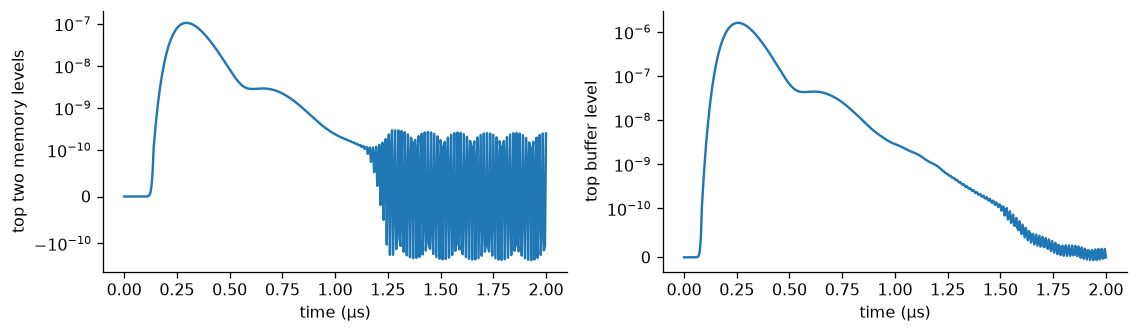

all small-cat bit rates change by <1% at larger cutoffs: True
constant larger-cutoff changes: information 5.845e-06, wrong-codeword 3.179e-02
resonant larger-cutoff changes: information 6.611e-05, wrong-codeword 3.322e-02
even charging all residual leakage as a wrong bit, resonant error bound = 0.000260678
constant-drive wrong-codeword population for comparison = 0.000317278


In [24]:
tight_t = np.linspace(0, 2, 401)  # identical output times to the inflation reference
tight_inflation = full_run(40, 16, tight_t, rtol=2e-11, atol=2e-13)
tight_checks = checks(tight_inflation)
old_cutoffs = pd.read_csv(artifacts / "cutoff_convergence.csv")  # generated earlier in this notebook
old_reference = old_cutoffs.query("na == 40 and nb == 16").iloc[0]
peak_change = abs(tight_inflation["e"][0].real.max() - old_reference["peak n"])
end_change = abs(tight_inflation["e"][0, -1].real - old_reference["final n"])
print("tighter reference density checks:", tight_checks)
print(f"absolute changes in peak/end photons: {peak_change:.3e}, {end_change:.3e}")
assert peak_change < 1e-4 and end_change < 1e-4  # far tighter than the declared 0.2% cutoff tolerance
assert tight_checks["min eigenvalue"] > -1e-7  # now explicitly check the density positivity floor
late = tight_t >= 0.8  # after the main inflation transient
parity_envelope = tight_inflation["e"][4].real - np.exp(-2*alpha**2)
coherence_slope, _ = np.polyfit(tight_t[late], np.log(parity_envelope[late]), 1)
print(f"inflated-cat late parity e-fold time: {-1/coherence_slope:.4f} μs")
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for axis, index, label in zip(axes, [5, 6], ["top two memory levels", "top buffer level"]):
    axis.plot(tight_t, tight_inflation["e"][index].real)
    axis.set_yscale("symlog", linthresh=1e-10)  # preserve the sign of precision-scale residuals
    axis.set(xlabel="time (μs)", ylabel=label)
finish_figure(fig, "15_tight_reference_tails")
bit_validation = pd.read_csv(artifacts / "bit_flip_rates.csv")  # the already-computed results, not a new fit
robust_validation = pd.read_csv(artifacts / "readout_robustness.csv")
matched_validation = pd.read_csv(artifacts / "equal_information_comparison.csv").set_index("pulse")
bit_checks_pass = bool((bit_validation["cutoff relative change"] < 0.01).all())
print(f"all small-cat bit rates change by <1% at larger cutoffs: {bit_checks_pass}")
assert bit_checks_pass
large_readout = robust_validation[robust_validation["check"] == "larger cutoffs + tighter solver"]
for _, row in large_readout.iterrows():
    nominal = matched_validation.loc[row["pulse"]]
    print(f"{row['pulse']} larger-cutoff changes: information {abs(row['information']/nominal['information']-1):.3e}, "
          f"wrong-codeword {abs(row['wrong codeword']/nominal['wrong codeword']-1):.3e}")
    assert abs(row["wrong codeword"]/nominal["wrong codeword"]-1) < 0.04  # this small protocol diagnostic is stable to 4%
worst_resonant = matched_validation.loc["resonant", "wrong codeword"] + matched_validation.loc["resonant", "leakage"]
print(f"even charging all residual leakage as a wrong bit, resonant error bound = {worst_resonant:.6g}")
print(f"constant-drive wrong-codeword population for comparison = {matched_validation.loc['constant', 'wrong codeword']:.6g}")

2.4 extension — choose the ending, then calculate the pulse

the question here is narrower than 'undo a measurement': can a drive leave a
useful emitted signal while bringing the *motion* back near its starting point?
this cannot recover coherence that the measured bit information has destroyed.
reset-shaped measurement pulses already exist in other architectures, e.g.
[jerger et al.](https://arxiv.org/abs/2406.04891). the test here is their usefulness
for this nonlinear dissipative cat, not a claim that pulse cleanup is new.

put y = im(a - alpha), x = re(b), and omega = 2 g2 alpha near the positive well.
to first order, y' = -ka y/2 - omega x - u and x' = omega y - kb x/2.
near the other well the same drive gives the same y and opposite x. therefore
one open-loop pulse can satisfy the endpoint conditions for either stored bit.
the tiny loss-induced shift of the real well is omitted in this design model;
it is present in the full quantum simulation used to judge the result.

expand u in smooth functions sin²(pi t/d) cos(m pi t/d). integrate each one's
response, then find combinations with x(d)=y(d)=0 using a matrix nullspace.
within that space maximize emitted signal energy per drive energy using a
generalized eigenvalue problem. the robust version also cancels the first
derivative of the endpoint with respect to the exchange frequency.
this is a linear design hypothesis, not a proof of quantum recovery.

In [25]:
from scipy.integrate import solve_ivp  # only the inexpensive two-variable design model

design_duration = 1.5  # all candidates still get the same 3 microseconds total
design_modes = 15  # a fixed smooth basis, not hundreds of freely fitted samples
design_peak_limit = 0.5 * g2  # same amplitude limit as the earlier experiment
extension_target = 0.79  # chosen before testing new pulses; not high-fidelity readout
extension_criteria = {"information relative": 0.01, "wrong relative": 0.01,
                      "wrong absolute": 2e-6, "negative eigenvalue": 1e-7,
                      "assignment absolute": 0.03}  # keep these unchanged if a test fails


def linear_pulse_response(duration, frequency_factor=1.0):
    grid = np.linspace(0, duration, 1501)  # resolves the fastest basis function
    harmonics = np.arange(design_modes)  # the zero-frequency member is included
    def basis(t):
        return np.sin(np.pi*t/duration)**2 * np.cos(harmonics*np.pi*t/duration)
    frequency = 2*g2*alpha*frequency_factor
    matrix = np.array([[-ka/2, -frequency], [frequency, -kb/2]])
    def rhs(t, state):
        motion = state.reshape(2, design_modes)
        forcing = np.stack([-basis(t), np.zeros(design_modes)])
        return (matrix @ motion + forcing).ravel()
    solution = solve_ivp(rhs, (0, duration), np.zeros(2*design_modes), t_eval=grid,
                         rtol=2e-10, atol=2e-12)  # design accuracy, separate from the quantum solver
    assert solution.success
    response = solution.y.reshape(2, design_modes, -1).transpose(2, 0, 1)
    basis_values = np.array([basis(t) for t in grid])
    return grid, basis_values, response


def calculate_closed_pulse(robust=False):
    grid, basis_values, response = linear_pulse_response(design_duration)
    endpoint = response[-1]  # maps coefficients to the two residual quadratures
    constraints = endpoint
    if robust:
        _, _, lower = linear_pulse_response(design_duration, 0.99)
        _, _, upper = linear_pulse_response(design_duration, 1.01)
        derivative = (upper[-1] - lower[-1]) / 0.02
        constraints = np.vstack([endpoint, derivative])  # first-order robustness, not a guarantee over a large interval
    null = la.null_space(constraints)  # every vector in this subspace closes the linear trajectory
    signal_gram = 4*kb*np.trapezoid(response[:, 1, :, None]*response[:, 1, None, :], grid, axis=0)
    energy_gram = np.trapezoid(basis_values[:, :, None]*basis_values[:, None, :], grid, axis=0)
    values, vectors = la.eigh(null.T @ signal_gram @ null, null.T @ energy_gram @ null)
    coefficients = null @ vectors[:, -1]  # greatest information proxy per integrated drive energy
    fine_grid = np.linspace(0, design_duration, 30001)
    fine_basis = np.sin(np.pi*fine_grid[:, None]/design_duration)**2 * np.cos(np.arange(design_modes)*np.pi*fine_grid[:, None]/design_duration)
    coefficients /= 1.0001*np.max(abs(fine_basis @ coefficients))  # a small safety margin below the amplitude cap
    return {"kind": "closed robust" if robust else "closed nominal", "duration": design_duration,
            "coefficients": coefficients.tolist(), "peak": float(design_peak_limit)}


def extension_waveform(spec):
    duration, peak = spec["duration"], spec["peak"]
    kind = spec["kind"]
    coefficients = jnp.asarray(spec.get("coefficients", [0.0]))
    def envelope(t):
        if kind.startswith("closed"):
            value = jnp.sin(jnp.pi*t/duration)**2 * jnp.sum(coefficients*jnp.cos(jnp.arange(len(coefficients))*jnp.pi*t/duration))
        elif kind == "resonant":
            value = jnp.sin(jnp.pi*t/duration)**2 * jnp.cos(2*g2*alpha*t)
        elif kind == "flat":
            edge = 0.02  # finite 20 ns ramps; an ideal step would have infinite bandwidth
            value = jnp.sin(jnp.pi/2*jnp.minimum(jnp.minimum(t, duration-t)/edge, 1.0))**2
        else:
            value = 0.0*t  # idle reference
        return jnp.where((t >= 0) & (t < duration), peak*value, 0.0)
    return envelope


closed_specs = [calculate_closed_pulse(False), calculate_closed_pulse(True)]
linear_rows = []
for spec in closed_specs:
    for factor in [0.95, 1.0, 1.05]:
        grid, basis_values, response = linear_pulse_response(spec["duration"], factor)
        coefficients = spec["peak"]*np.asarray(spec["coefficients"])
        endpoint = response[-1] @ coefficients
        linear_rows.append({"pulse": spec["kind"], "exchange factor": factor,
                            "residual motion squared": float(endpoint @ endpoint)})
table(pd.DataFrame(linear_rows), "closed_linear_endpoints")
assert max(row["residual motion squared"] for row in linear_rows if row["exchange factor"] == 1.0) < 1e-16
print("fixed acceptance criteria:", extension_criteria)

,pulse,exchange factor,residual motion squared
0,closed nominal,0.95,5.313003e-04
1,closed nominal,1.00,4.853624e-32
2,closed nominal,1.05,5.533904e-04
3,closed robust,0.95,9.809672e-06
4,closed robust,1.00,9.641391e-33
5,closed robust,1.05,6.082798e-06


fixed acceptance criteria: {'information relative': 0.01, 'wrong relative': 0.01, 'wrong absolute': 2e-06, 'negative eigenvalue': 1e-07, 'assignment absolute': 0.03}


now let the full quantum model disagree with the design, if it needs to.
the training cutoff is (24,6); the larger cutoffs below are held-out tests.
a fixed target information of 0.79 corresponds to roughly 19% assignment error
in the earlier ideal gaussian estimate. this is a modest-information benchmark,
not a demonstrated high-fidelity measurement. a candidate unable to reach the
target under the amplitude cap is marked infeasible, not quietly given more power.
the flat-drive baseline is tuned over three durations, with finite edge ramps.

In [26]:
def extension_run(spec, na=24, nb=6, tolerance=2e-12, coupling_factor=1.0, corrected=False, sign=1):
    h, jumps, ops, a, b = two_mode(na, nb, coupling=g2*coupling_factor)
    if corrected:
        exchange, _ = sine_exchange(na, nb, calibrate=True)
        h = exchange - g2*alpha**2*(b+b.dag())  # same calibrated circuit correction as above
    times = np.linspace(0, 3, 601)  # saved grid; adaptive integration uses much smaller internal steps
    initial = dq.tensor(dq.coherent(na, sign*alpha), dq.fock(nb, 0))
    base_path = run_key(h, jumps, initial, times, ops, 100*tolerance, tolerance)
    digest = hashlib.sha256((base_path.stem + json.dumps(spec, sort_keys=True) + "closed-pulse-v1").encode()).hexdigest()
    path = base_path.with_name(digest + ".npz")  # include the entire pulse and the actual model in the cache key
    if path.exists():
        with np.load(path, allow_pickle=False) as saved:
            run = {name: saved[name] for name in ["t", "e", "rho"]}
            run["final"] = dq.asqarray(saved["final"], dims=(na, nb))
    else:
        edges = sorted(set([0.02, spec["duration"]-0.02, spec["duration"]]))
        driven = h + dq.modulated(extension_waveform(spec), a+a.dag(), discontinuity_ts=edges)
        run = evolve(driven, jumps, initial, times, ops, (na, nb), rtol=100*tolerance, atol=tolerance)
        save_run(path, run)
    even = np.asarray(dq.to_numpy(cat_ket(na, alpha, 1))).ravel()
    odd = np.asarray(dq.to_numpy(cat_ket(na, alpha, -1))).ravel()
    wrong = (even-sign*odd)/np.sqrt(2)
    wrong_t = np.einsum("i,tij,j->t", wrong.conj(), run["rho"], wrong).real
    in_code = sum(np.einsum("i,tij,j->t", cat.conj(), run["rho"], cat).real for cat in [even, odd])
    run.update({"wrong": float(wrong_t[-1]), "leakage": float(1-in_code[-1]),
                "wrong trace": wrong_t, "leakage trace": 1-in_code,
                "information": float(4*kb*np.trapezoid(run["e"][3].real**2, times)),
                "spec": dict(spec), "checks": checks(run)})
    return run


def match_extension(spec, target=extension_target, na=24, nb=6):
    trial = dict(spec, peak=float(design_peak_limit))
    run = extension_run(trial, na, nb)
    if run["information"] < target*(1-extension_criteria["information relative"]):
        return run, False  # do not violate the hardware limit to force a favorable comparison
    for _ in range(4):
        trial["peak"] *= float(np.sqrt(target/run["information"]))
        if trial["peak"] > design_peak_limit:
            return run, False
        run = extension_run(trial, na, nb)
        if abs(run["information"]/target-1) < 0.002:
            return run, True
    return run, abs(run["information"]/target-1) < extension_criteria["information relative"]


training_specs = [{"kind": "flat", "duration": duration, "peak": float(design_peak_limit)} for duration in [0.75, 1.5, 2.25]]
training_specs += [{"kind": "resonant", "duration": 1.5, "peak": float(design_peak_limit)}, *closed_specs]
training_runs, training_rows = {}, []
for spec in training_specs:
    label = f"{spec['kind']} {spec['duration']:g} us"
    run, feasible = match_extension(spec)
    training_runs[label] = run
    training_rows.append({"pulse": label, "feasible": feasible, "information": run["information"],
                          "peak/g2": run["spec"]["peak"]/g2, "wrong": run["wrong"], "leakage": run["leakage"],
                          "wrong + leakage": run["wrong"]+run["leakage"]})
    print(label, training_rows[-1], flush=True)
training_table = pd.DataFrame(training_rows)
table(training_table, "closed_training")

flat 0.75 us {'pulse': 'flat 0.75 us', 'feasible': False, 'information': 0.7349800632849218, 'peak/g2': 0.5, 'wrong': 0.00033143928121266795, 'leakage': 8.135697259659125e-06, 'wrong + leakage': 0.00033957497847232707}


flat 1.5 us {'pulse': 'flat 1.5 us', 'feasible': True, 'information': 0.7913748762593801, 'peak/g2': 0.3721264875133902, 'wrong': 0.0003187819935063403, 'leakage': 8.483078140941736e-06, 'wrong + leakage': 0.00032726507164728205}


flat 2.25 us {'pulse': 'flat 2.25 us', 'feasible': True, 'information': 0.7900035134261353, 'peak/g2': 0.3050993608034043, 'wrong': 0.00029399819029551265, 'leakage': 4.102593453381154e-05, 'wrong + leakage': 0.0003350241248293242}


resonant 1.5 us {'pulse': 'resonant 1.5 us', 'feasible': True, 'information': 0.7900150214761652, 'peak/g2': 0.44620055184039215, 'wrong': 0.0002521830654185105, 'leakage': 8.242227049537476e-06, 'wrong + leakage': 0.000260425292468048}


closed nominal 1.5 us {'pulse': 'closed nominal 1.5 us', 'feasible': True, 'information': 0.7900332800498943, 'peak/g2': 0.39205393308968833, 'wrong': 0.0002508453320373279, 'leakage': 8.160440156057547e-06, 'wrong + leakage': 0.00025900577219338544}


closed robust 1.5 us {'pulse': 'closed robust 1.5 us', 'feasible': True, 'information': 0.7908730537764986, 'peak/g2': 0.47308427338697717, 'wrong': 0.0002630042317379188, 'leakage': 8.146679085552222e-06, 'wrong + leakage': 0.000271150910823471}


,pulse,feasible,information,peak/g2,wrong,leakage,wrong + leakage
0,flat 0.75 us,False,0.734980,0.500000,0.000331,0.000008,0.000340
1,flat 1.5 us,True,0.791375,0.372126,0.000319,0.000008,0.000327
2,flat 2.25 us,True,0.790004,0.305099,0.000294,0.000041,0.000335
3,resonant 1.5 us,True,0.790015,0.446201,0.000252,0.000008,0.000260
4,closed nominal 1.5 us,True,0.790033,0.392054,0.000251,0.000008,0.000259
5,closed robust 1.5 us,True,0.790873,0.473084,0.000263,0.000008,0.000271


the selection rule counts leakage as failure, rather than hiding it behind a
small wrong-codeword population. the new pulse must beat the existing resonant
waveform too, not just the flat drive. a small difference may be unresolved.
readiness is a separate metric: after the drive ends, has the information
reached 99% of the target and does leakage stay below a declared threshold?
i show three thresholds (1e-3, 1e-4, 1e-5), because there is no universal hardware
definition of 'ready'. this is an unconditional-state diagnostic, not a bound
on every individual measurement trajectory.

selected on the training cutoff: flat 1.5 us and closed nominal 1.5 us


held-out check flat 24 6 {'pulse': 'flat', 'na': 24, 'nb': 6, 'information': 0.7913748762593801, 'wrong': 0.0003187819935063403, 'leakage': 8.483078140941736e-06, 'wrong + leakage': 0.00032726507164728205, 'max memory tail': 1.0946948274580002e-07, 'max buffer tail': 1.2931411807315597e-05, 'trace error': np.float64(2.6645352591003757e-15), 'hermiticity error': np.float64(0.0), 'min eigenvalue': np.float64(-4.9569138083073804e-11)}


held-out check flat 32 8 {'pulse': 'flat', 'na': 32, 'nb': 8, 'information': 0.7913800643716583, 'wrong': 0.0003076451666808725, 'leakage': 8.433768855731216e-06, 'wrong + leakage': 0.0003160789355366037, 'max memory tail': 7.91385867714744e-11, 'max buffer tail': 1.8381599998752183e-06, 'trace error': np.float64(2.886579864025407e-15), 'hermiticity error': np.float64(0.0), 'min eigenvalue': np.float64(-2.0602861932182917e-10)}


held-out check flat 36 10 {'pulse': 'flat', 'na': 36, 'nb': 10, 'information': 0.7913817235129564, 'wrong': 0.00030670912359839937, 'leakage': 8.42938910161628e-06, 'wrong + leakage': 0.00031513851270001565, 'max memory tail': 2.8787009847406914e-09, 'max buffer tail': 2.727076518469675e-07, 'trace error': np.float64(1.7763568394002505e-15), 'hermiticity error': np.float64(0.0), 'min eigenvalue': np.float64(-1.1213193625776666e-08)}


flat: held-out numerical criterion passed = True; wrong absolute change = 9.360e-07


...

held-out check closed 32 8 {'pulse': 'closed', 'na': 32, 'nb': 8, 'information': 0.790006919775507, 'wrong': 0.00024156415853987903, 'leakage': 8.137717118827936e-06, 'wrong + leakage': 0.00024970187565870696, 'max memory tail': 1.0565964127632264e-10, 'max buffer tail': 2.7514916027868102e-06, 'trace error': np.float64(5.329070518200751e-15), 'hermiticity error': np.float64(0.0), 'min eigenvalue': np.float64(-1.92680075964425e-10)}


held-out check closed 36 10 {'pulse': 'closed', 'na': 36, 'nb': 10, 'information': 0.790003566931188, 'wrong': 0.00024006366655696638, 'leakage': 8.135387310592712e-06, 'wrong + leakage': 0.0002481990538675591, 'max memory tail': 3.2088763529400624e-09, 'max buffer tail': 4.0704946310274747e-07, 'trace error': np.float64(2.220446049250313e-15), 'hermiticity error': np.float64(0.0), 'min eigenvalue': np.float64(-1.1855767326547932e-08)}


closed: held-out numerical criterion passed = True; wrong absolute change = 1.500e-06


,pulse,na,nb,information,wrong,leakage,wrong + leakage,max memory tail,max buffer tail,trace error,hermiticity error,min eigenvalue
0,flat,24,6,0.791375,0.000319,0.000008,0.000327,1.094695e-07,1.293141e-05,2.664535e-15,0.0,-4.956914e-11
1,flat,32,8,0.791380,0.000308,0.000008,0.000316,7.913859e-11,1.838160e-06,2.886580e-15,0.0,-2.060286e-10
2,flat,36,10,0.791382,0.000307,0.000008,0.000315,2.878701e-09,2.727077e-07,1.776357e-15,0.0,-1.121319e-08
3,resonant,24,6,0.790015,0.000252,0.000008,0.000260,1.237750e-07,2.297775e-05,1.332268e-15,0.0,-6.972714e-11
4,resonant,32,8,0.789961,0.000243,0.000008,0.000252,1.162153e-10,3.156371e-06,8.881784e-16,0.0,-2.103915e-10
5,resonant,36,10,0.789957,0.000242,0.000008,0.000250,3.295733e-09,4.674303e-07,2.664535e-15,0.0,-1.197651e-08
6,closed,24,6,0.790033,0.000251,0.000008,0.000259,1.140290e-07,2.018114e-05,1.443290e-15,0.0,-4.171365e-11
7,closed,32,8,0.790007,0.000242,0.000008,0.000250,1.056596e-10,2.751492e-06,5.329071e-15,0.0,-1.926801e-10
8,closed,36,10,0.790004,0.000240,0.000008,0.000248,3.208876e-09,4.070495e-07,2.220446e-15,0.0,-1.185577e-08


,pulse,leakage threshold,ready time us
0,flat,0.00100,1.800
1,flat,0.00010,2.155
2,flat,0.00001,2.735
3,resonant,0.00100,1.620
4,resonant,0.00010,1.975
5,resonant,0.00001,2.560
6,closed,0.00100,1.500
7,closed,0.00010,1.775
8,closed,0.00001,2.350


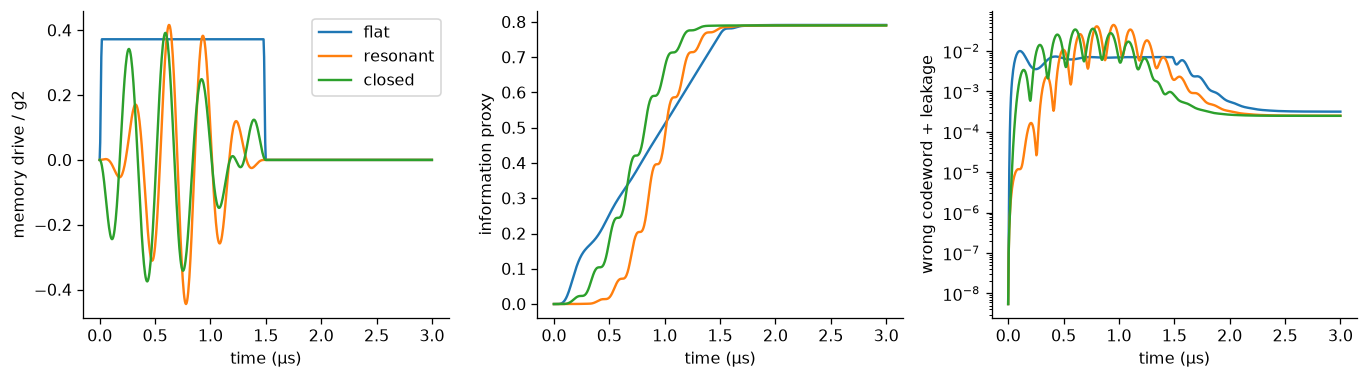

In [27]:
feasible_training = training_table[training_table["feasible"]].copy()
flat_label = feasible_training[feasible_training["pulse"].str.startswith("flat")].sort_values("wrong + leakage").iloc[0]["pulse"]
closed_label = feasible_training[feasible_training["pulse"].str.startswith("closed")].sort_values("wrong + leakage").iloc[0]["pulse"]
selected_specs = {"flat": training_runs[flat_label]["spec"],
                  "resonant": training_runs["resonant 1.5 us"]["spec"],
                  "closed": training_runs[closed_label]["spec"]}  # freeze before looking at larger cutoffs
print("selected on the training cutoff:", flat_label, "and", closed_label)


def ready_time(run, leakage_limit):
    information_t = 4*kb*cumulative_trapezoid(run["e"][3].real**2, run["t"], initial=0)
    good = (run["leakage trace"] <= leakage_limit) & (information_t >= 0.99*extension_target)
    stays_good = np.logical_and.accumulate(good[::-1])[::-1]  # do not count a brief crossing during ringing
    indices = np.flatnonzero(stays_good & (run["t"] >= run["spec"]["duration"]))
    return float(run["t"][indices[0]]) if len(indices) else np.nan


validation_runs, validation_rows, readiness_rows = {}, [], []
for label, spec in selected_specs.items():
    for na, nb in [(24, 6), (32, 8), (36, 10)]:
        run = extension_run(spec, na, nb)
        validation_runs[(label, na, nb)] = run
        validation_rows.append({"pulse": label, "na": na, "nb": nb, "information": run["information"],
                                "wrong": run["wrong"], "leakage": run["leakage"],
                                "wrong + leakage": run["wrong"]+run["leakage"],
                                "max memory tail": float(run["e"][5].real.max()),
                                "max buffer tail": float(run["e"][6].real.max()), **run["checks"]})
        print("held-out check", label, na, nb, validation_rows[-1], flush=True)
    reference, previous = validation_runs[(label, 36, 10)], validation_runs[(label, 32, 8)]
    wrong_change = abs(reference["wrong"]-previous["wrong"])
    passed = (wrong_change < max(extension_criteria["wrong absolute"], extension_criteria["wrong relative"]*abs(reference["wrong"]))
              and abs(reference["information"]/previous["information"]-1) < extension_criteria["information relative"]
              and reference["checks"]["min eigenvalue"] > -extension_criteria["negative eigenvalue"])
    print(f"{label}: held-out numerical criterion passed = {passed}; wrong absolute change = {wrong_change:.3e}", flush=True)
    for threshold in [1e-3, 1e-4, 1e-5]:
        readiness_rows.append({"pulse": label, "leakage threshold": threshold,
                               "ready time us": ready_time(reference, threshold)})
table(pd.DataFrame(validation_rows), "closed_validation")
table(pd.DataFrame(readiness_rows), "closed_readiness")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for label, spec in selected_specs.items():
    run = validation_runs[(label, 36, 10)]
    axes[0].plot(run["t"], jax.vmap(extension_waveform(spec))(jnp.asarray(run["t"]))/g2, label=label)
    axes[1].plot(run["t"], 4*kb*cumulative_trapezoid(run["e"][3].real**2, run["t"], initial=0), label=label)
    axes[2].plot(run["t"], run["wrong trace"]+run["leakage trace"], label=label)
axes[0].set(ylabel="memory drive / g2", xlabel="time (μs)")
axes[1].set(ylabel="information proxy", xlabel="time (μs)")
axes[2].set(ylabel="wrong codeword + leakage", xlabel="time (μs)", yscale="log")
axes[0].legend()
finish_figure(fig, "16_closed_pulse_recovery")

these are stress tests of the frozen pulse, without reoptimizing its shape.
a coupling change also changes the stabilizing pump consistently to keep alpha
fixed. this is a calibrated-g uncertainty test, not a claim to cover every
possible independent pump error. the circuit test retains the resonant sine
corrections derived above; it still omits counter-rotating and transformed-bath
effects. information can change in a stress test, so it is printed alongside
damage rather than silently calling the comparison equal-information.

In [28]:
stress_rows = []
for label in ["flat", "closed"]:
    for factor, corrected, condition in [(0.95, False, "coupling -5%"), (1.05, False, "coupling +5%"),
                                          (1.0, True, "calibrated resonant sine")]:
        run = extension_run(selected_specs[label], 32, 8, coupling_factor=factor, corrected=corrected)
        stress_rows.append({"pulse": label, "condition": condition, "information": run["information"],
                            "wrong": run["wrong"], "leakage": run["leakage"],
                            "ready time at 1e-4 us": ready_time(run, 1e-4)})
        print("stress test", stress_rows[-1], flush=True)
table(pd.DataFrame(stress_rows), "closed_stress_tests")

stress test {'pulse': 'flat', 'condition': 'coupling -5%', 'information': 0.8755579590200149, 'wrong': 0.0003233176305493528, 'leakage': 9.084373544077096e-06, 'ready time at 1e-4 us': 2.16}


stress test {'pulse': 'flat', 'condition': 'coupling +5%', 'information': 0.7186259251870115, 'wrong': 0.0002954573979212093, 'leakage': 7.906943346180917e-06, 'ready time at 1e-4 us': nan}


stress test {'pulse': 'flat', 'condition': 'calibrated resonant sine', 'information': 0.7994346314173746, 'wrong': 0.0003393442531631564, 'leakage': 2.5461572298990376e-05, 'ready time at 1e-4 us': 2.22}


stress test {'pulse': 'closed', 'condition': 'coupling -5%', 'information': 0.7935137502868242, 'wrong': 0.00022418848224017369, 'leakage': 8.796948324008014e-06, 'ready time at 1e-4 us': 1.78}


stress test {'pulse': 'closed', 'condition': 'coupling +5%', 'information': 0.7527868649761388, 'wrong': 0.00024728293842470083, 'leakage': 7.61279406069626e-06, 'ready time at 1e-4 us': nan}


stress test {'pulse': 'closed', 'condition': 'calibrated resonant sine', 'information': 0.7615026915553946, 'wrong': 0.00022006561381184348, 'leakage': 2.503857752622629e-05, 'ready time at 1e-4 us': nan}


,pulse,condition,information,wrong,leakage,ready time at 1e-4 us
0,flat,coupling -5%,0.875558,0.000323,0.000009,2.16
1,flat,coupling +5%,0.718626,0.000295,0.000008,NaN
2,flat,calibrated resonant sine,0.799435,0.000339,0.000025,2.22
3,closed,coupling -5%,0.793514,0.000224,0.000009,1.78
4,closed,coupling +5%,0.752787,0.000247,0.000008,NaN
5,closed,calibrated resonant sine,0.761503,0.000220,0.000025,NaN


noisy readout, including quantum backaction

rather than adding noise to the mean curve, simulate homodyne quantum
trajectories with [dynamiqs' diffusive solver](https://www.dynamiqs.org/stable/python_api/integrators/dssesolve.html).
both loss channels are unraveled to keep the state a small vector. only the
buffer record is given to the classifier; discarding the memory-channel record
gives the correct buffer-record marginal for an unobserved memory bath.
[the solver documentation](https://www.dynamiqs.org/stable/python_api/integrators/dsmesolve.html)
explicitly supports this record-only construction. no feedback uses the hidden
channel. the trajectories are not conditional memory states for a buffer-only
observer; interpreting them that way would be incorrect.

the receiver uses a fixed matched filter from the deterministic simulation,
with a zero threshold fixed by branch symmetry, not fitted to the test records.
this is a specified practical classifier, not necessarily the optimal receiver.
time-averaged currents must be multiplied by their bin widths when integrating.
efficiency is one here; detector loss, bandwidth and amplifier noise are not
magically included. the ideal-output gaussian prediction is only a comparison.

In [29]:
def trajectory_batch(spec, sign, seed, count=128, dt=0.0001, na=24, nb=6, map_normalization=False):
    h, jumps, ops, a, b = two_mode(na, nb)
    initial = dq.tensor(dq.coherent(na, sign*alpha), dq.fock(nb, 0))
    times = np.linspace(0, 3, 601)  # 5 ns record bins; dt is the finer stochastic integration step
    base_path = run_key(h, jumps, initial, times, [ops[0]], dt, dt)
    settings = {"pulse": spec, "seed": seed, "count": count, "dt": dt,
                "method": "Rouchon1-normalized-v1" if map_normalization else "Rouchon1-ket-normalized-v1"}
    digest = hashlib.sha256((base_path.stem+json.dumps(settings, sort_keys=True)).encode()).hexdigest()
    path = base_path.with_name("records-"+digest+".npz")
    if path.exists():
        with np.load(path, allow_pickle=False) as saved:
            return {key: saved[key] for key in saved.files}
    driven = h+dq.modulated(extension_waveform(spec), a+a.dag())  # smooth edges are resolved by the fixed step
    keys = jax.random.split(jax.random.key(seed), count)  # independent seeds are recorded for reproducibility
    started = time.monotonic()
    result = dq.dssesolve(driven, jumps, initial, times, keys, exp_ops=[ops[0]],
                         method=dq.method.Rouchon1(dt=dt, normalize=map_normalization), save_states=False)
    # both variants normalize each ket; the expensive option also corrects the discrete Kraus map
    records = np.asarray(result.measurements)[:, 0, :]  # buffer channel only; do not leak the memory record
    final_n = np.asarray(result.expects)[:, 0, -1].real
    assert np.isfinite(records).all() and np.isfinite(final_n).all()
    output = {"t": times, "records": records, "final_n": final_n}
    np.savez_compressed(path, **output)
    print(f"{spec['kind']} sign {sign:+d}: {count} trajectories, dt={dt:g}, ({na},{nb}), {time.monotonic()-started:.1f}s", flush=True)
    return output


def wilson_interval(errors, count):
    z = 1.959963984540054  # two-sided 95% binomial score interval, not sqrt(p) error bars
    p = errors/count
    center = (p+z*z/(2*count))/(1+z*z/count)
    half = z*np.sqrt(p*(1-p)/count+z*z/(4*count*count))/(1+z*z/count)
    return float(center-half), float(center+half)


def score_records(batch, template):
    times = batch["t"]
    weight = 2*np.sqrt(kb)*np.interp(times, template["t"], template["e"][3].real)
    weight = (weight[:-1]+weight[1:])/2  # bin-average approximation; bins are short compared with ringing
    widths = np.diff(times)
    normalization = np.sqrt(np.sum(weight*weight*widths))
    return batch["records"] @ (weight*widths) / normalization

noisy readout {'pulse': 'flat', 'initial bit sign': 1, 'shots': 1024, 'errors': 198, 'assignment error': 0.193359375, '95% low': 0.17033431599099158, '95% high': 0.21867651383042558, 'score mean': 0.8685662456347591, 'score standard deviation': 0.9623659216634051, 'final n mean': 4.402998820828273, 'final n standard error': 8.716768282201296e-05}


noisy readout {'pulse': 'flat', 'initial bit sign': -1, 'shots': 1024, 'errors': 183, 'assignment error': 0.1787109375, '95% low': 0.15645979163239984, '95% high': 0.2033636574480022, 'score mean': -0.8991653687652397, 'score standard deviation': 0.9796295075635887, 'final n mean': 4.402956523726444, 'final n standard error': 8.623007472342498e-05}


noisy readout {'pulse': 'resonant', 'initial bit sign': 1, 'shots': 1024, 'errors': 183, 'assignment error': 0.1787109375, '95% low': 0.15645979163239984, '95% high': 0.2033636574480022, 'score mean': 0.9364175194372366, 'score standard deviation': 1.0194352764029635, 'final n mean': 4.4030152752729546, 'final n standard error': 8.184832469872496e-05}


noisy readout {'pulse': 'resonant', 'initial bit sign': -1, 'shots': 1024, 'errors': 191, 'assignment error': 0.1865234375, '95% low': 0.16385266729857345, '95% high': 0.21153738484370332, 'score mean': -0.8796440582932439, 'score standard deviation': 0.9777664791633994, 'final n mean': 4.402931771671997, 'final n standard error': 8.17700411755631e-05}


noisy readout {'pulse': 'closed', 'initial bit sign': 1, 'shots': 1024, 'errors': 180, 'assignment error': 0.17578125, '95% low': 0.15369166390922512, '95% high': 0.2002943090229739, 'score mean': 0.9537432221465181, 'score standard deviation': 1.0198941253552598, 'final n mean': 4.403003542246868, 'final n standard error': 7.962124451128131e-05}


noisy readout {'pulse': 'closed', 'initial bit sign': -1, 'shots': 1024, 'errors': 181, 'assignment error': 0.1767578125, '95% low': 0.1546141131545228, '95% high': 0.20131768516041051, 'score mean': -0.9157215377807602, 'score standard deviation': 0.961302959397078, 'final n mean': 4.402964724091771, 'final n standard error': 8.019563759634478e-05}


,pulse,initial bit sign,shots,errors,assignment error,95% low,95% high,score mean,score standard deviation,final n mean,final n standard error
0,flat,1,1024,198,0.193359,0.170334,0.218677,0.868566,0.962366,4.402999,0.000087
1,flat,-1,1024,183,0.178711,0.156460,0.203364,-0.899165,0.979630,4.402957,0.000086
2,resonant,1,1024,183,0.178711,0.156460,0.203364,0.936418,1.019435,4.403015,0.000082
3,resonant,-1,1024,191,0.186523,0.163853,0.211537,-0.879644,0.977766,4.402932,0.000082
4,closed,1,1024,180,0.175781,0.153692,0.200294,0.953743,1.019894,4.403004,0.000080
5,closed,-1,1024,181,0.176758,0.154614,0.201318,-0.915722,0.961303,4.402965,0.000080


,pulse,shots,assignment error,95% low,95% high,gaussian mean-signal prediction,wrong,leakage,wrong + leakage
0,flat,2048,0.186035,0.169775,0.203471,0.186841,0.000307,0.000008,0.000315
1,resonant,2048,0.182617,0.166484,0.199939,0.187057,0.000242,0.000008,0.000250
2,closed,2048,0.176270,0.160377,0.193374,0.187050,0.000240,0.000008,0.000248


,comparison,assignment difference,95% low,95% high,within +/-3 percentage points
0,closed minus flat,-0.009766,-0.033751,0.014220,False
1,closed minus resonant,-0.006348,-0.023443,0.010747,True


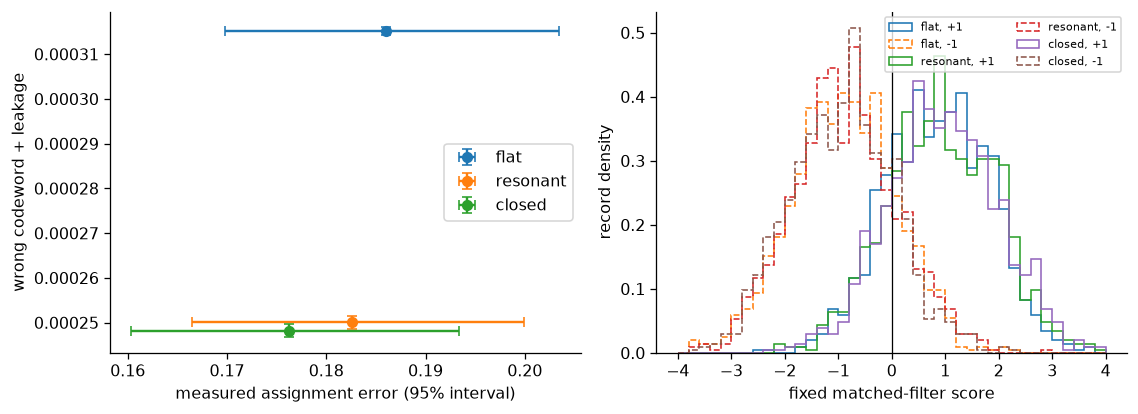

In [30]:
record_rows, record_samples = [], {}
for label, spec in selected_specs.items():
    template = validation_runs[(label, 24, 6)]  # deterministic filter; none of the test records trains it
    for sign in [1, -1]:
        scores, final_numbers = [], []
        for repeat in range(2):
            seed = 20261024 + 1000*(sign < 0) + repeat  # common random numbers across pulses, independent between bits/batches
            batch = trajectory_batch(spec, sign, seed, count=512)
            scores.extend(score_records(batch, template))
            final_numbers.extend(batch["final_n"])
        scores, final_numbers = np.asarray(scores), np.asarray(final_numbers)
        errors = sign*scores <= 0
        low, high = wilson_interval(int(errors.sum()), len(errors))
        record_samples[(label, sign)] = {"scores": scores, "errors": errors, "final n": final_numbers}
        record_rows.append({"pulse": label, "initial bit sign": sign, "shots": len(errors),
                            "errors": int(errors.sum()), "assignment error": float(errors.mean()),
                            "95% low": low, "95% high": high, "score mean": float(scores.mean()),
                            "score standard deviation": float(scores.std(ddof=1)),
                            "final n mean": float(final_numbers.mean()),
                            "final n standard error": float(final_numbers.std(ddof=1)/np.sqrt(len(final_numbers)))})
        print("noisy readout", record_rows[-1], flush=True)
record_table = pd.DataFrame(record_rows)
table(record_table, "closed_noisy_readout")

assignment_rows = []
for label in selected_specs:
    errors = np.concatenate([record_samples[(label, sign)]["errors"] for sign in [1, -1]])
    low, high = wilson_interval(int(errors.sum()), len(errors))
    run = validation_runs[(label, 36, 10)]
    assignment_rows.append({"pulse": label, "shots": len(errors), "assignment error": float(errors.mean()),
                            "95% low": low, "95% high": high,
                            "gaussian mean-signal prediction": float(0.5*erfc(np.sqrt(run["information"]/2))),
                            "wrong": run["wrong"], "leakage": run["leakage"],
                            "wrong + leakage": run["wrong"]+run["leakage"]})
assignment_table = pd.DataFrame(assignment_rows)
table(assignment_table, "closed_assignment_summary")

comparison_rows = []
for baseline in ["flat", "resonant"]:
    differences = np.concatenate([record_samples[("closed", sign)]["errors"].astype(float)
                                  - record_samples[(baseline, sign)]["errors"].astype(float) for sign in [1, -1]])
    half = 1.96*differences.std(ddof=1)/np.sqrt(len(differences))  # paired interval, since the pulses share random seeds
    low, high = differences.mean()-half, differences.mean()+half
    comparison_rows.append({"comparison": "closed minus "+baseline, "assignment difference": differences.mean(),
                            "95% low": low, "95% high": high,
                            "within +/-3 percentage points": bool(low > -0.03 and high < 0.03)})
table(pd.DataFrame(comparison_rows), "closed_assignment_equivalence")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.7))
for _, row in assignment_table.iterrows():
    label = row["pulse"]
    numerical_change = abs(row["wrong + leakage"] - sum(validation_runs[(label, 32, 8)][key] for key in ["wrong", "leakage"]))
    axes[0].errorbar(row["assignment error"], row["wrong + leakage"],
                    xerr=[[row["assignment error"]-row["95% low"]], [row["95% high"]-row["assignment error"]]],
                    yerr=numerical_change, fmt="o", capsize=3, label=label)
    for sign, style in [(1, "-"), (-1, "--")]:
        axes[1].hist(record_samples[(label, sign)]["scores"], bins=np.linspace(-4, 4, 41),
                     density=True, histtype="step", linestyle=style, label=f"{label}, {sign:+d}")
axes[0].set(xlabel="measured assignment error (95% interval)", ylabel="wrong codeword + leakage")
axes[0].legend()
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set(xlabel="fixed matched-filter score", ylabel="record density")
axes[1].legend(fontsize=7, ncol=2)
finish_figure(fig, "17_noisy_readout_tradeoff")

the stochastic integrator is first order. normalized kets keep trajectories
well behaved, but that is not evidence of time-step convergence. the checks
below halve the integration step and increase the fock cutoffs independently.
they use new records, never the records used to choose the pulse. the smaller
validation samples have wider confidence intervals: 'inconclusive' is a valid
outcome, not a reason to loosen the declared three-percentage-point criterion.
rare bit-flip probabilities are taken from the deterministic density matrix,
not estimated by counting a handful of flips in this limited trajectory sample.

In [31]:
record_check_rows = []
for label in ["flat", "closed"]:
    spec = selected_specs[label]
    for condition, dt, na, nb, normalized in [("half timestep", 0.00005, 24, 6, False),
                                               ("larger cutoffs", 0.0001, 32, 8, False),
                                               ("normalized discrete map", 0.0002, 24, 6, True)]:
        errors, aligned_scores, final_numbers = [], [], []
        template = validation_runs[(label, na, nb)]
        for sign in [1, -1]:
            seed = 30261024+1000*(sign < 0)+["half timestep", "larger cutoffs", "normalized discrete map"].index(condition)
            batch = trajectory_batch(spec, sign, seed, count=256, dt=dt, na=na, nb=nb, map_normalization=normalized)
            scores = score_records(batch, template)
            errors.extend(sign*scores <= 0)
            aligned_scores.extend(sign*scores)
            final_numbers.extend(batch["final_n"])
        errors, aligned_scores, final_numbers = np.asarray(errors), np.asarray(aligned_scores), np.asarray(final_numbers)
        low, high = wilson_interval(int(errors.sum()), len(errors))
        reference = assignment_table.set_index("pulse").loc[label]
        difference = errors.mean()-reference["assignment error"]
        half = 1.96*np.sqrt(errors.mean()*(1-errors.mean())/len(errors)
                            + reference["assignment error"]*(1-reference["assignment error"])/reference["shots"])
        record_check_rows.append({"pulse": label, "check": condition, "shots": len(errors),
                                  "assignment error": errors.mean(), "95% low": low, "95% high": high,
                                  "difference from main": difference, "difference 95% halfwidth": half,
                                  "within +/-3 percentage points": bool(abs(difference)+half < 0.03),
                                  "aligned score mean": aligned_scores.mean(),
                                  "score mean standard error": aligned_scores.std(ddof=1)/np.sqrt(len(errors)),
                                  "deterministic predicted score": np.sqrt(template["information"]),
                                  "final n mean": final_numbers.mean(),
                                  "deterministic final n": template["e"][0, -1].real})
        print("record validation", record_check_rows[-1], flush=True)
table(pd.DataFrame(record_check_rows), "closed_record_validation")

record validation {'pulse': 'flat', 'check': 'half timestep', 'shots': 512, 'assignment error': np.float64(0.19140625), '95% low': 0.1596771615064055, '95% high': 0.22773151882256118, 'difference from main': np.float64(0.00537109375), 'difference 95% halfwidth': np.float64(0.03801710250237533), 'within +/-3 percentage points': False, 'aligned score mean': np.float64(0.9436269247358824), 'score mean standard error': np.float64(0.04601645782499522), 'deterministic predicted score': np.float64(0.8895925338374755), 'final n mean': np.float64(4.403278171324049), 'deterministic final n': np.float64(4.402943033502464)}


record validation {'pulse': 'flat', 'check': 'larger cutoffs', 'shots': 512, 'assignment error': np.float64(0.208984375), '95% low': 0.17599824632674305, '95% high': 0.24630487626196607, 'difference from main': np.float64(0.02294921875), 'difference 95% halfwidth': np.float64(0.03904334878426451), 'within +/-3 percentage points': False, 'aligned score mean': np.float64(0.8269519768533886), 'score mean standard error': np.float64(0.04415730329120964), 'deterministic predicted score': np.float64(0.8895954498375418), 'final n mean': np.float64(4.402977985485908), 'deterministic final n': np.float64(4.402941682054824)}


record validation {'pulse': 'flat', 'check': 'normalized discrete map', 'shots': 512, 'assignment error': np.float64(0.193359375), '95% low': 0.16148547959457243, '95% high': 0.22980036098547674, 'difference from main': np.float64(0.00732421875), 'difference 95% halfwidth': np.float64(0.038135496064149635), 'within +/-3 percentage points': False, 'aligned score mean': np.float64(0.8559744176054105), 'score mean standard error': np.float64(0.045164847059168296), 'deterministic predicted score': np.float64(0.8895925338374755), 'final n mean': np.float64(4.401769916670828), 'deterministic final n': np.float64(4.402943033502464)}


record validation {'pulse': 'closed', 'check': 'half timestep', 'shots': 512, 'assignment error': np.float64(0.17578125), '95% low': 0.1452599464463597, '95% high': 0.2111314518739471, 'difference from main': np.float64(-0.00048828125), 'difference 95% halfwidth': np.float64(0.036870449599155725), 'within +/-3 percentage points': False, 'aligned score mean': np.float64(0.9114344482536313), 'score mean standard error': np.float64(0.04483348999232045), 'deterministic predicted score': np.float64(0.8888381630251337), 'final n mean': np.float64(4.403174976369116), 'deterministic final n': np.float64(4.402948948463416)}


record validation {'pulse': 'closed', 'check': 'larger cutoffs', 'shots': 512, 'assignment error': np.float64(0.19140625), '95% low': 0.1596771615064055, '95% high': 0.22773151882256118, 'difference from main': np.float64(0.01513671875), 'difference 95% halfwidth': np.float64(0.03786315712583254), 'within +/-3 percentage points': False, 'aligned score mean': np.float64(0.871362178304173), 'score mean standard error': np.float64(0.04414035763878244), 'deterministic predicted score': np.float64(0.8888233344008847), 'final n mean': np.float64(4.403056611791632), 'deterministic final n': np.float64(4.402947441969411)}


closed nominal sign +1: 256 trajectories, dt=0.0002, (24,6), 53.0s


closed nominal sign -1: 256 trajectories, dt=0.0002, (24,6), 40.9s


record validation {'pulse': 'closed', 'check': 'normalized discrete map', 'shots': 512, 'assignment error': np.float64(0.19140625), '95% low': 0.1596771615064055, '95% high': 0.22773151882256118, 'difference from main': np.float64(0.01513671875), 'difference 95% halfwidth': np.float64(0.03786315712583254), 'within +/-3 percentage points': False, 'aligned score mean': np.float64(0.9099561448749944), 'score mean standard error': np.float64(0.04575184296727394), 'deterministic predicted score': np.float64(0.8888381630251337), 'final n mean': np.float64(4.401734380798127), 'deterministic final n': np.float64(4.402948948463416)}


,pulse,check,shots,assignment error,95% low,95% high,difference from main,difference 95% halfwidth,within +/-3 percentage points,aligned score mean,score mean standard error,deterministic predicted score,final n mean,deterministic final n
0,flat,half timestep,512,0.191406,0.159677,0.227732,0.005371,0.038017,False,0.943627,0.046016,0.889593,4.403278,4.402943
1,flat,larger cutoffs,512,0.208984,0.175998,0.246305,0.022949,0.039043,False,0.826952,0.044157,0.889595,4.402978,4.402942
2,flat,normalized discrete map,512,0.193359,0.161485,0.229800,0.007324,0.038135,False,0.855974,0.045165,0.889593,4.401770,4.402943
3,closed,half timestep,512,0.175781,0.145260,0.211131,-0.000488,0.036870,False,0.911434,0.044833,0.888838,4.403175,4.402949
4,closed,larger cutoffs,512,0.191406,0.159677,0.227732,0.015137,0.037863,False,0.871362,0.044140,0.888823,4.403057,4.402947
5,closed,normalized discrete map,512,0.191406,0.159677,0.227732,0.015137,0.037863,False,0.909956,0.045752,0.888838,4.401734,4.402949


additions after reviewing the first results

the earlier sections stay as the record of the first experiment. this section
checks the gaps they leave: equal signal strength with circuit corrections,
damage accumulated over repeated measurements, and stronger statistical tests.
the earlier 'future work' paragraph predates the trajectory calculations below
it; the final interpretation at the end of this notebook supersedes that paragraph.

equal information still means equal *mean-signal information*, not a guaranteed
equal assignment error. both quantities are reported separately. the physical
target is the one in the prompt, alpha=2.1, with the same drive-amplitude cap.

after a kernel restart, start with the next cell and leave audit_load_saved true.
it opens the completed tables and plots immediately, without running any model.
false restores the model definitions and frozen controls before recomputing only
this addendum; compatible numerical caches are reused where available.

In [32]:
audit_load_saved = True  # leave true after a restart; false runs the numerical addendum and reuses compatible caches

import json  # read the recorded results without rerunning the model
from pathlib import Path  # saved data live beside the notebook
import pandas as pd  # reopen the result tables
from IPython.display import Image, Markdown, display  # show the saved figures and interpretation

artifacts = Path(globals().get("artifacts", "artifacts"))  # use the same project results folder


def audit_saved_table(name):
    path = artifacts / (name + ".csv")
    if not path.is_file():
        raise FileNotFoundError(f"missing {path}; open the notebook from the project folder containing artifacts")
    frame = pd.read_csv(path)  # loading a table does not run any simulation
    display(frame)
    return frame


def audit_saved_figure(name):
    path = artifacts / (name + ".png")
    if not path.is_file():
        raise FileNotFoundError(f"missing saved figure {path}")
    display(Image(filename=str(path)))  # display the actual previously computed plot

if audit_load_saved:
    recorded_summary = json.loads((artifacts / "audit_summary.json").read_text())
    print("using saved results; no simulations are running.")
    print("recorded software versions:", recorded_summary["software_versions"])  # keep their original provenance
    calibrated_rows = audit_saved_table("audit_equal_information_circuit").to_dict("records")
else:
    # a fresh kernel needs definitions, not the earlier sweeps or pulse search
    if any(name not in globals() for name in ["cat_ket","two_mode","evolve","run_key","save_run","checks","table","finish_figure","sine_exchange","extension_waveform","extension_run","trajectory_batch","wilson_interval","score_records","g2","kb","ka","alpha","versions","wa","wb","ej","phia","phib","eps_p","selected_specs","extension_target","design_peak_limit"]):
        import os  # keep caches local when this runs on another computer
        from pathlib import Path  # portable paths for the saved tables and figures
        os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd() / ".cache" / "matplotlib"))

        import time  # records the cost of the numerical checks
        import json  # saves a small machine-readable summary at the end
        import hashlib  # ties cached full-model runs to the actual matrices and solver settings
        import importlib.metadata as metadata  # records exactly which package versions ran
        import numpy as np  # ordinary arrays for analysis and plotting
        import pandas as pd  # puts the convergence results in readable tables
        import matplotlib.pyplot as plt  # makes the figures
        import scipy.linalg as la  # dense linear algebra for small verification problems
        from scipy.optimize import curve_fit  # fits decay rates rather than eyeballing them
        from scipy.sparse.linalg import eigs  # finds slow modes without evolving for seconds
        from scipy.integrate import cumulative_trapezoid  # accumulates readout information
        from scipy.special import erfc  # gaussian discrimination error, with caveats below
        import qutip as qt  # independent sparse solver and wigner-function calculation
        import dynamiqs as dq  # the master-equation solver requested in the challenge
        import jax  # dynamiqs uses jax underneath
        import jax.numpy as jnp  # arrays which the compiled solver understands
        from IPython.display import display  # keeps tables readable inside the notebook

        dq.set_precision("double")  # tiny decay rates need 64-bit, not the tutorial's 32-bit
        dq.set_progress_meter(False)  # a separate progress bar for every solve gets noisy
        plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False, "axes.spines.right": False})
        artifacts = Path("artifacts")  # these are generated results, not input data
        artifacts.mkdir(exist_ok=True)
        g2 = 2 * np.pi * 0.763  # mhz -> angular frequency per microsecond
        kb = 2 * np.pi * 2.6  # intentionally leaky buffer
        ka = 2 * np.pi * 0.0093  # unwanted single-photon memory loss
        alpha = 2.1  # target separation in coherent-state amplitude
        k2 = 4 * g2**2 / kb  # eliminated-buffer prediction, not automatically valid
        eps_d = g2 * alpha**2  # buffer drive with the sign convention of this prompt
        versions = {name: metadata.version(name) for name in ["dynamiqs", "jax", "qutip", "numpy", "scipy", "matplotlib", "pandas"]}
        print(versions)
        print(f"jax double precision: {jax.config.x64_enabled}; devices: {jax.devices()}")
        display(pd.Series({"g2": g2, "kb": kb, "ka": ka, "k2": k2, "eps_d": eps_d}, name="per microsecond"))

        wa, wb, ej = 2*np.pi*np.array([4000.0, 4800.0, 40000.0])  # same circuit parameters as above
        phia, phib = 0.06, 0.3  # zero-point phase fluctuations
        eps_p = 2*g2/(ej*phia**2*phib)  # calibrated pump amplitude
        extension_target = 0.79  # the original information budget
        design_peak_limit = 0.5*g2  # keep the original hardware limit

        def cat_ket(n, amplitude, sign=1):
            plus = dq.coherent(n, amplitude)  # one well
            minus = dq.coherent(n, -amplitude)  # the other well
            return dq.unit(plus + sign * minus)


        def two_mode(na, nb, amplitude=alpha, loss=ka, drive=0.0, coupling=g2, buffer_loss=kb):
            a, b = dq.destroy(na, nb)  # tensor-product operators, not two unrelated matrices
            h = coupling * (a @ a @ b.dag() + a.dag() @ a.dag() @ b)
            h = h - coupling * amplitude**2 * (b + b.dag())  # same target wells at every cutoff
            h = h + drive * (a + a.dag())  # optional real resonant memory drive
            jumps = [np.sqrt(buffer_loss) * b, np.sqrt(loss) * a]  # rates belong inside square roots
            tail_a = dq.tensor(dq.fock_dm(na, na - 2) + dq.fock_dm(na, na - 1), dq.eye(nb))
            tail_b = dq.tensor(dq.eye(na), dq.fock_dm(nb, nb - 1))  # include the transient, not only the end
            parity = dq.tensor(dq.parity(na), dq.eye(nb))  # only memory parity is the cat observable
            observables = [a.dag() @ a, b.dag() @ b, a, b, parity, tail_a, tail_b]
            return h, jumps, observables, a, b


        def evolve(h, jumps, initial, times, observables, dims=None, rtol=2e-8, atol=2e-10):
            extra = None  # single-mode calculations can simply save their small matrices
            if dims is not None:
                extra = lambda t, rho: dq.to_jax(dq.ptrace(rho, 0))  # keep memory, discard buffer
            result = dq.mesolve(h, jumps, initial, jnp.asarray(times), exp_ops=observables,
                               method=dq.method.Tsit5(rtol=rtol, atol=atol, max_steps=2_000_000),
                               save_states=dims is None, save_extra=extra)  # sparse operators accelerate the rhs
            values = np.asarray(result.expects)  # this also waits for the actual computation to finish
            states = np.asarray(result.extra if dims is not None else dq.to_numpy(result.states))
            return {"t": np.asarray(times), "e": values, "rho": states, "final": result.final_state}


        def run_key(h, jumps, initial, times, ops, rtol, atol):
            key = hashlib.sha256(f"memory-ptrace-v1:Tsit5:{rtol}:{atol}:{versions}".encode())
            for value in [h, *jumps, initial, *ops]:
                array = np.asarray(dq.to_numpy(value))  # hash actual operators, not just a descriptive filename
                key.update(str((array.shape, array.dtype)).encode())
                key.update(array.tobytes())
            key.update(np.asarray(times, dtype=np.float64).tobytes())
            folder = artifacts / "checkpoints"
            folder.mkdir(exist_ok=True)
            return folder / f"{key.hexdigest()}.npz"


        def save_run(path, run):
            np.savez_compressed(path, t=run["t"], e=run["e"], rho=run["rho"], final=dq.to_numpy(run["final"]))


        def checks(run):
            rho = run["rho"]  # reduced states still must be valid density matrices
            trace_error = np.max(np.abs(np.trace(rho, axis1=-2, axis2=-1) - 1))
            herm_error = np.max(np.abs(rho - rho.swapaxes(-1, -2).conj()))
            minimum_eigenvalue = np.linalg.eigvalsh(rho).min()  # negative beyond solver error is a warning
            return {"trace error": trace_error, "hermiticity error": herm_error, "min eigenvalue": minimum_eigenvalue}


        def table(frame, name):
            frame.to_csv(artifacts / f"{name}.csv", index=False)  # enough precision for independent replotting
            display(frame)


        def finish_figure(fig, name):
            fig.tight_layout()  # don't cut off axis labels
            fig.savefig(artifacts / f"{name}.png", bbox_inches="tight")
            plt.show()


        def sine_exchange(na, nb, calibrate=True, order=None):
            aa = qt.tensor(qt.destroy(na + 8), qt.qeye(nb + 8))  # padding avoids boundary errors in the sine
            bb = qt.tensor(qt.qeye(na + 8), qt.destroy(nb + 8))
            phase = phia * (aa + aa.dag()) + phib * (bb + bb.dag())
            if order is None:
                da = qt.displace(na + 8, 1j * phia).full()[:na, :na]  # exp(i phi_a X_a)
                db = qt.displace(nb + 8, 1j * phib).full()[:nb, :nb]
                displacement = np.kron(da, db)  # commuting mode operators factorize exactly
                sine = (displacement - displacement.conj().T) / (2j)
            else:
                series = phase - phase**3 / 6  # cubic comparison
                if order >= 5:
                    series = series + phase**5 / 120
                keep = np.array([i * (nb + 8) + j for i in range(na) for j in range(nb)])
                sine = series.full()[np.ix_(keep, keep)]  # crop only after expanding in the padded space
            energy = np.array([wa * i + wb * j for i in range(na) for j in range(nb)])
            resonant = np.isclose(abs(energy[:, None] - energy[None, :]), 2 * wa - wb, atol=1e-6, rtol=0)
            exchange = -ej * eps_p * sine * resonant  # minus = chosen π pump-phase shift; cos supplies 1/2
            raw_g = exchange[1, 2 * nb].real / np.sqrt(2)  # |2,0> -> |0,1> low-occupancy calibration
            if calibrate:
                exchange = exchange * g2 / raw_g  # separate a recalibratable g shift from number dependence
            return dq.asqarray(exchange, dims=(na, nb), layout=dq.dia), raw_g


        def extension_waveform(spec):
            duration, peak = spec["duration"], spec["peak"]
            kind = spec["kind"]
            coefficients = jnp.asarray(spec.get("coefficients", [0.0]))
            def envelope(t):
                if kind.startswith("closed"):
                    value = jnp.sin(jnp.pi*t/duration)**2 * jnp.sum(coefficients*jnp.cos(jnp.arange(len(coefficients))*jnp.pi*t/duration))
                elif kind == "resonant":
                    value = jnp.sin(jnp.pi*t/duration)**2 * jnp.cos(2*g2*alpha*t)
                elif kind == "flat":
                    edge = 0.02  # finite 20 ns ramps; an ideal step would have infinite bandwidth
                    value = jnp.sin(jnp.pi/2*jnp.minimum(jnp.minimum(t, duration-t)/edge, 1.0))**2
                else:
                    value = 0.0*t  # idle reference
                return jnp.where((t >= 0) & (t < duration), peak*value, 0.0)
            return envelope


        def extension_run(spec, na=24, nb=6, tolerance=2e-12, coupling_factor=1.0, corrected=False, sign=1):
            h, jumps, ops, a, b = two_mode(na, nb, coupling=g2*coupling_factor)
            if corrected:
                exchange, _ = sine_exchange(na, nb, calibrate=True)
                h = exchange - g2*alpha**2*(b+b.dag())  # same calibrated circuit correction as above
            times = np.linspace(0, 3, 601)  # saved grid; adaptive integration uses much smaller internal steps
            initial = dq.tensor(dq.coherent(na, sign*alpha), dq.fock(nb, 0))
            base_path = run_key(h, jumps, initial, times, ops, 100*tolerance, tolerance)
            digest = hashlib.sha256((base_path.stem + json.dumps(spec, sort_keys=True) + "closed-pulse-v1").encode()).hexdigest()
            path = base_path.with_name(digest + ".npz")  # include the entire pulse and the actual model in the cache key
            if path.exists():
                with np.load(path, allow_pickle=False) as saved:
                    run = {name: saved[name] for name in ["t", "e", "rho"]}
                    run["final"] = dq.asqarray(saved["final"], dims=(na, nb))
            else:
                edges = sorted(set([0.02, spec["duration"]-0.02, spec["duration"]]))
                driven = h + dq.modulated(extension_waveform(spec), a+a.dag(), discontinuity_ts=edges)
                run = evolve(driven, jumps, initial, times, ops, (na, nb), rtol=100*tolerance, atol=tolerance)
                save_run(path, run)
            even = np.asarray(dq.to_numpy(cat_ket(na, alpha, 1))).ravel()
            odd = np.asarray(dq.to_numpy(cat_ket(na, alpha, -1))).ravel()
            wrong = (even-sign*odd)/np.sqrt(2)
            wrong_t = np.einsum("i,tij,j->t", wrong.conj(), run["rho"], wrong).real
            in_code = sum(np.einsum("i,tij,j->t", cat.conj(), run["rho"], cat).real for cat in [even, odd])
            run.update({"wrong": float(wrong_t[-1]), "leakage": float(1-in_code[-1]),
                        "wrong trace": wrong_t, "leakage trace": 1-in_code,
                        "information": float(4*kb*np.trapezoid(run["e"][3].real**2, times)),
                        "spec": dict(spec), "checks": checks(run)})
            return run


        def trajectory_batch(spec, sign, seed, count=128, dt=0.0001, na=24, nb=6, map_normalization=False):
            h, jumps, ops, a, b = two_mode(na, nb)
            initial = dq.tensor(dq.coherent(na, sign*alpha), dq.fock(nb, 0))
            times = np.linspace(0, 3, 601)  # 5 ns record bins; dt is the finer stochastic integration step
            base_path = run_key(h, jumps, initial, times, [ops[0]], dt, dt)
            settings = {"pulse": spec, "seed": seed, "count": count, "dt": dt,
                        "method": "Rouchon1-normalized-v1" if map_normalization else "Rouchon1-ket-normalized-v1"}
            digest = hashlib.sha256((base_path.stem+json.dumps(settings, sort_keys=True)).encode()).hexdigest()
            path = base_path.with_name("records-"+digest+".npz")
            if path.exists():
                with np.load(path, allow_pickle=False) as saved:
                    return {key: saved[key] for key in saved.files}
            driven = h+dq.modulated(extension_waveform(spec), a+a.dag())  # smooth edges are resolved by the fixed step
            keys = jax.random.split(jax.random.key(seed), count)  # independent seeds are recorded for reproducibility
            started = time.monotonic()
            result = dq.dssesolve(driven, jumps, initial, times, keys, exp_ops=[ops[0]],
                                 method=dq.method.Rouchon1(dt=dt, normalize=map_normalization), save_states=False)
            # both variants normalize each ket; the expensive option also corrects the discrete Kraus map
            records = np.asarray(result.measurements)[:, 0, :]  # buffer channel only; do not leak the memory record
            final_n = np.asarray(result.expects)[:, 0, -1].real
            assert np.isfinite(records).all() and np.isfinite(final_n).all()
            output = {"t": times, "records": records, "final_n": final_n}
            np.savez_compressed(path, **output)
            print(f"{spec['kind']} sign {sign:+d}: {count} trajectories, dt={dt:g}, ({na},{nb}), {time.monotonic()-started:.1f}s", flush=True)
            return output


        def wilson_interval(errors, count):
            z = 1.959963984540054  # two-sided 95% binomial score interval, not sqrt(p) error bars
            p = errors/count
            center = (p+z*z/(2*count))/(1+z*z/count)
            half = z*np.sqrt(p*(1-p)/count+z*z/(4*count*count))/(1+z*z/count)
            return float(center-half), float(center+half)


        def score_records(batch, template):
            times = batch["t"]
            weight = 2*np.sqrt(kb)*np.interp(times, template["t"], template["e"][3].real)
            weight = (weight[:-1]+weight[1:])/2  # bin-average approximation; bins are short compared with ringing
            widths = np.diff(times)
            normalization = np.sqrt(np.sum(weight*weight*widths))
            return batch["records"] @ (weight*widths) / normalization

        selected_specs = {
            "flat": {
                "kind": "flat",
                "duration": 1.5,
                "peak": 1.7840005748911953
            },
            "resonant": {
                "kind": "resonant",
                "duration": 1.5,
                "peak": 2.1391168533021583
            },
            "closed": {
                "kind": "closed nominal",
                "duration": 1.5,
                "coefficients": [
                    -0.6746844318247125,
                    -5.24338332425097,
                    -1.3494932750752813,
                    -5.007630191024599,
                    -1.3489265537688762,
                    -4.5021024573826445,
                    -1.3429396969528073,
                    -3.6227892943858127,
                    -1.306672468697821,
                    -1.8902545483245554,
                    0.3135432669218839,
                    -0.6635214864244275,
                    0.1124363541823458,
                    -0.1871366514170797,
                    0.03132103329410212
                ],
                "peak": 1.8795341516644681
            }
        }  # frozen controls selected in the earlier experiment
    print("numerical mode: model setup restored; matching caches are reused, and cache misses run new solves.")

    from scipy.stats import norm  # converts a desired gaussian assignment error to an information budget

    audit_criteria = {"information relative": 0.005, "assignment difference": 0.03,
                      "rate absolute floor": 1e-8, "leakage threshold": 1e-4}
    audit_period = 3.0  # drive, listen and recover; do not reset the buffer between cycles
    audit_cycles = 9  # fixed before inspecting the repeated-cycle rates


    def audit_ready(run, target=extension_target, leakage_limit=1e-4):
        information = 4*kb*cumulative_trapezoid(run["e"][3].real**2, run["t"], initial=0)
        good = (information >= 0.99*target) & (run["leakage trace"] <= leakage_limit)
        stable = np.logical_and.accumulate(good[::-1])[::-1]
        indices = np.flatnonzero(stable & (run["t"] >= run["spec"]["duration"]))
        return float(run["t"][indices[0]]) if len(indices) else np.nan


    def audit_match(spec, coupling_factor=1.0, corrected=False, na=32, nb=8):
        trial = dict(spec)  # calibrate amplitude, keep the pulse shape and its duration frozen
        run = extension_run(trial, na, nb, coupling_factor=coupling_factor, corrected=corrected)
        for _ in range(5):
            if abs(run["information"]/extension_target-1) <= audit_criteria["information relative"]:
                return run, True
            trial = dict(trial, peak=float(trial["peak"]*np.sqrt(extension_target/run["information"])))
            if trial["peak"] > design_peak_limit:
                return run, False  # infeasible under the original hardware cap
            run = extension_run(trial, na, nb, coupling_factor=coupling_factor, corrected=corrected)
        return run, False


    calibrated_rows, calibrated_runs = [], {}
    for condition, factor, corrected in [("nominal", 1.0, False), ("coupling -5%", 0.95, False),
                                          ("coupling +5%", 1.05, False), ("resonant sine", 1.0, True)]:
        for label in ["flat", "resonant", "closed"]:
            run, feasible = audit_match(selected_specs[label], factor, corrected)
            calibrated_runs[(condition, label)] = run
            row = {"condition": condition, "pulse": label, "feasible": feasible,
                   "peak/g2": run["spec"]["peak"]/g2, "information": run["information"],
                   "wrong": run["wrong"], "leakage": run["leakage"],
                   "wrong + leakage": run["wrong"]+run["leakage"],
                   "ready us": audit_ready(run), "min eigenvalue": run["checks"]["min eigenvalue"]}
            calibrated_rows.append(row)
            print("amplitude recalibration:", row, flush=True)
    table(pd.DataFrame(calibrated_rows), "audit_equal_information_circuit")

using saved results; no simulations are running.
recorded software versions: {'dynamiqs': '0.3.7', 'jax': '0.12.0.1', 'qutip': '5.3.1', 'numpy': '2.5.4', 'scipy': '1.18.1', 'matplotlib': '3.11.2', 'pandas': '3.1.0'}


,condition,pulse,feasible,peak/g2,information,wrong,leakage,wrong + leakage,ready us,min eigenvalue
0,nominal,flat,True,0.372126,0.791380,0.000308,0.000008,0.000316,2.155,-2.060286e-10
1,nominal,resonant,True,0.446201,0.789961,0.000243,0.000008,0.000252,1.980,-2.103915e-10
2,nominal,closed,True,0.392054,0.790007,0.000242,0.000008,0.000250,1.775,-1.926801e-10
3,coupling -5%,flat,True,0.353477,0.790176,0.000284,0.000009,0.000294,2.145,-1.863337e-10
4,coupling -5%,resonant,True,0.458802,0.789668,0.000225,0.000009,0.000234,1.975,-1.965065e-10
5,coupling -5%,closed,True,0.392054,0.793514,0.000224,0.000009,0.000233,1.780,-1.828575e-10
6,coupling +5%,flat,True,0.390169,0.789855,0.000332,0.000008,0.000340,2.170,-2.187887e-10
7,coupling +5%,resonant,True,0.444686,0.790048,0.000263,0.000008,0.000271,1.990,-2.067052e-10
8,coupling +5%,closed,True,0.401627,0.789695,0.000261,0.000008,0.000269,1.790,-2.084499e-10
9,resonant sine,flat,True,0.369924,0.790025,0.000334,0.000025,0.000360,2.220,-4.818994e-11


one pulse versus preserving the bit over repeated measurements

a finite pulse does not have a stationary gamma_x. a fixed, repeated protocol
does have a useful operational rate: fit the logical-bit contrast at the same
point after each cycle. for symmetric transitions with event probability p per
cycle, contrast is multiplied by 1-2p, so gamma_cycle=-log(1-2p)/period.
the calculation below fits the contrast directly; it does not substitute 2p/t
from a single transient. no state preparation or buffer reset occurs between
cycles. the idle case uses the same elapsed time and the same logical observable.

this tests a specified measurement schedule. it is not a replacement for the
stationary spectral gamma_x in task 2.1. an unresolved idle rate is reported as
unresolved, rather than divided into a huge, unreliable enhancement factor.

,pulse,na,nb,rate,fit standard error,fit max log residual,window change,wrong at end,leakage at end,min eigenvalue
0,idle,24,6,4.277301e-07,2.221163e-16,6.492443e-15,7.801046e-17,0.000006,0.000008,-9.083137e-11
1,idle,32,8,3.882456e-07,7.704645e-16,2.247523e-14,7.593787e-16,0.000005,0.000008,-8.263341e-09
2,flat,24,6,2.126281e-04,4.094305e-17,1.115210e-15,5.301749e-17,0.002862,0.000008,-2.186541e-11
3,flat,32,8,2.051983e-04,9.779119e-17,2.325397e-15,6.716632e-17,0.002762,0.000008,-7.328594e-09
4,resonant,24,6,1.682451e-04,4.293103e-17,1.205633e-15,2.336456e-17,0.002266,0.000008,-6.475227e-11
5,resonant,32,8,1.623690e-04,5.204314e-17,1.650589e-15,2.059984e-17,0.002187,0.000008,-1.927465e-10
6,closed,24,6,1.673484e-04,5.136934e-17,1.806281e-15,3.263449e-17,0.002254,0.000008,-5.167636e-11
7,closed,32,8,1.611465e-04,4.540948e-17,1.501620e-15,4.651227e-17,0.002171,0.000008,-1.846141e-10


,pulse,cycle contrast rate per us,equivalent symmetric flip probability per cycle,numerical uncertainty indicator,resolved above numerical indicator
0,idle,3.882456e-07,5.823680e-07,3.948447e-08,True
1,flat,2.051983e-04,3.077027e-04,7.429776e-06,True
2,resonant,1.623690e-04,2.434942e-04,5.876127e-06,True
3,closed,1.611465e-04,2.416613e-04,6.201940e-06,True


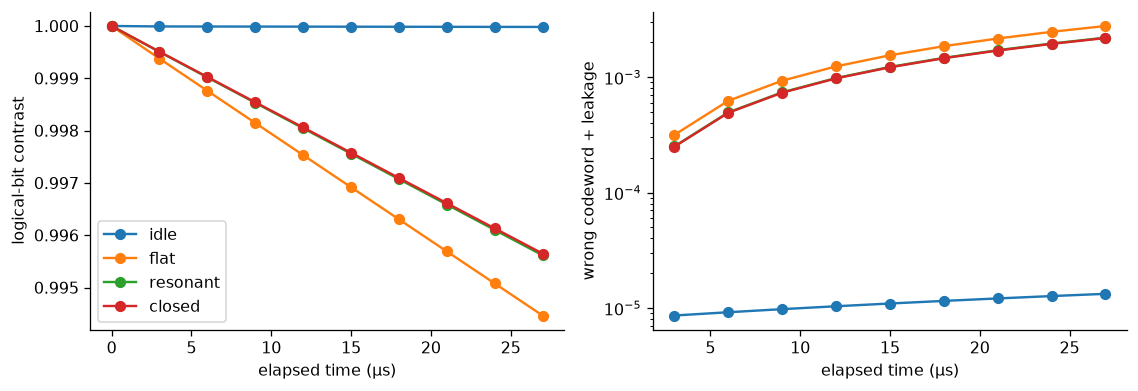

In [33]:
if "audit_load_saved" not in globals():
    raise RuntimeError("run the first addendum cell (audit_load_saved = True) once; it reloads saved results without rerunning the earlier tasks")

if audit_load_saved:
    cycle_table = audit_saved_table("audit_repeated_cycle_rates")
    protection_table = audit_saved_table("audit_bit_protection")
    audit_saved_figure("18_repeated_measurement_cost")
else:
    def audit_cycle_run(spec, na=24, nb=6, cycles=audit_cycles, tolerance=2e-12):
        h, jumps, ops, a, b = two_mode(na, nb)
        times = np.linspace(0, audit_period*cycles, 120*cycles+1)  # 25 ns samples plus exact cycle endpoints
        even = cat_ket(na, alpha, 1)
        odd = cat_ket(na, alpha, -1)
        zero, one = (even+odd)/np.sqrt(2), (even-odd)/np.sqrt(2)
        logical_z = dq.tensor(dq.todm(zero)-dq.todm(one), dq.eye(nb))
        cycle_ops = [*ops, logical_z]  # code-space contrast, with leakage reported independently
        initial = dq.tensor(zero, dq.fock(nb, 0))  # exactly orthogonal logical input for this rate test
        base = run_key(h, jumps, initial, times, cycle_ops, 100*tolerance, tolerance)
        digest = hashlib.sha256((base.stem+json.dumps(spec, sort_keys=True)+"periodic-readout-v1").encode()).hexdigest()
        path = base.with_name(digest+".npz")
        if path.exists():
            with np.load(path, allow_pickle=False) as saved:
                run = {key: saved[key] for key in ["t", "e", "rho"]}
                run["final"] = dq.asqarray(saved["final"], dims=(na, nb))
        else:
            envelope = extension_waveform(spec)
            repeated = lambda t: envelope(jnp.mod(t, audit_period))
            edges = sorted(set(float(c*audit_period+edge) for c in range(cycles)
                               for edge in [0.0, 0.02, spec["duration"]-0.02, spec["duration"]]))
            driven = h+dq.modulated(repeated, a+a.dag(), discontinuity_ts=edges)
            run = evolve(driven, jumps, initial, times, cycle_ops, (na, nb), rtol=100*tolerance, atol=tolerance)
            save_run(path, run)
        zero_array, one_array = [np.asarray(dq.to_numpy(ket)).ravel() for ket in [zero, one]]
        populations = [np.einsum("i,tij,j->t", ket.conj(), run["rho"], ket).real for ket in [zero_array, one_array]]
        run.update({"wrong trace": populations[1], "leakage trace": 1-populations[0]-populations[1],
                    "information trace": 4*kb*cumulative_trapezoid(run["e"][3].real**2, times, initial=0),
                    "spec": dict(spec), "checks": checks(run)})
        return run


    def audit_cycle_fit(run):
        endpoint_indices = np.arange(0, len(run["t"]), 120)
        times, contrast = run["t"][endpoint_indices], run["e"][-1, endpoint_indices].real
        fits = []
        for discard in [2, 3]:
            x, y = times[discard:], np.log(contrast[discard:])  # discard initial relaxation into the repeating schedule
            coefficients, covariance = np.polyfit(x, y, 1, cov=True)
            residual = y-np.polyval(coefficients, x)
            fits.append({"rate": float(-coefficients[0]), "fit standard error": float(np.sqrt(covariance[0, 0])),
                         "fit max log residual": float(np.max(abs(residual)))})
        return {**fits[0], "window change": abs(fits[0]["rate"]-fits[1]["rate"])}


    cycle_runs, cycle_rows = {}, []
    idle_spec = {"kind": "idle", "duration": 1.5, "peak": 0.0}
    for label, spec in {"idle": idle_spec, **selected_specs}.items():
        for na, nb in [(24, 6), (32, 8)]:
            run = audit_cycle_run(spec, na, nb)
            cycle_runs[(label, na, nb)] = run
            fit = audit_cycle_fit(run)
            cycle_rows.append({"pulse": label, "na": na, "nb": nb, **fit,
                               "wrong at end": float(run["wrong trace"][-1]),
                               "leakage at end": float(run["leakage trace"][-1]),
                               "min eigenvalue": run["checks"]["min eigenvalue"]})
            print("repeated measurement:", cycle_rows[-1], flush=True)
    cycle_table = pd.DataFrame(cycle_rows)
    table(cycle_table, "audit_repeated_cycle_rates")

    protection_rows = []
    for label in ["idle", "flat", "resonant", "closed"]:
        small, large = [cycle_table[(cycle_table["pulse"] == label) & (cycle_table["na"] == n)].iloc[0] for n in [24, 32]]
        uncertainty = max(audit_criteria["rate absolute floor"], abs(large["rate"]-small["rate"]),
                          large["window change"], 3*large["fit standard error"])
        protection_rows.append({"pulse": label, "cycle contrast rate per us": large["rate"],
                                "equivalent symmetric flip probability per cycle": float(-0.5*np.expm1(-large["rate"]*audit_period)),
                                "numerical uncertainty indicator": uncertainty,
                                "resolved above numerical indicator": bool(large["rate"] > 3*uncertainty)})
    protection_table = pd.DataFrame(protection_rows)
    table(protection_table, "audit_bit_protection")
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    for label in ["idle", "flat", "resonant", "closed"]:
        run = cycle_runs[(label, 32, 8)]
        indices = np.arange(0, len(run["t"]), 120)
        axes[0].plot(run["t"][indices], run["e"][-1, indices].real, "o-", label=label)
        axes[1].plot(run["t"][indices[1:]], run["wrong trace"][indices[1:]]+run["leakage trace"][indices[1:]], "o-", label=label)  # start after cycle one; zero error at preparation has no logarithm
    axes[0].set(xlabel="elapsed time (μs)", ylabel="logical-bit contrast")
    axes[1].set(xlabel="elapsed time (μs)", ylabel="wrong codeword + leakage", yscale="log")
    axes[0].legend()
    finish_figure(fig, "18_repeated_measurement_cost")

a statistical follow-up with enough power to answer the chosen question

the original 512-record validation comparisons could not certify +/-3 percentage
points: their confidence intervals were already wider than the tolerance. keep
those results above. this follow-up fixes its sample counts before looking at
the new outcomes. the reference pools the original 2048 records with 4096 new
records per protocol. the independent half-step test uses 4096 records.
cutoff and discrete-map tests use common random increments at the *same* step
size, making paired differences more precise. matching seeds across different
step sizes would not produce a valid Brownian coupling, so that test remains
independent. all classifiers and zero thresholds stay frozen.

these are individual 95% intervals, not a simultaneous confidence guarantee
for every reported test. passing equivalence means the whole interval is within
+/-3 points; failing it means this experiment did not establish equivalence.

In [34]:
if "audit_load_saved" not in globals():
    raise RuntimeError("run the first addendum cell (audit_load_saved = True) once; it reloads saved results without rerunning the earlier tasks")

if audit_load_saved:
    audit_saved_table("audit_statistical_plan")
    precision_table = audit_saved_table("audit_assignment_precision")
    precision_check_table = audit_saved_table("audit_assignment_validation")
    precision_comparison = audit_saved_table("audit_assignment_comparison")
else:
    power_rows = []
    for name, n_reference, n_check in [("original validation", 2048, 512), ("new independent validation", 6144, 4096)]:
        standard_error = np.sqrt(0.19*0.81*(1/n_reference+1/n_check))  # planning estimate, not a fitted outcome
        halfwidth = norm.ppf(0.975)*standard_error
        power = max(0.0, float(2*norm.cdf((0.03-halfwidth)/standard_error)-1))
        power_rows.append({"comparison": name, "reference shots": n_reference, "check shots": n_check,
                           "planned 95% halfwidth": halfwidth, "approx equivalence power if difference=0": power})
    table(pd.DataFrame(power_rows), "audit_statistical_plan")


    def audit_paired_interval(differences):
        from scipy.stats import beta  # exact binomial bounds also handle zero observed disagreements
        differences = np.asarray(differences)
        count = len(differences)
        bounds = []
        for direction in [1, -1]:
            events = int(np.count_nonzero(differences == direction))
            low = 0.0 if events == 0 else beta.ppf(0.0125, events, count-events+1)
            high = 1.0 if events == count else beta.ppf(0.9875, events+1, count-events)
            bounds.append((low, high))  # two 97.5% marginal intervals give at least 95% jointly by the union bound
        return float(bounds[0][0]-bounds[1][1]), float(bounds[0][1]-bounds[1][0])

    precision_samples, precision_rows = {}, []
    for label in ["flat", "closed"]:
        spec = selected_specs[label]
        template = extension_run(spec, 24, 6)
        for sign in [1, -1]:
            scores = []
            for repeat in range(2):
                original = trajectory_batch(spec, sign, 20261024+1000*(sign < 0)+repeat, count=512)
                scores.extend(score_records(original, template))  # same original sample, no double counting
            for repeat in range(2):
                new = trajectory_batch(spec, sign, 40261025+1000*(sign < 0)+repeat, count=1024)
                scores.extend(score_records(new, template))
            scores = np.asarray(scores)
            precision_samples[(label, sign)] = {"scores": scores, "errors": sign*scores <= 0}
        errors = np.concatenate([precision_samples[(label, sign)]["errors"] for sign in [1, -1]])
        low, high = wilson_interval(int(errors.sum()), len(errors))
        precision_rows.append({"pulse": label, "shots": len(errors), "errors": int(errors.sum()),
                               "assignment error": float(errors.mean()), "95% low": low, "95% high": high})
        print("larger reference sample:", precision_rows[-1], flush=True)
    precision_table = pd.DataFrame(precision_rows)
    table(precision_table, "audit_assignment_precision")

    precision_check_rows = []
    for label in ["flat", "closed"]:
        spec = selected_specs[label]
        template = extension_run(spec, 24, 6)
        reference = np.concatenate([precision_samples[(label, sign)]["errors"] for sign in [1, -1]])
        halfstep_errors = []
        for sign in [1, -1]:
            for repeat in range(2):
                batch = trajectory_batch(spec, sign, 50261025+1000*(sign < 0)+repeat, count=1024, dt=0.00005)
                halfstep_errors.extend(sign*score_records(batch, template) <= 0)
        halfstep_errors = np.asarray(halfstep_errors, dtype=float)
        delta = halfstep_errors.mean()-reference.mean()
        half = 1.96*np.sqrt(halfstep_errors.var(ddof=1)/len(halfstep_errors)+reference.var(ddof=1)/len(reference))
        precision_check_rows.append({"pulse": label, "test": "independent half timestep", "shots": len(halfstep_errors),
                                     "assignment error": halfstep_errors.mean(), "difference": delta,
                                     "95% low": delta-half, "95% high": delta+half,
                                     "equivalent within 3 points": bool(abs(delta)+half < 0.03)})
        print("precision check:", precision_check_rows[-1], flush=True)
        for condition, na, nb, normalized in [("paired larger cutoffs", 32, 8, False),
                                              ("paired normalized map", 24, 6, True)]:
            differences, checked_errors = [], []
            check_template = extension_run(spec, na, nb)
            for sign in [1, -1]:
                seed = 20261024+1000*(sign < 0)  # same 512 keys and dt as the corresponding original reference batch
                base = trajectory_batch(spec, sign, seed, count=512)
                checked = trajectory_batch(spec, sign, seed, count=512, na=na, nb=nb, map_normalization=normalized)
                base_error = sign*score_records(base, template) <= 0
                checked_error = sign*score_records(checked, check_template) <= 0
                differences.extend(checked_error.astype(float)-base_error.astype(float))
                checked_errors.extend(checked_error)
            differences = np.asarray(differences)
            delta = differences.mean()
            low, high = audit_paired_interval(differences)
            precision_check_rows.append({"pulse": label, "test": condition, "shots": len(differences),
                                         "assignment error": np.mean(checked_errors), "difference": delta,
                                         "95% low": low, "95% high": high,
                                         "equivalent within 3 points": bool(low > -0.03 and high < 0.03)})
            print("precision check:", precision_check_rows[-1], flush=True)
    precision_check_table = pd.DataFrame(precision_check_rows)
    table(precision_check_table, "audit_assignment_validation")

    precision_difference = np.concatenate([precision_samples[("closed", sign)]["errors"].astype(float)
                                           - precision_samples[("flat", sign)]["errors"].astype(float) for sign in [1, -1]])
    precision_low, precision_high = audit_paired_interval(precision_difference)
    precision_comparison = pd.DataFrame([{"comparison": "closed minus flat", "difference": precision_difference.mean(),
                                          "95% low": precision_low, "95% high": precision_high,
                                          "equivalent within 3 points": bool(precision_low > -0.03 and precision_high < 0.03)}])
    table(precision_comparison, "audit_assignment_comparison")

,comparison,reference shots,check shots,planned 95% halfwidth,approx equivalence power if difference=0
0,original validation,2048,512,0.037992,0.00000
1,new independent validation,6144,4096,0.015510,0.93291


,pulse,shots,errors,assignment error,95% low,95% high
0,flat,6144,1158,0.188477,0.178893,0.198449
1,closed,6144,1103,0.179525,0.170129,0.189321


,pulse,test,shots,assignment error,difference,95% low,95% high,equivalent within 3 points
0,flat,independent half timestep,4096,0.188721,0.000244,-0.015225,0.015713,True
1,flat,paired larger cutoffs,1024,0.188477,0.000000,-0.004270,0.004270,True
2,flat,paired normalized map,1024,0.187500,-0.000977,-0.007896,0.006052,True
3,closed,independent half timestep,4096,0.190674,0.011149,-0.004242,0.026540,True
4,closed,paired larger cutoffs,1024,0.178711,0.000977,-0.006052,0.007896,True
5,closed,paired normalized map,1024,0.183594,0.005859,-0.002435,0.013822,True


,comparison,difference,95% low,95% high,equivalent within 3 points
0,closed minus flat,-0.008952,-0.029686,0.011794,True


asking for a more reliable answer costs time and additional bit disturbance

for an approximately coherent output, a gaussian target p requires information
[normal_quantile(1-p)]². the next table uses the actual mean signal of nine
repeated cycles to find the first cycle reaching each target. the gaussian
label matters: a changing bit and excess quantum noise can break that formula.
the long-record experiment then tests the seven-cycle protocol directly, using
the initial stored bit as the answer label even if the bit later flips.
no reset or new preparation occurs between measurements of that same bit.
this longer experiment uses 256 records per initial bit (512 per pulse): it is
an exploratory accuracy check with a reported interval, not a precision test
certifying a one-percent error rate.

,pulse,target gaussian assignment error,required information,first qualifying cycle,elapsed us,wrong at that time,leakage at that time
0,flat,0.20,0.708326,1,3.0,0.000308,0.000008
1,flat,0.10,1.642374,3,9.0,0.000922,0.000008
2,flat,0.05,2.705543,4,12.0,0.001230,0.000008
3,flat,0.01,5.411894,7,21.0,0.002150,0.000008
4,closed,0.20,0.708326,1,3.0,0.000242,0.000008
5,closed,0.10,1.642374,3,9.0,0.000725,0.000008
6,closed,0.05,2.705543,4,12.0,0.000966,0.000008
7,closed,0.01,5.411894,7,21.0,0.001689,0.000008


,pulse,cycles,elapsed us,shots,assignment error,95% low,95% high,gaussian mean-signal estimate,wrong at 21 us,leakage at 21 us
0,flat,7,21.0,512,0.015625,0.007938,0.030526,0.009407,0.002150,0.000008
1,closed,7,21.0,512,0.017578,0.009275,0.033066,0.009433,0.001689,0.000008


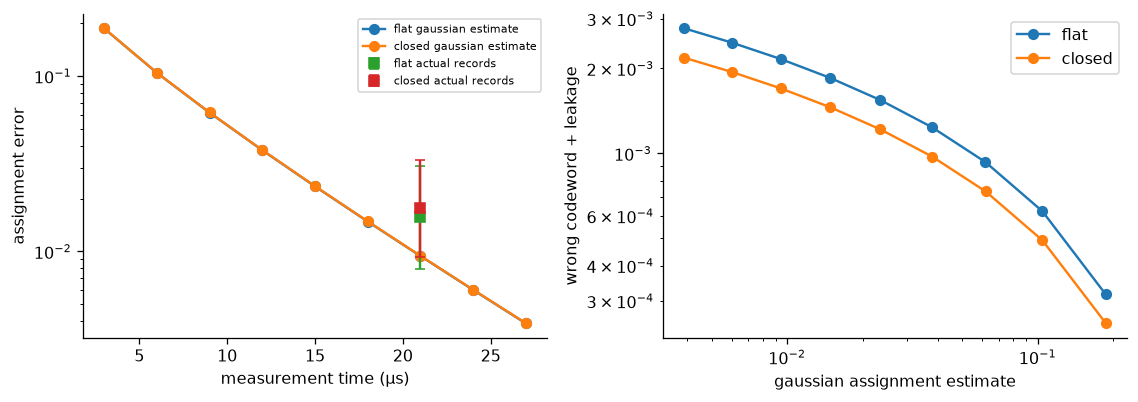

In [35]:
if "audit_load_saved" not in globals():
    raise RuntimeError("run the first addendum cell (audit_load_saved = True) once; it reloads saved results without rerunning the earlier tasks")

if audit_load_saved:
    demand_table = audit_saved_table("audit_readout_demand")
    long_table = audit_saved_table("audit_long_readout")
    audit_saved_figure("19_accuracy_and_bit_damage")
else:
    demand_rows = []
    for label in ["flat", "closed"]:
        run = cycle_runs[(label, 32, 8)]
        for target_error in [0.2, 0.1, 0.05, 0.01]:
            required_information = float(norm.ppf(1-target_error)**2)
            endpoints = np.arange(0, len(run["t"]), 120)
            reached = endpoints[run["information trace"][endpoints] >= required_information]
            index = int(reached[0]) if len(reached) else None
            demand_rows.append({"pulse": label, "target gaussian assignment error": target_error,
                                "required information": required_information,
                                "first qualifying cycle": int(index/120) if index is not None else np.nan,
                                "elapsed us": run["t"][index] if index is not None else np.nan,
                                "wrong at that time": run["wrong trace"][index] if index is not None else np.nan,
                                "leakage at that time": run["leakage trace"][index] if index is not None else np.nan})
    demand_table = pd.DataFrame(demand_rows)
    table(demand_table, "audit_readout_demand")


    def audit_long_records(spec, sign, seed, count=256, cycles=7, na=24, nb=6):
        h, jumps, ops, a, b = two_mode(na, nb)
        initial = dq.tensor(dq.coherent(na, sign*alpha), dq.fock(nb, 0))
        times = np.linspace(0, audit_period*cycles, 600*cycles+1)  # retain the original 5 ns detector bins
        dt = 0.0001
        base = run_key(h, jumps, initial, times, [ops[0]], dt, dt)
        settings = {"spec": spec, "seed": seed, "count": count, "cycles": cycles,
                    "method": "Rouchon1-ket-normalized-periodic-v1"}
        digest = hashlib.sha256((base.stem+json.dumps(settings, sort_keys=True)).encode()).hexdigest()
        path = base.with_name("long-records-"+digest+".npz")
        if path.exists():
            with np.load(path, allow_pickle=False) as saved:
                return {key: saved[key] for key in saved.files}
        envelope = extension_waveform(spec)
        driven = h+dq.modulated(lambda t: envelope(jnp.mod(t, audit_period)), a+a.dag())
        started = time.monotonic()
        result = dq.dssesolve(driven, jumps, initial, times, jax.random.split(jax.random.key(seed), count),
                             exp_ops=[ops[0]], method=dq.method.Rouchon1(dt=dt, normalize=False), save_states=False)
        output = {"t": times, "records": np.asarray(result.measurements)[:, 0, :],
                  "final_n": np.asarray(result.expects)[:, 0, -1].real}
        assert np.isfinite(output["records"]).all()
        np.savez_compressed(path, **output)
        print(f"long records: {spec['kind']}, sign {sign:+d}, {count} shots, {time.monotonic()-started:.1f}s", flush=True)
        return output


    long_rows = []
    for label in ["flat", "closed"]:
        run = cycle_runs[(label, 24, 6)]
        errors = []
        for sign in [1, -1]:
            batch = audit_long_records(selected_specs[label], sign, 60261025+1000*(sign < 0))
            errors.extend(sign*score_records(batch, run) <= 0)
        errors = np.asarray(errors)
        low, high = wilson_interval(int(errors.sum()), len(errors))
        reference = cycle_runs[(label, 32, 8)]
        index = 7*120  # the same seven-cycle horizon, not the end of the nine-cycle deterministic run
        long_rows.append({"pulse": label, "cycles": 7, "elapsed us": 21.0, "shots": len(errors),
                          "assignment error": errors.mean(), "95% low": low, "95% high": high,
                          "gaussian mean-signal estimate": 0.5*erfc(np.sqrt(reference["information trace"][index]/2)),
                          "wrong at 21 us": reference["wrong trace"][index],
                          "leakage at 21 us": reference["leakage trace"][index]})
        print("demanding readout:", long_rows[-1], flush=True)
    long_table = pd.DataFrame(long_rows)
    table(long_table, "audit_long_readout")
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
    for label in ["flat", "closed"]:
        run = cycle_runs[(label, 32, 8)]
        indices = np.arange(120, len(run["t"]), 120)
        gaussian_errors = 0.5*erfc(np.sqrt(run["information trace"][indices]/2))
        axes[0].plot(run["t"][indices], gaussian_errors, "o-", label=label+" gaussian estimate")
        axes[1].plot(gaussian_errors, run["wrong trace"][indices]+run["leakage trace"][indices], "o-", label=label)
    for _, row in long_table.iterrows():
        axes[0].errorbar(row["elapsed us"], row["assignment error"],
                        yerr=[[row["assignment error"]-row["95% low"]], [row["95% high"]-row["assignment error"]]],
                        fmt="s", capsize=3, label=row["pulse"]+" actual records")
    axes[0].set(xlabel="measurement time (μs)", ylabel="assignment error", yscale="log")
    axes[1].set(xlabel="gaussian assignment estimate", ylabel="wrong codeword + leakage", xscale="log", yscale="log")
    axes[0].legend(fontsize=7)
    axes[1].legend()
    finish_figure(fig, "19_accuracy_and_bit_damage")

resource costs and a second cutoff for the recalibrated circuit test

the common hardware constraint so far is peak amplitude. drive energy and
envelope slew are reported here rather than assumed equal. a finite ramp is
not a complete microwave transfer-function model; the actual line bandwidth
would need to be measured or specified before a hardware performance claim.
the circuit comparison is rechecked at larger cutoffs with its recalibrated
amplitudes held fixed. neither its pulse shape nor amplitude is optimized on
that second cutoff.

In [36]:
if "audit_load_saved" not in globals():
    raise RuntimeError("run the first addendum cell (audit_load_saved = True) once; it reloads saved results without rerunning the earlier tasks")

if audit_load_saved:
    resource_rows = audit_saved_table("audit_control_resources").to_dict("records")
    circuit_check_rows = audit_saved_table("audit_circuit_cutoffs").to_dict("records")
else:
    resource_rows, circuit_check_rows = [], []
    resource_times = np.linspace(0, 3, 30001)
    for label, spec in selected_specs.items():
        values = np.asarray(jax.vmap(extension_waveform(spec))(jnp.asarray(resource_times)))
        resource_rows.append({"pulse": label, "actual peak/g2": np.max(abs(values))/g2,
                              "integrated drive squared/g2 squared us": np.trapezoid(values**2, resource_times)/g2**2,
                              "max envelope slew/g2 per us": np.max(abs(np.gradient(values, resource_times)))/g2})
        assert np.max(abs(values)) <= design_peak_limit*(1+1e-8)
        nominal = calibrated_runs[("resonant sine", label)]
        held_out = extension_run(nominal["spec"], 36, 10, corrected=True)
        circuit_check_rows.append({"pulse": label, "information at 32,8": nominal["information"],
                                   "information at 36,10": held_out["information"],
                                   "wrong + leakage at 32,8": nominal["wrong"]+nominal["leakage"],
                                   "wrong + leakage at 36,10": held_out["wrong"]+held_out["leakage"],
                                   "ready us at 36,10": audit_ready(held_out),
                                   "min eigenvalue at 36,10": held_out["checks"]["min eigenvalue"]})
        print("circuit cutoff check:", circuit_check_rows[-1], flush=True)
    table(pd.DataFrame(resource_rows), "audit_control_resources")
    table(pd.DataFrame(circuit_check_rows), "audit_circuit_cutoffs")

,pulse,actual peak/g2,integrated drive squared/g2 squared us,max envelope slew/g2 per us
0,flat,0.372126,0.204255,29.225544
1,resonant,0.444464,0.055995,8.901540
2,closed,0.392015,0.056044,7.355575


,pulse,"information at 32,8","information at 36,10","wrong + leakage at 32,8","wrong + leakage at 36,10","ready us at 36,10","min eigenvalue at 36,10"
0,flat,0.790025,0.790027,0.000360,0.000358,2.22,-1.579408e-08
1,resonant,0.789762,0.789753,0.000252,0.000250,2.03,-1.533265e-08
2,closed,0.789746,0.789739,0.000255,0.000253,1.83,-1.678248e-08


what the completed calculations support

the text printed next is generated from the results above. it supersedes the
earlier provisional summary while leaving that first calculation visible.
'assignment error' means reading the initial stored bit incorrectly. 'wrong
codeword' means changing the stored logical bit. these are different failures.
leakage is also charged explicitly; learning a bit cannot preserve arbitrary
superpositions of that bit. the readout tests use ideal efficiency and the
specified rotating-frame model, not the full device noise budget.

In [37]:
if "audit_load_saved" not in globals():
    raise RuntimeError("run the first addendum cell (audit_load_saved = True) once; it reloads saved results without rerunning the earlier tasks")

if audit_load_saved:
    audit_summary = json.loads((artifacts / "audit_summary.json").read_text())
    findings = (artifacts / "audit_findings.md").read_text()
    display(Markdown(findings))  # these are saved computed findings, not a new numerical run
    print("saved results displayed; no model or trajectory solves were run.")
else:
    from IPython.display import Markdown  # a short result-based interpretation inside the notebook

    final_nominal = pd.read_csv(artifacts / "closed_validation.csv").query("na == 36 and nb == 10").set_index("pulse")
    final_readiness = pd.read_csv(artifacts / "closed_readiness.csv").query("`leakage threshold` == 0.0001").set_index("pulse")
    damage_reduction = 1-final_nominal.loc["closed", "wrong + leakage"]/final_nominal.loc["flat", "wrong + leakage"]
    recovery_reduction = 1-final_readiness.loc["closed", "ready time us"]/final_readiness.loc["flat", "ready time us"]
    resonant_recovery_reduction = 1-final_readiness.loc["closed", "ready time us"]/final_readiness.loc["resonant", "ready time us"]
    final_rates = protection_table.set_index("pulse")
    final_precision = precision_table.set_index("pulse")
    final_long = long_table.set_index("pulse")
    equivalence_pass = bool(precision_comparison.iloc[0]["equivalent within 3 points"])
    validation_pass = bool(precision_check_table["equivalent within 3 points"].all())
    closed_rate = float(final_rates.loc["closed", "cycle contrast rate per us"])
    idle_rate = float(final_rates.loc["idle", "cycle contrast rate per us"])
    rate_resolution = float(final_rates.loc["idle", "numerical uncertainty indicator"])
    idle_resolved = bool(final_rates.loc["idle", "resolved above numerical indicator"])
    preservation_supported = bool(closed_rate <= idle_rate+3*rate_resolution)
    circuit_frame = pd.DataFrame(calibrated_rows)
    circuit_equal = bool(circuit_frame["feasible"].all() and (abs(circuit_frame["information"]/extension_target-1) <= audit_criteria["information relative"]).all())
    audit_summary = {"software_versions": versions, "original_sections_retained": True,
                     "comparison": "ideal-model finite readout and a specified repeated measurement schedule",
                     "wrong_plus_leakage_reduction_vs_flat": float(damage_reduction),
                     "recovery_time_reduction_vs_flat": float(recovery_reduction),
                     "recovery_time_reduction_vs_resonant": float(resonant_recovery_reduction),
                     "equal_information_circuit_and_coupling_checks_pass": circuit_equal,
                     "assignment_equivalence_within_3_points": equivalence_pass,
                     "trajectory_validation_within_3_points": validation_pass,
                     "closed_cycle_contrast_rate_per_us": closed_rate, "idle_cycle_contrast_rate_per_us": idle_rate,
                     "idle_rate_resolved": idle_resolved, "idle_protection_preservation_supported": preservation_supported,
                     "long_readout_cycles": 7, "long_readout_time_us": 21.0,
                     "long_closed_assignment_error": float(final_long.loc["closed", "assignment error"]),
                     "long_closed_assignment_95_interval": [float(final_long.loc["closed", "95% low"]), float(final_long.loc["closed", "95% high"])],
                     "limits": ["ideal detector efficiency", "no thermal bath or microwave-line transfer function",
                                "circuit corrections are resonant RWA corrections", "no established novelty claim",
                                "repeated-cycle rate is not the stationary spectral rate of task 2.1"]}
    (artifacts / "audit_summary.json").write_text(json.dumps(audit_summary, indent=2))
    rate_sentence = (f"the repeated-cycle contrast decay is {closed_rate:.3g}/μs for the closed pulse and {idle_rate:.3g}/μs for idle. "
                     + ("the idle rate is resolved by the stated numerical indicator. " if idle_resolved else "the idle-rate precision is limited by the stated numerical indicator. "))
    if idle_resolved and idle_rate > 0:
        rate_sentence += f"the readout decay is roughly {closed_rate/idle_rate:.0f} times the idle value. "  # the cutoff indicator limits the precision of this ratio
    claim_sentence = ("preserving idle bit protection is consistent with this particular numerical test."
                      if preservation_supported else "this does not preserve idle bit protection: the improvement is relative to another readout, and the measurement still adds substantial bit disturbance.")
    findings = (
        f"the calculated pulse reduces wrong-codeword population plus leakage by {100*damage_reduction:.1f}% against the flat baseline at approximately equal mean-signal information. "
        f"at the declared 1e-4 leakage threshold it recovers {100*recovery_reduction:.1f}% sooner than flat readout and {100*resonant_recovery_reduction:.1f}% sooner than the earlier resonant pulse. "
        "the much smaller final-damage difference against the resonant pulse is not established as a resolved advantage.\n\n"
        f"amplitude recalibration reaches the common information target within the peak cap in every circuit/coupling test: {circuit_equal}. "
        f"the larger-sample assignment comparison establishes equivalence within +/-3 percentage points: {equivalence_pass}. "
        f"all new trajectory-accuracy validation intervals meet that tolerance: {validation_pass}. "
        "these statements concern the specified ideal detector and fixed classifier.\n\n"
        + rate_sentence + claim_sentence + "\n\n"
        f"after seven cycles (21 μs), the closed-pulse receiver misreads the initial bit in {100*final_long.loc['closed', 'assignment error']:.2f}% of records "
        f"(95% interval {100*final_long.loc['closed', '95% low']:.2f}–{100*final_long.loc['closed', '95% high']:.2f}%). "
        "the tables show the extra time and stored-bit damage required for that stronger measurement. the long-record result has its own finite sampling error; the short-record convergence checks do not certify every long-record statistic.\n\n"
        "the contribution is an explainable pulse design and a quantified recovery/error trade-off in this model. "
        "the evidence does not establish a new physical principle, a hardware measurement fidelity, or full satisfaction of the capstone's protection requirement."
    )
    display(Markdown(findings))
    (artifacts / "audit_findings.md").write_text(findings+"\n")
    print("the earlier summary.json is retained; audit_summary.json records the added experiments and their software versions.")

the calculated pulse reduces wrong-codeword population plus leakage by 21.2% against the flat baseline at approximately equal mean-signal information. at the declared 1e-4 leakage threshold it recovers 17.6% sooner than flat readout and 10.1% sooner than the earlier resonant pulse. the much smaller final-damage difference against the resonant pulse is not established as a resolved advantage.

amplitude recalibration reaches the common information target within the peak cap in every circuit/coupling test: True. the larger-sample assignment comparison establishes equivalence within +/-3 percentage points: True. all new trajectory-accuracy validation intervals meet that tolerance: True. these statements concern the specified ideal detector and fixed classifier.

the repeated-cycle contrast decay is 0.000161/μs for the closed pulse and 3.88e-07/μs for idle. the idle rate is resolved by the stated numerical indicator. the readout decay is roughly 415 times the idle value. this does not preserve idle bit protection: the improvement is relative to another readout, and the measurement still adds substantial bit disturbance.

after seven cycles (21 μs), the closed-pulse receiver misreads the initial bit in 1.76% of records (95% interval 0.93–3.31%). the tables show the extra time and stored-bit damage required for that stronger measurement. the long-record result has its own finite sampling error; the short-record convergence checks do not certify every long-record statistic.

the contribution is an explainable pulse design and a quantified recovery/error trade-off in this model. the evidence does not establish a new physical principle, a hardware measurement fidelity, or full satisfaction of the capstone's protection requirement.


saved results displayed; no model or trajectory solves were run.


different approaches, and what each one taught us

this collects the methods already tested above, including the ones that did
not become the final choice. the receiver comparison further down is a new
analysis of saved noisy records; it does not rerun the quantum trajectories.

| approach | question it answers | where to find the actual experiment |
|---|---|---|
| analytic one-mode solution | are units and basic loss implemented correctly? | 1.0a, figures 01–02 |
| effective one-mode stabilization | what happens if the buffer responds instantly? | 1.0c, figures 04–05 |
| full two-mode density matrix | what excitation and ringing does that approximation miss? | 1.1–1.2, figures 06–07 |
| independent cutoff sweeps | is the apparent improvement made by a small hilbert space? | cutoff_convergence.csv |
| coherent seeds of 0, 0.5, 1 and 1.5 | can symmetry breaking prepare one logical well? | 1.3, figure 09 |
| time-domain decay fits and slow generator eigenmodes | do two ways of extracting a rare error agree? | 2.1, bit_flip_rates.csv |
| constant-drive strength sweep | how does a stronger signal damage bit protection? | 2.4b, figure 13 |
| short pulse followed by passive listening | can the stored buffer motion provide the signal? | pulse_candidates.csv |
| resonant pulse | can we deliberately excite the useful ringing? | figures 14 and 16 |
| flat pulses with three durations | does a fairer, duration-tuned baseline change the result? | closed_training.csv |
| endpoint-constrained calculated pulse | can we emit information and reduce leftover motion? | 2.4 extension, figure 16 |
| extra frequency-derivative constraints | does sacrificing design freedom reduce frequency sensitivity? | closed_linear_endpoints.csv |
| quantum measurement trajectories | does the predicted signal survive noisy individual records? | figure 17 and the statistical addendum |
| repeated measurement of the same bit | does the disturbance accumulate? | figure 18 |

these methods have different jobs. a fast approximate design model suggests
controls; the larger quantum calculation tests them. an eigenmode is a rate
check, not another readout pulse. none of these are extra hardware experiments.

In [38]:
from pathlib import Path  # this section also works directly after a kernel restart
import os  # reuse the notebook's writable plotting cache
os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd() / ".cache" / "matplotlib"))
import json  # keep the score dataset's provenance visible
import hashlib  # check that the saved receiver scores match their manifest
import numpy as np  # ordinary arrays are enough for this comparison
import pandas as pd  # read the results already calculated above
import matplotlib.pyplot as plt  # compare methods without running the physical model
from scipy.stats import beta, norm  # exact paired bounds and binomial score intervals
from IPython.display import display, Markdown  # small tables and plain explanations

method_folder = Path("artifacts")  # open the notebook from the project folder
method_training = pd.read_csv(method_folder / "closed_training.csv")  # same training cutoff, (24,6)
method_screen = pd.read_csv(method_folder / "pulse_candidates.csv")  # earlier equal-peak screening
method_endpoints = pd.read_csv(method_folder / "closed_linear_endpoints.csv")  # linear-design sensitivity
print("first screening: same amplitude cap and observation time, different information; not an equal-information ranking")
display(method_screen[["pulse", "matched information", "unweighted information", "wrong codeword", "residual leakage"]])
print("duration and shape comparison: target information 0.79; all rows are the (24,6) training calculation")
display(method_training)  # retain the infeasible short flat pulse and the unselected robust design
method_training.to_csv(method_folder / "method_control_comparison.csv", index=False)  # portable comparison table

first screening: same amplitude cap and observation time, different information; not an equal-information ranking


,pulse,matched information,unweighted information,wrong codeword,residual leakage
0,constant,1.445384,6.911788e-01,0.000697,0.000009
1,short pulse,0.242890,7.520205e-03,0.000083,0.000008
2,resonant,0.989814,4.039736e-07,0.000329,0.000008


duration and shape comparison: target information 0.79; all rows are the (24,6) training calculation


,pulse,feasible,information,peak/g2,wrong,leakage,wrong + leakage
0,flat 0.75 us,False,0.734980,0.500000,0.000331,0.000008,0.000340
1,flat 1.5 us,True,0.791375,0.372126,0.000319,0.000008,0.000327
2,flat 2.25 us,True,0.790004,0.305099,0.000294,0.000041,0.000335
3,resonant 1.5 us,True,0.790015,0.446201,0.000252,0.000008,0.000260
4,closed nominal 1.5 us,True,0.790033,0.392054,0.000251,0.000008,0.000259
5,closed robust 1.5 us,True,0.790873,0.473084,0.000263,0.000008,0.000271


why keep the approaches that did not win?

the short pulse is gentle partly because it emits less information. in the
first screen it reaches only about 0.24, compared with the later target of
0.79. this does not prove that every possible short pulse would fail.
a 0.75 μs flat pulse cannot reach that target under the shared amplitude cap.
extending the flat drive to 2.25 μs lowers its wrong-codeword population but
leaves more leakage by the common 3 μs endpoint. this is why both are counted.

the derivative-constrained pulse is a real alternative, not an assumed better
version. it suppresses leftover *linearized* motion under a frequency change,
but costs more peak amplitude and has more nominal quantum damage here.
it was not selected for the main larger-cutoff and noisy-readout comparisons.
the linear residual below is not a bit-flip probability or a hardware result.

the two calculated pulses close the linear endpoint near numerical precision
at the nominal frequency. that does not imply exact quantum-state closure.
all six training rows are shown together; only the feasible rows approximately
match information. later held-out tests remain the evidence for the final pulse.

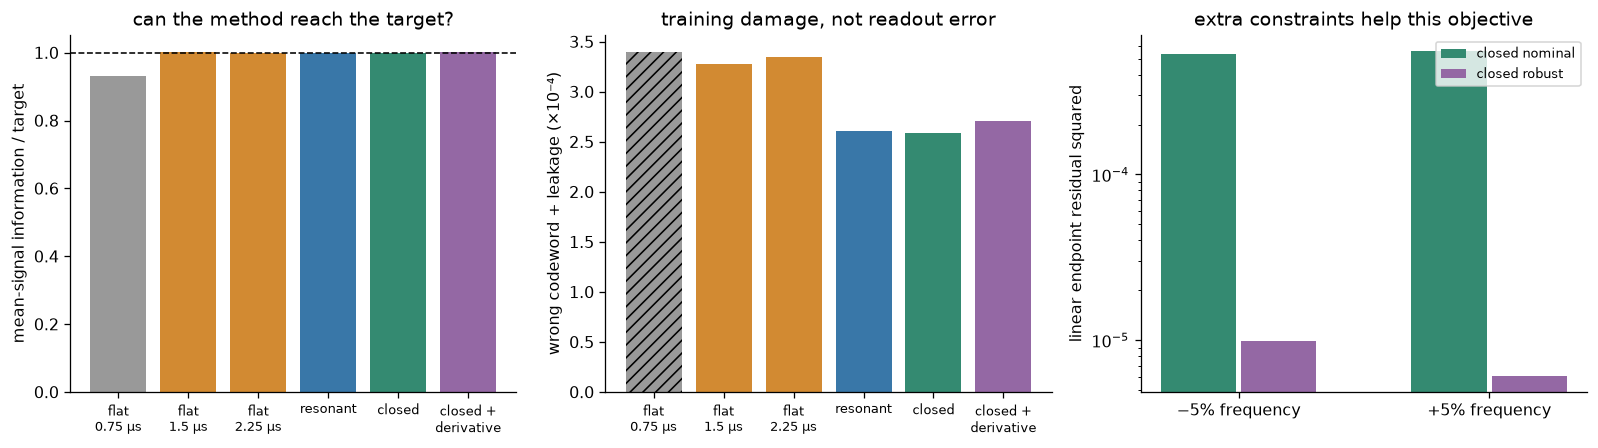

the derivative constraints reduce this linear residual by 54.2× and 91.0× at −5% and +5%.
the nominal quantum training score still favors the simpler closed design; robust frequency closure and minimum bit damage are different objectives.


In [39]:
method_labels = ["flat\n0.75 μs", "flat\n1.5 μs", "flat\n2.25 μs", "resonant", "closed", "closed +\nderivative"]
method_colors = ["#999999", "#d28a32", "#d28a32", "#3977a8", "#348a71", "#9468a4"]  # same families share a color
fig, axes = plt.subplots(1, 3, figsize=(14, 4))  # all panels use the existing training results
axes[0].bar(method_labels, method_training["information"] / 0.79, color=method_colors)
axes[0].axhline(1, color="black", ls="--", lw=1)  # reaching the same target is a prerequisite
axes[0].set(ylabel="mean-signal information / target", title="can the method reach the target?")
damage_bars = axes[1].bar(method_labels, 1e4 * method_training["wrong + leakage"], color=method_colors)
damage_bars[0].set_hatch("///")  # this candidate has lower information and is not a fair competitor
axes[1].set(ylabel="wrong codeword + leakage (×10⁻⁴)", title="training damage, not readout error")
method_offsets = [-0.16, 0.16]  # compare both constrained designs at each mistuning
for offset, label, color in zip(method_offsets, ["closed nominal", "closed robust"], ["#348a71", "#9468a4"]):
    subset = method_endpoints[(method_endpoints["pulse"] == label) & (method_endpoints["exchange factor"] != 1)].sort_values("exchange factor")
    axes[2].bar(np.arange(2) + offset, subset["residual motion squared"], width=0.3, label=label, color=color)
axes[2].set(xticks=np.arange(2), xticklabels=["−5% frequency", "+5% frequency"], yscale="log",
            ylabel="linear endpoint residual squared", title="extra constraints help this objective")
axes[2].legend(fontsize=8)
for axis in axes[:2]:
    axis.tick_params(axis="x", labelsize=8)  # readable labels without a huge figure
fig.tight_layout()
fig.savefig(method_folder / "20_control_methods.png", dpi=170, bbox_inches="tight")
plt.show()  # embed the comparison in the notebook
plt.close(fig)
method_nominal = method_endpoints.query("pulse == 'closed nominal' and `exchange factor` != 1").sort_values("exchange factor")
method_robust = method_endpoints.query("pulse == 'closed robust' and `exchange factor` != 1").sort_values("exchange factor")
method_reductions = method_nominal["residual motion squared"].to_numpy() / method_robust["residual motion squared"].to_numpy()
print(f"the derivative constraints reduce this linear residual by {method_reductions[0]:.1f}× and {method_reductions[1]:.1f}× at −5% and +5%.")
print("the nominal quantum training score still favors the simpler closed design; robust frequency closure and minimum bit damage are different objectives.")

another choice: change the receiver, keeping the physical pulse fixed

this tests four ways to process exactly the same records for each pulse:

- full boxcar: integrate the measured quadrature for all 3 μs.
- drive-only boxcar: integrate only while the 1.5 μs drive is on.
- sign-following: flip the weight when the predicted signal changes sign,
  but do not try to reproduce its detailed amplitude.
- matched filter: weight by the full predicted time-dependent signal.

all thresholds are zero. directions and weights come from the deterministic
positive-bit template, not from fitting the noisy labels. each weight has unit
integrated square; that rescales the score without changing its sign. a pulse
that changes sign can lose its useful signal inside a plain average.

this is an exploratory ablation using the existing 6144 records per pulse,
not a newly collected validation set or an independent replication. we chose
these additional receiver rules after the earlier study; do not call this
preregistered. all four are reported rather than selecting a winner silently.
the saved score dataset contains four fixed projections per original record,
initial labels and weights. its manifest records the frozen controls, seeds,
software versions and hashes of the original trajectory batches. it permits
this small comparison to run without shipping every large raw checkpoint.
the projection formula and optional rebuild are included in the next cell.
leave the rebuild flag false for the fast saved-data comparison. rebuilding
needs the numerical model definitions and original trajectory checkpoints;
a missing checkpoint is reported, rather than launching a new simulation.

the paired difference compares each receiver with the matched filter on the
same records. two exact 97.5% binomial intervals for the opposing disagreements
give a conservative 95% difference interval by the union bound. intervals are
individual comparisons; they are not simultaneous guarantees across the table.
no detector noise, efficiency loss or new measurement backaction is added here.

,pulse,receiver,shots,errors,assignment error,95% low,95% high,difference from matched,paired 95% low,paired 95% high
0,flat,full boxcar,6144,1722,0.280273,0.269183,0.291639,0.091797,0.074800,0.108679
1,flat,drive-only boxcar,6144,1221,0.198730,0.188942,0.208895,0.010254,0.000354,0.020139
2,flat,sign-following,6144,1599,0.260254,0.249435,0.271373,0.071777,0.055253,0.088212
3,flat,matched filter,6144,1158,0.188477,0.178893,0.198449,0.000000,-0.000713,0.000713
4,closed,full boxcar,6144,3088,0.502604,0.490104,0.515101,0.323079,0.300467,0.345299
5,closed,drive-only boxcar,6144,3018,0.491211,0.478720,0.503713,0.311686,0.289158,0.333835
6,closed,sign-following,6144,1852,0.301432,0.290085,0.313028,0.121908,0.103371,0.140294
7,closed,matched filter,6144,1103,0.179525,0.170129,0.189321,0.000000,-0.000713,0.000713


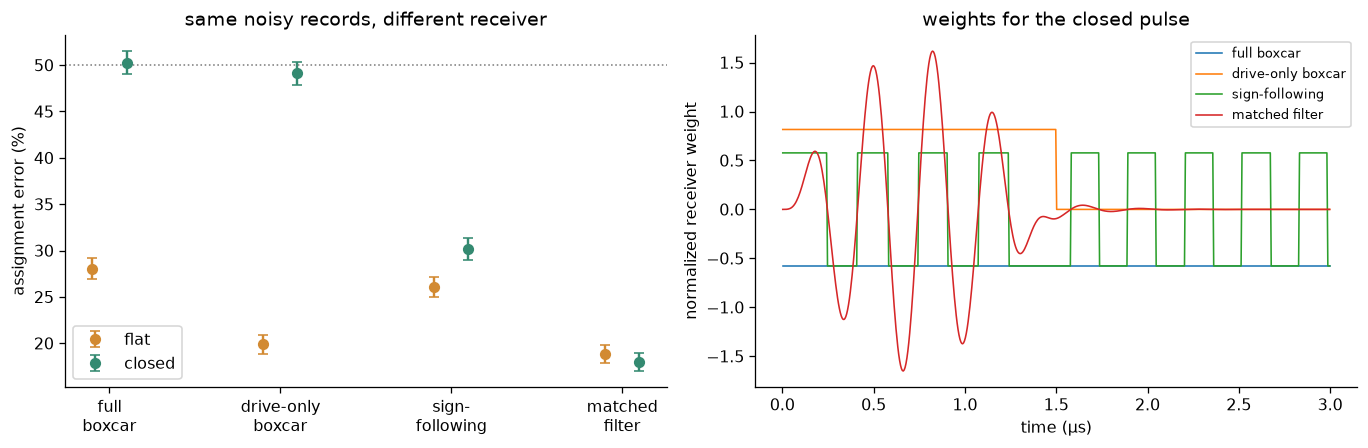

In [40]:
method_rebuild_scores = False  # saved projections are sufficient unless auditing their construction


def method_project_records(records, times, positive_signal, duration):
    widths = np.diff(times)  # measurement arrays contain bin-averaged currents
    midpoint = (times[:-1] + times[1:]) / 2
    signal = (positive_signal[:-1] + positive_signal[1:]) / 2  # same convention as the original filter
    weights = np.stack([np.ones_like(midpoint), (midpoint < duration).astype(float), np.sign(signal), signal], axis=1)
    orientation = np.where(np.sum(weights * signal[:, None] * widths[:, None], axis=0) >= 0, 1, -1)
    weights *= orientation  # choose a positive expected score for the positive bit, without inspecting labels
    weights /= np.sqrt(np.sum(weights**2 * widths[:, None], axis=0))  # positive rescaling leaves decisions unchanged
    return records @ (weights * widths[:, None]), weights  # integrate currents, not just their sample values


if method_rebuild_scores:
    needed = ["selected_specs", "two_mode", "run_key", "extension_run", "dq", "kb", "alpha", "versions"]
    if any(name not in globals() for name in needed):
        raise RuntimeError("projection rebuild needs the numerical model setup; leave method_rebuild_scores = False to compare saved results directly")
    method_payload = {"receiver_names": np.asarray(["full boxcar", "drive-only boxcar", "sign-following", "matched filter"])}
    method_origin = {"description": "fixed linear receiver scores from existing quantum measurement records",
                     "software_versions": versions, "pulses": {}, "threshold": 0,
                     "units": "microseconds", "integration_dt": 0.0001,
                     "sampling_note": "same 6144 records per pulse as audit_assignment_precision.csv; exploratory reuse, not new independent validation"}
    for label in ["flat", "closed"]:
        spec = selected_specs[label]
        model_h, model_jumps, model_ops, model_a, model_b = two_mode(24, 6)
        times = np.linspace(0, 3, 601)  # original record bins, not the stochastic integration step
        batch_paths = []
        for sign in [1, -1]:
            initial = dq.tensor(dq.coherent(24, sign*alpha), dq.fock(6, 0))
            for seed_base, count in [(20261024, 512), (40261025, 1024)]:
                for repeat in range(2):
                    seed = seed_base + 1000*(sign < 0) + repeat
                    base = run_key(model_h, model_jumps, initial, times, [model_ops[0]], 0.0001, 0.0001)
                    settings = {"pulse": spec, "seed": seed, "count": count, "dt": 0.0001,
                                "method": "Rouchon1-ket-normalized-v1"}
                    digest = hashlib.sha256((base.stem + json.dumps(settings, sort_keys=True)).encode()).hexdigest()
                    path = base.with_name("records-" + digest + ".npz")
                    if not path.is_file():
                        raise FileNotFoundError(f"missing original trajectory checkpoint {path}; no new simulation was started")
                    batch_paths.append((path, seed, count, sign))
        template_base = run_key(model_h, model_jumps, dq.tensor(dq.coherent(24, alpha), dq.fock(6, 0)),
                                times, model_ops, 2e-10, 2e-12)  # deterministic template uses the original tighter solver
        template_digest = hashlib.sha256((template_base.stem + json.dumps(spec, sort_keys=True) + "closed-pulse-v1").encode()).hexdigest()
        template_path = template_base.with_name(template_digest + ".npz")
        if not template_path.is_file():
            raise FileNotFoundError(f"missing deterministic template {template_path}; no new simulation was started")
        with np.load(template_path, allow_pickle=False) as saved:
            positive_signal = 2*np.sqrt(kb)*np.interp(times, saved["t"], saved["e"][3].real)
        all_scores, all_signs, sources = [], [], []
        for path, seed, count, sign in batch_paths:
            with np.load(path, allow_pickle=False) as saved:
                if not np.array_equal(saved["t"], times):
                    raise ValueError("trajectory grid differs from the recorded binning")
                scores, weights = method_project_records(saved["records"], times, positive_signal, spec["duration"])
            all_scores.append(scores)
            all_signs.extend([sign]*count)  # labels are stored for evaluation, not used to set weights
            sources.append({"file": path.name, "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
                            "seed": seed, "count": count, "initial_sign": sign})
        method_payload[label + "_scores"] = np.concatenate(all_scores)
        method_payload[label + "_signs"] = np.asarray(all_signs)
        method_payload[label + "_times"] = times
        method_payload[label + "_weights"] = weights
        method_origin["pulses"][label] = {"control": spec, "batches": sources}
    method_output = method_folder / "method_receiver_scores.npz"
    np.savez_compressed(method_output, **method_payload)  # all original checkpoints remain unchanged
    method_origin["scores_sha256"] = hashlib.sha256(method_output.read_bytes()).hexdigest()
    (method_folder / "method_receiver_provenance.json").write_text(json.dumps(method_origin, indent=2) + "\n")

method_manifest = json.loads((method_folder / "method_receiver_provenance.json").read_text())  # original batch identities
method_score_path = method_folder / "method_receiver_scores.npz"
if hashlib.sha256(method_score_path.read_bytes()).hexdigest() != method_manifest["scores_sha256"]:
    raise ValueError("receiver score dataset differs from its provenance manifest")  # stop on changed inputs


def method_wilson(errors, count):
    z = norm.ppf(0.975)  # individual two-sided 95% binomial interval
    fraction = errors / count
    center = (fraction + z*z/(2*count)) / (1 + z*z/count)
    half = z*np.sqrt(fraction*(1-fraction)/count + z*z/(4*count*count)) / (1 + z*z/count)
    return float(center-half), float(center+half)


def method_paired_bounds(differences):
    count = len(differences)  # each observation is one record processed in two ways
    bounds = []
    for direction in [1, -1]:
        events = int(np.count_nonzero(differences == direction))  # opposite directions can cancel in the mean
        low = 0.0 if events == 0 else beta.ppf(0.0125, events, count-events+1)
        high = 1.0 if events == count else beta.ppf(0.9875, events+1, count-events)
        bounds.append((low, high))  # zero disagreements still have nonzero uncertainty
    return float(bounds[0][0]-bounds[1][1]), float(bounds[0][1]-bounds[1][0])


method_reference = pd.read_csv(method_folder / "audit_assignment_precision.csv").set_index("pulse")
method_receiver_rows = []
with np.load(method_score_path, allow_pickle=False) as method_data:
    method_receiver_names = method_data["receiver_names"].tolist()
    method_receiver_weights = {label: method_data[label + "_weights"].copy() for label in ["flat", "closed"]}
    method_receiver_times = method_data["closed_times"].copy()
    for label in ["flat", "closed"]:
        scores = method_data[label + "_scores"]  # rows stay paired across receivers
        signs = method_data[label + "_signs"]  # the initially stored bit is the correct answer
        if scores.shape != (len(signs), 4) or not np.isfinite(scores).all():
            raise ValueError("invalid receiver score array")
        errors = signs[:, None] * scores <= 0  # the classifier uses only a zero threshold, never the label
        if len(signs) != int(method_reference.loc[label, "shots"]) or int(errors[:, -1].sum()) != int(method_reference.loc[label, "errors"]):
            raise ValueError("matched-filter reference does not reproduce the earlier trajectory results")
        for column, receiver in enumerate(method_receiver_names):
            count = len(signs)
            wrong = int(errors[:, column].sum())
            low, high = method_wilson(wrong, count)
            difference = errors[:, column].astype(int) - errors[:, -1].astype(int)
            paired_low, paired_high = method_paired_bounds(difference)
            method_receiver_rows.append({"pulse": label, "receiver": receiver, "shots": count, "errors": wrong,
                                         "assignment error": wrong/count, "95% low": low, "95% high": high,
                                         "difference from matched": float(difference.mean()),
                                         "paired 95% low": paired_low, "paired 95% high": paired_high})
method_receivers = pd.DataFrame(method_receiver_rows)
display(method_receivers)  # full results, including unsuccessful receivers
method_receivers.to_csv(method_folder / "method_receiver_comparison.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
method_positions = np.arange(len(method_receiver_names))
for offset, label, color in [(-0.10, "flat", "#d28a32"), (0.10, "closed", "#348a71")]:
    subset = method_receivers[method_receivers["pulse"] == label]
    estimate = subset["assignment error"].to_numpy()
    error_bars = np.vstack([estimate-subset["95% low"].to_numpy(), subset["95% high"].to_numpy()-estimate])
    axes[0].errorbar(method_positions+offset, 100*estimate, yerr=100*error_bars, fmt="o", capsize=3, label=label, color=color)
axes[0].set(xticks=method_positions, xticklabels=["full\nboxcar", "drive-only\nboxcar", "sign-\nfollowing", "matched\nfilter"],
            ylabel="assignment error (%)", title="same noisy records, different receiver")
axes[0].axhline(50, color="gray", ls=":", lw=1)  # balanced random guessing for context
axes[0].legend()
method_midpoints = (method_receiver_times[:-1] + method_receiver_times[1:]) / 2
for column, receiver in enumerate(method_receiver_names):
    axes[1].plot(method_midpoints, method_receiver_weights["closed"][:, column], label=receiver, lw=1)
axes[1].set(xlabel="time (μs)", ylabel="normalized receiver weight", title="weights for the closed pulse")
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(method_folder / "21_receiver_methods.png", dpi=170, bbox_inches="tight")
plt.show()
plt.close(fig)

what the extra methods do, and do not, change

the control comparison exposes the cost of each constraint, including the
methods that miss the information target. the receiver experiment isolates
classical processing: changing a filter does not alter the physical state
disturbance caused by an already completed measurement. its short-record
error rates should not be confused with the separate 21 μs experiment.

the main idea remains using the underdamped signal while controlling residual
motion. the extra frequency constraints and simpler sign-following receiver
are alternatives with different costs, not automatically improvements. the
earlier limitation also remains: the tested readout does not preserve the
idle bit-flip protection, and no hardware or originality claim follows.

In [41]:
method_closed = method_receivers[method_receivers["pulse"] == "closed"].set_index("receiver")
method_text = (
    f"on the same 6144 closed-pulse records, full boxcar misreads {100*method_closed.loc['full boxcar', 'assignment error']:.2f}%, "
    f"drive-only boxcar {100*method_closed.loc['drive-only boxcar', 'assignment error']:.2f}%, "
    f"sign-following {100*method_closed.loc['sign-following', 'assignment error']:.2f}%, "
    f"and matched filtering {100*method_closed.loc['matched filter', 'assignment error']:.2f}%. "
    "these are paired exploratory comparisons of classical receivers, with uncertainty reported in the table. "
    "they reuse the existing physical simulations; the measured bit damage and the capstone limitation are unchanged."
)
display(Markdown(method_text))  # let the actual numbers decide the lesson
(method_folder / "method_findings.md").write_text(method_text + "\n")

on the same 6144 closed-pulse records, full boxcar misreads 50.26%, drive-only boxcar 49.12%, sign-following 30.14%, and matched filtering 17.95%. these are paired exploratory comparisons of classical receivers, with uncertainty reported in the table. they reuse the existing physical simulations; the measured bit damage and the capstone limitation are unchanged.

365

phase locking under readout: a new diagnostic

the recent two-mode cat-qubit analysis describes a reflection-symmetric,
phase-locked manifold using `Y_a = 0` for the memory and `X_b = 0` for the
buffer. this gives us a useful question for the readout problem: does the
readout pulse merely make a temporary excursion, or does it actually push
the system through a transverse stability boundary?

i measure the transverse coordinates `(Y_a, X_b) = (im<a>, re<b>)`, the area
of that excursion, and the local transverse eigenvalue gap. this is more
informative than only plotting the buffer signal because it tests whether
the readout is still inside the phase-locked geometry.

this is a hypothesis test, not a claim that a new phase transition has been
discovered. the nominal model has no Kerr or cross-Kerr correction, so a
negative result here tells us exactly what extra physics would be needed
before making a stronger claim.

,pulse,max transverse radius,integrated transverse radius squared,transverse loop area,minimum transverse gap per us,maximum transverse growth rate per us,unstable samples,information
0,flat,0.147026,0.016380,0.030036,20.104696,0.0,0,0.791375
1,resonant,0.239301,0.025619,0.458952,20.114160,0.0,0,0.790015
2,closed,0.220943,0.024538,0.414158,20.113911,0.0,0,0.790033


,peak factor,max transverse radius,integrated transverse radius squared,transverse loop area,minimum transverse gap per us,maximum transverse growth rate per us,unstable samples,information
0,0.25,0.055447,0.001546,0.026105,20.114153,0.0,0,0.049759
1,0.50,0.110809,0.006175,0.104244,20.114133,0.0,0,0.198731
2,0.75,0.166002,0.013855,0.233888,20.114100,0.0,0,0.445996
3,1.00,0.220943,0.024538,0.414158,20.113911,0.0,0,0.790033
4,1.25,0.275550,0.038154,0.643841,20.104409,0.0,0,1.228731
5,1.50,0.329741,0.054615,0.921396,20.092450,0.0,0,1.759402
6,2.00,0.436682,0.095633,1.612418,20.059273,0.0,0,3.083165


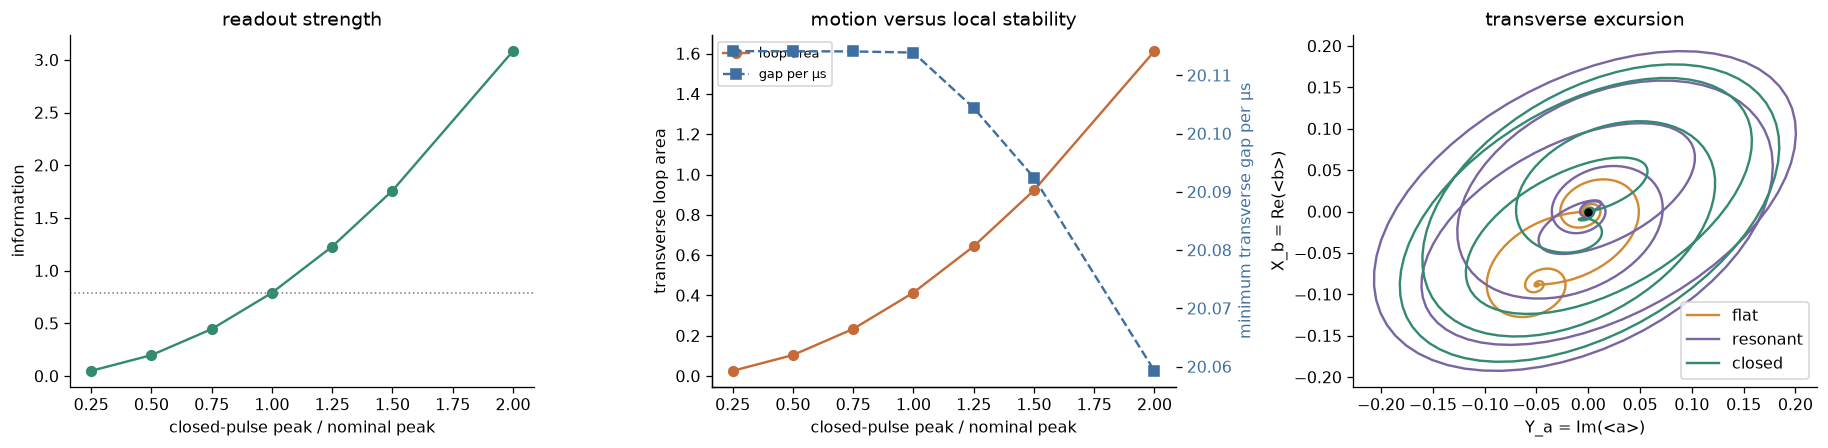

In [42]:
import json  # the saved phase-plane traces are a small json file
from pathlib import Path  # lets this section run after a kernel restart

import matplotlib.pyplot as plt  # the diagnostic has one compact figure
import pandas as pd  # the saved sweep is easier to inspect as a table
from IPython.display import Markdown, display  # keep the conclusion readable in the notebook

phase_lock_load_saved = True  # the saved sweep makes this section quick after a restart
phase_lock_folder = Path("artifacts")  # keep the diagnostic beside the other audit tables
phase_lock_pulses = pd.read_csv(phase_lock_folder / "phase_locking_pulses.csv")  # nominal pulse comparison
phase_lock_sweep = pd.read_csv(phase_lock_folder / "phase_locking_amplitude_sweep.csv")  # strength sweep
phase_lock_traces = json.loads((phase_lock_folder / "phase_locking_traces.json").read_text())  # phase-plane paths

if not phase_lock_load_saved:
    raise RuntimeError("the saved phase-locking sweep is the reproducible default; rerun the export helper first")

display(phase_lock_pulses.round(6))  # the three pulse shapes at the matched information point
display(phase_lock_sweep.round(6))  # increasing strength tests for a stability boundary

fig, axes = plt.subplots(1, 3, figsize=(16, 4))  # one panel for the sweep and two for the geometry
axes[0].plot(phase_lock_sweep["peak factor"], phase_lock_sweep["information"], "o-", color="#348a71")
axes[0].set(xlabel="closed-pulse peak / nominal peak", ylabel="information", title="readout strength")
axes[0].axhline(0.79, color="gray", ls=":", lw=1)  # the matched-information target for context
axes[1].plot(phase_lock_sweep["peak factor"], phase_lock_sweep["transverse loop area"], "o-", color="#c46b39", label="loop area")
gap_axis = axes[1].twinx()  # the gap is much larger numerically, so it gets its own scale
gap_axis.plot(phase_lock_sweep["peak factor"], phase_lock_sweep["minimum transverse gap per us"], "s--", color="#3f6fa0", label="gap per μs")
axes[1].set(xlabel="closed-pulse peak / nominal peak", ylabel="transverse loop area", title="motion versus local stability")
gap_axis.set_ylabel("minimum transverse gap per μs", color="#3f6fa0")
gap_axis.tick_params(axis="y", labelcolor="#3f6fa0")
left_lines, left_labels = axes[1].get_legend_handles_labels()  # combine both y axes in one legend
right_lines, right_labels = gap_axis.get_legend_handles_labels()
axes[1].legend(left_lines + right_lines, left_labels + right_labels, fontsize=8, loc="upper left")
for label, color in [("flat", "#d28a32"), ("resonant", "#7a65a3"), ("closed", "#348a71")]:
    trace = phase_lock_traces[label]  # each curve is a path in the two transverse coordinates
    axes[2].plot(trace["ya"], trace["xb"], color=color, label=label)
axes[2].scatter([0], [0], color="black", s=18, zorder=3)  # ideal phase-locked point
axes[2].set(xlabel="Y_a = Im(<a>)", ylabel="X_b = Re(<b>)", title="transverse excursion")
axes[2].legend()
fig.tight_layout()
fig.savefig(phase_lock_folder / "22_phase_locking_readout.png", dpi=170, bbox_inches="tight")
plt.show()
plt.close(fig)

what this phase-locking test says

the nominal flat, resonant, and closed pulses all remain locally stable in
the ideal model: every trajectory has zero unstable samples and the minimum
transverse gap stays about 20 per microsecond. the closed pulse therefore
does not earn a claim of phase-locking protection just because its residual
ring-down is shaped.

the more interesting observation is geometric. at matched information, the
closed pulse makes a much larger transverse loop than the flat pulse, but a
slightly smaller loop than the resonant pulse. increasing the closed-pulse
peak makes the loop grow smoothly while the gap changes only slightly; no
sharp boundary appears from 0.25x through 2x in this ideal model.

this is a useful negative result: the missing ingredient for a real
breakdown experiment is not another receiver filter. it is a controlled
non-adiabatic or circuit-corrected model in which the transverse Jacobian
can actually change sign. the notebook keeps the diagnostic because it
tells us what to test next and prevents us from calling ordinary ringing a
phase transition.

In [43]:
phase_lock_nominal = phase_lock_pulses.set_index("pulse")  # easier names for the short report below
phase_lock_max_unstable = int(phase_lock_sweep["unstable samples"].max())  # zero means no sampled instability
phase_lock_min_gap = float(phase_lock_sweep["minimum transverse gap per us"].min())
phase_lock_closed_area = float(phase_lock_nominal.loc["closed", "transverse loop area"])
phase_lock_flat_area = float(phase_lock_nominal.loc["flat", "transverse loop area"])
phase_lock_resonant_area = float(phase_lock_nominal.loc["resonant", "transverse loop area"])
phase_lock_text = (
    f"phase-locking audit: the nominal closed pulse has transverse loop area {phase_lock_closed_area:.6f}, "
    f"between flat ({phase_lock_flat_area:.6f}) and resonant ({phase_lock_resonant_area:.6f}). "
    f"the strength sweep found {phase_lock_max_unstable} unstable samples and a smallest local gap of "
    f"{phase_lock_min_gap:.6f} per microsecond over 0.25x–2x peak strength. "
    "there is no resolved phase-locking breakdown in the ideal two-mode model; this is a diagnostic and a "
    "negative result, not a claim of a new phase transition."
)
display(Markdown(phase_lock_text))  # print the conclusion beside the plots so it cannot get separated
(phase_lock_folder / "phase_locking_findings.md").write_text(phase_lock_text + "\n")  # keep a plain-text record too

phase-locking audit: the nominal closed pulse has transverse loop area 0.414158, between flat (0.030036) and resonant (0.458952). the strength sweep found 0 unstable samples and a smallest local gap of 20.059273 per microsecond over 0.25x–2x peak strength. there is no resolved phase-locking breakdown in the ideal two-mode model; this is a diagnostic and a negative result, not a claim of a new phase transition.

414

a second knob for the readout: let the cat expand, then bring it home

the memory pulse gets the bit into the outgoing buffer field. the buffer
stabilization drive fixes the cat size through `alpha² = epsilon_d/g2` in
the steady-state picture. what if i increase that *buffer drive* for only
the 1.5 μs memory pulse, and then return it smoothly to the original value?
the ats flux pump and `g2` stay fixed. this is a temporary cat-size change,
not a different logical encoding for the final comparison.

the added term is `-0.45 epsilon_d sin²(pi t / 1.5) (b+b†)` during the
pulse. the memory drive is recalibrated to keep the same measured buffer
contrast, and its peak stays below the original `0.5 g2` design cap.
both input bits are simulated so a common buffer displacement cannot count
as information. i compare final damage in the original `|±alpha>` code.

the idea combines known ingredients, not a verified first discovery:
[two-mode buffer control](https://doi.org/10.1103/PRXQuantum.4.040316)
and [the role of finite-buffer dynamics](https://arxiv.org/abs/2605.24100).
this exact readout schedule is a challenge-specific proposal. its value has
to come from the matched calculations below, not from calling it novel.

In [44]:
import json  # store the exact control settings with the comparison
from pathlib import Path  # saved tables make a quick restart possible
import numpy as np  # finite-time integrals and codeword projections
import pandas as pd  # show all cutoffs together
import matplotlib.pyplot as plt  # make a compact results figure
from IPython.display import Markdown, display  # keep the result next to its caveats

breath_folder = Path("artifacts")  # same destination as the earlier numerical checks
breath_recompute = False  # true reruns the two-mode model if the earlier model cells were executed
breath_fraction = 0.45  # at the pulse midpoint, epsilon_d is 45% above idle
breath_duration = 1.5  # the buffer drive returns to idle before the 3 μs endpoint


def breath_run(na, nb, fraction, drive_scale, sign, corrected=False):
    h, jumps, ops, a, b = two_mode(na, nb)  # this definition is in the earlier notebook cells
    if corrected:
        exchange, _ = sine_exchange(na, nb, calibrate=True)  # number-dependent resonant circuit correction
        h = exchange - g2*alpha**2*(b+b.dag())  # preserve the calibrated idle buffer drive
    spec = selected_specs["closed"]  # exactly the earlier selected memory waveform
    envelope = extension_waveform(spec)  # one fixed shape, only its height is recalibrated

    def buffer_extra(t):
        inside = (t >= 0) & (t < breath_duration)  # no change during passive listening
        ramp = jnp.sin(jnp.pi*t/breath_duration)**2  # both endpoints are smooth
        return jnp.where(inside, -g2*alpha**2*fraction*ramp, 0.0)

    driven = h + dq.modulated(lambda t: drive_scale*envelope(t), a+a.dag(), discontinuity_ts=[breath_duration])
    driven = driven + dq.modulated(buffer_extra, b+b.dag(), discontinuity_ts=[breath_duration])
    times = np.linspace(0, 3, 601)  # identical recording horizon to the selected pulse
    initial = dq.tensor(dq.coherent(na, sign*alpha), dq.fock(nb, 0))  # the same stored bit
    run = evolve(driven, jumps, initial, times, ops, (na, nb), rtol=2e-10, atol=2e-12)
    even = np.asarray(dq.to_numpy(cat_ket(na, alpha, 1))).ravel()  # original code at the end
    odd = np.asarray(dq.to_numpy(cat_ket(na, alpha, -1))).ravel()
    wrong = (even-sign*odd)/np.sqrt(2)  # the orthogonal wrong logical codeword
    final_memory = run["rho"][-1]  # the buffer is already traced out
    wrong_probability = np.einsum("i,ij,j->", wrong.conj(), final_memory, wrong).real
    code_probability = sum(np.einsum("i,ij,j->", cat.conj(), final_memory, cat).real for cat in [even, odd])
    return run, {"wrong": float(wrong_probability), "leakage": float(1-code_probability),
                 "memory tail max": float(run["e"][5].real.max()),
                 "buffer tail max": float(run["e"][6].real.max())}


def breath_compare(na, nb, fraction, drive_scale, corrected=False):
    plus, plus_result = breath_run(na, nb, fraction, drive_scale, +1, corrected)  # prepared in +alpha
    minus, minus_result = breath_run(na, nb, fraction, drive_scale, -1, corrected)  # prepared in -alpha
    difference = (plus["e"][3].real-minus["e"][3].real)/2  # subtract any common buffer response
    information = float(4*kb*np.trapezoid(difference**2, plus["t"]))  # same ideal mean-signal metric
    damages = [result["wrong"]+result["leakage"] for result in [plus_result, minus_result]]
    return {"pump fraction": fraction, "drive scale": drive_scale, "information": information,
            "worst damage": float(max(damages)), "mean damage": float(np.mean(damages)),
            "memory tail max": max(plus_result["memory tail max"], minus_result["memory tail max"]),
            "buffer tail max": max(plus_result["buffer tail max"], minus_result["buffer tail max"]),
            "mean buffer offset max": float(np.max(np.abs((plus["e"][3].real+minus["e"][3].real)/2)))}


if breath_recompute:
    requirements = ["two_mode", "sine_exchange", "selected_specs", "extension_waveform", "evolve", "dq", "jnp", "cat_ket", "g2", "kb", "alpha"]
    if any(name not in globals() for name in requirements):
        raise RuntimeError("run the earlier model cells before asking for new Lindblad solves")
    unscaled = [breath_compare(24, 6, fraction, 1.0) for fraction in [0.0, 0.15, 0.30, 0.45]]
    pd.DataFrame(unscaled).to_csv(breath_folder / "pump_assisted_exploratory.csv", index=False)
    for filename, cutoff, scale, corrected in [
        ("pump_assisted_matched_exploratory.csv", (24, 6), 1.111, False),
        ("pump_assisted_cutoff_exploratory.csv", (32, 8), 1.111, False),
        ("pump_assisted_cutoff_36_10_exploratory.csv", (36, 10), 1.111, False),
        ("pump_assisted_circuit_32_8_exploratory.csv", (32, 8), 1.137, True),
    ]:
        row = breath_compare(*cutoff, breath_fraction, scale, corrected)  # full model, both stored bits
        pd.DataFrame([row]).to_csv(breath_folder / filename, index=False)

breath_exploratory = pd.read_csv(breath_folder / "pump_assisted_exploratory.csv")
breath_files = ["pump_assisted_matched_exploratory.csv", "pump_assisted_cutoff_exploratory.csv",
                "pump_assisted_cutoff_36_10_exploratory.csv", "pump_assisted_circuit_32_8_exploratory.csv"]
breath_candidates = [pd.read_csv(breath_folder / name).query("`pump fraction` == @breath_fraction").iloc[0]
                     for name in breath_files]  # select the declared 45% ramp in every file
breath_baseline = pd.read_csv(breath_folder / "closed_validation.csv")  # original ideal cutoff checks
breath_circuit = pd.read_csv(breath_folder / "audit_equal_information_circuit.csv")  # original circuit check
breath_training = pd.read_csv(breath_folder / "closed_training.csv")  # saved peak of the selected memory pulse
breath_peak_ratio = float(breath_training.query("pulse == 'closed nominal 1.5 us'")["peak/g2"].iloc[0])
breath_rows = []
for model, na, nb, candidate in [("ideal", 24, 6, breath_candidates[0]),
                                 ("ideal", 32, 8, breath_candidates[1]),
                                 ("ideal", 36, 10, breath_candidates[2]),
                                 ("resonant sine", 32, 8, breath_candidates[3])]:
    if model == "ideal":
        baseline = breath_baseline.query("pulse == 'closed' and na == @na and nb == @nb").iloc[0]
    else:
        baseline = breath_circuit.query("condition == 'resonant sine' and pulse == 'closed'").iloc[0]
    breath_rows.append({"model": model, "na": na, "nb": nb, "baseline information": float(baseline["information"]),
                        "breathing information": float(candidate["information"]),
                        "baseline damage": float(baseline["wrong + leakage"]),
                        "breathing damage": float(candidate["worst damage"]),
                        "damage reduction %": float(100*(1-candidate["worst damage"]/baseline["wrong + leakage"])),
                        "memory peak/g2": float(breath_peak_ratio*candidate["drive scale"]),
                        "memory tail max": float(candidate["memory tail max"]),
                        "buffer tail max": float(candidate["buffer tail max"])})
breath_matched = pd.DataFrame(breath_rows)  # each row compares the same model and cutoff
display(breath_exploratory.round(7))  # no hidden cherry-picking of the initial amplitude scan
display(breath_matched.round(7))  # the headline comparison includes all cutoff checks
breath_matched.to_csv(breath_folder / "pump_breathing_comparison.csv", index=False)

,pump fraction,information,worst damage,mean damage,memory tail max,buffer tail max,mean buffer offset max
0,0.00,0.790033,0.000259,0.000259,1.000000e-07,0.000020,0.0
1,0.15,0.765282,0.000120,0.000120,6.000000e-07,0.000016,0.0
2,0.30,0.710194,0.000069,0.000069,2.300000e-06,0.000014,0.0
3,0.45,0.640400,0.000061,0.000061,8.000000e-06,0.000015,0.0


,model,na,nb,baseline information,breathing information,baseline damage,breathing damage,damage reduction %,memory peak/g2,memory tail max,buffer tail max
0,ideal,24,6,0.790033,0.789650,0.000259,0.000071,72.550785,0.435572,9.300000e-06,1.850000e-05
1,ideal,32,8,0.790007,0.789761,0.000250,0.000045,82.040350,0.435572,0.000000e+00,2.400000e-06
2,ideal,36,10,0.790004,0.789764,0.000248,0.000044,82.191315,0.435572,0.000000e+00,6.000000e-07
3,resonant sine,32,8,0.789746,0.790540,0.000255,0.000064,74.728033,0.445765,2.000000e-07,4.800000e-06


does it survive using the same memory repeatedly?

i repeat the *whole* 3 μs cycle, including the 1.5 μs buffer-drive ramp and
1.5 μs listening window. the initial bit is prepared only once, and the buffer
is never manually reset. the rate comes from a log fit to the logical contrast
at cycle endpoints 2 through 9, exactly as for the earlier baseline.

the old phase-locking figure uses the magnitude of complex Jacobian
eigenvalues for its gap. that magnitude is not the decay rate: the real
parts decide whether a perturbation grows. its zero-unstable-samples result
remains a local diagnostic, not an explanation of the improvement here.

,na,nb,baseline rate per us,breathing rate per us,rate reduction %
0,24,6,0.000167,0.000042,74.897313
1,32,8,0.000161,0.000025,84.790598
2,36,10,NaN,0.000024,NaN


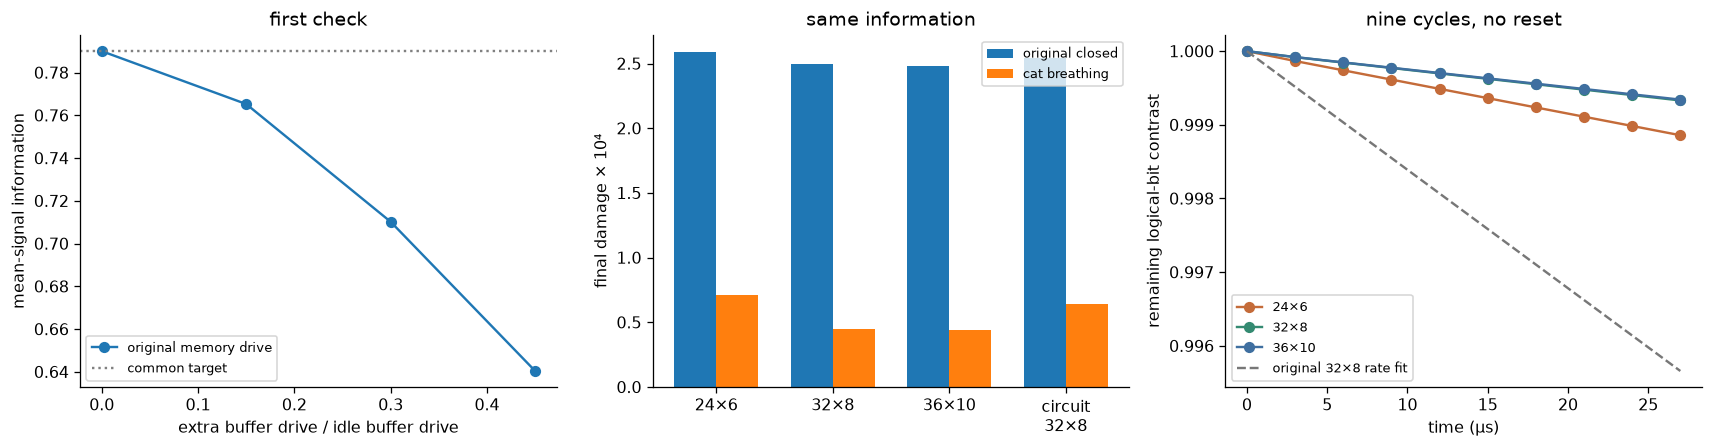

In [45]:
breath_recompute_cycles = False  # leave false for quick display of the saved 9-cycle runs


def breath_cycle_run(na, nb, cycles=9):
    spec = selected_specs["closed"]  # the same pulse as above, repeated without reset
    h, jumps, ops, a, b = two_mode(na, nb)
    even, odd = cat_ket(na, alpha, 1), cat_ket(na, alpha, -1)
    zero, one = (even+odd)/np.sqrt(2), (even-odd)/np.sqrt(2)  # orthogonal logical states
    logical_z = dq.tensor(dq.todm(zero)-dq.todm(one), dq.eye(nb))  # stored-bit contrast
    initial = dq.tensor(zero, dq.fock(nb, 0))  # exactly one preparation before all nine cycles
    envelope = extension_waveform(spec)

    def readout(t):
        return 1.111*envelope(jnp.mod(t, 3.0))  # same matched memory drive in each cycle

    def buffer_extra(t):
        phase = jnp.mod(t, 3.0)  # local clock resets the control, not the quantum state
        inside = (phase >= 0) & (phase < breath_duration)
        ramp = jnp.sin(jnp.pi*phase/breath_duration)**2
        return jnp.where(inside, -g2*alpha**2*breath_fraction*ramp, 0.0)

    driven = h + dq.modulated(readout, a+a.dag()) + dq.modulated(buffer_extra, b+b.dag())
    times = np.linspace(0, 3*cycles, 120*cycles+1)
    result = dq.mesolve(driven, jumps, initial, jnp.asarray(times), exp_ops=[logical_z, *ops],
                       method=dq.method.Tsit5(rtol=2e-10, atol=2e-12, max_steps=2_000_000), save_states=False)
    expectation = np.asarray(result.expects)  # no full two-mode density matrix needs to be stored
    endpoints = np.arange(0, len(times), 120)
    contrast = expectation[0, endpoints].real
    rate = float(-np.polyfit(times[endpoints][2:], np.log(contrast[2:]), 1)[0])
    return pd.DataFrame({"na": na, "nb": nb, "cycle": endpoints//120, "time": times[endpoints],
                         "contrast": contrast, "memory tail": expectation[6, endpoints].real,
                         "buffer tail": expectation[7, endpoints].real, "bit decay rate": rate})


if breath_recompute_cycles:
    if any(name not in globals() for name in ["two_mode", "selected_specs", "dq", "jnp", "g2", "alpha"]):
        raise RuntimeError("run the earlier model cells before repeating the Lindblad calculation")
    for na, nb in [(24, 6), (32, 8), (36, 10)]:
        breath_cycle_run(na, nb).to_csv(breath_folder / f"pump_assisted_cycles_{na}_{nb}.csv", index=False)

breath_cycles = {cutoff: pd.read_csv(breath_folder / f"pump_assisted_cycles_{cutoff[0]}_{cutoff[1]}.csv")
                 for cutoff in [(24, 6), (32, 8), (36, 10)]}  # check convergence of the repeated-cycle rate
breath_old_cycles = pd.read_csv(breath_folder / "audit_repeated_cycle_rates.csv")
breath_cycle_rows = []
for na, nb in [(24, 6), (32, 8), (36, 10)]:
    new = breath_cycles[(na, nb)]
    old_rows = breath_old_cycles.query("pulse == 'closed' and na == @na and nb == @nb")
    old_rate = float(old_rows["rate"].iloc[0]) if len(old_rows) else np.nan  # baseline 36×10 was not simulated
    new_rate = float(new["bit decay rate"].iloc[0])
    breath_cycle_rows.append({"na": na, "nb": nb, "baseline rate per us": old_rate,
                              "breathing rate per us": new_rate,
                              "rate reduction %": float(100*(1-new_rate/old_rate)) if np.isfinite(old_rate) else np.nan})
breath_cycle_table = pd.DataFrame(breath_cycle_rows)
display(breath_cycle_table.round(8))
breath_cycle_table.to_csv(breath_folder / "pump_breathing_cycle_rates.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))  # signal, final damage, and repeated-bit protection
axes[0].plot(breath_exploratory["pump fraction"], breath_exploratory["information"], "o-", label="original memory drive")
axes[0].axhline(0.79, color="gray", ls=":", label="common target")
axes[0].set(xlabel="extra buffer drive / idle buffer drive", ylabel="mean-signal information", title="first check")
axes[0].legend(fontsize=8)
positions = np.arange(len(breath_matched))
axes[1].bar(positions-0.18, 1e4*breath_matched["baseline damage"], width=0.36, label="original closed")
axes[1].bar(positions+0.18, 1e4*breath_matched["breathing damage"], width=0.36, label="cat breathing")
axes[1].set(xticks=positions, xticklabels=["24×6", "32×8", "36×10", "circuit\n32×8"],
            ylabel="final damage × 10⁴", title="same information")
axes[1].legend(fontsize=8)
for cutoff, color in [((24, 6), "#c46b39"), ((32, 8), "#348a71"), ((36, 10), "#3f6fa0")]:
    trial = breath_cycles[cutoff]
    axes[2].plot(trial["time"], trial["contrast"], "o-", color=color, label=f"{cutoff[0]}×{cutoff[1]}")
baseline_rate = float(breath_old_cycles.query("pulse == 'closed' and na == 32 and nb == 8")["rate"].iloc[0])
axes[2].plot(breath_cycles[(32, 8)]["time"], np.exp(-baseline_rate*breath_cycles[(32, 8)]["time"]),
             "--", color="#777777", label="original 32×8 rate fit")  # the fit is a guide, not raw endpoint data
axes[2].set(xlabel="time (μs)", ylabel="remaining logical-bit contrast", title="nine cycles, no reset")
axes[2].legend(fontsize=8)
fig.tight_layout()
fig.savefig(breath_folder / "23_cat_breathing_readout.png", dpi=170, bbox_inches="tight")
plt.show()
plt.close(fig)

where this really stands

the matched ideal-model result survives `24×6`, `32×8`, and `36×10`.
the repeated-cycle rate also drops and is close between `32×8` and `36×10`.
the resonant-sine circuit correction
still favors the extra buffer drive. that is stronger evidence than a single
attractive endpoint. it is still an ideal-detector, model-specific control
proposal. stochastic receiver errors, flux-dependent shifts, heating,
amplifier noise, and a hardware drive limit on `epsilon_d` remain untested.
the same mean-signal information does not by itself prove equal single-shot
assignment fidelity. and the repeated-cycle rate still exceeds idle.

at the pulse midpoint `alpha²` would be 45% bigger in the static picture.
the full two-mode simulation, rather than this static approximation, produced
every damage number above. the temporary deformation may shield the well
crossing while the memory drive is on; a trajectory-level mechanism test is
the next experiment, not a conclusion hidden inside this table.

In [46]:
breath_best = breath_matched.query("model == 'ideal' and na == 36 and nb == 10").iloc[0]
breath_rate = breath_cycle_table.query("na == 32 and nb == 8").iloc[0]
breath_circuit_row = breath_matched.query("model == 'resonant sine'").iloc[0]
breath_text = (
    f"with equal mean-signal information, the temporary buffer-drive ramp lowers final wrong-codeword "
    f"plus leakage by {breath_best['damage reduction %']:.1f}% at 36×10. "
    f"the nine-cycle logical contrast rate falls by {breath_rate['rate reduction %']:.1f}% at 32×8, "
    f"and the resonant-sine circuit test shows a {breath_circuit_row['damage reduction %']:.1f}% endpoint reduction. "
    "these are model results; single-shot receiver fidelity and hardware limits need separate tests."
)
display(Markdown(breath_text))  # put the useful finding and its limit in the same sentence
(breath_folder / "pump_breathing_findings.md").write_text(breath_text + "\n")

with equal mean-signal information, the temporary buffer-drive ramp lowers final wrong-codeword plus leakage by 82.2% at 36×10. the nine-cycle logical contrast rate falls by 84.8% at 32×8, and the resonant-sine circuit test shows a 74.7% endpoint reduction. these are model results; single-shot receiver fidelity and hardware limits need separate tests.

354

do the noisy records still read the bit?

equal mean-signal information can miss extra noise or backaction. i reused
the original 512-record seeds for each stored bit and ran 512 new homodyne
trajectories for each one. the buffer record alone goes into the receiver.
its weight comes from the new positive-bit deterministic buffer trace, not
the noisy labels. the original pulse's scores use those same seeds, so the
error comparison can be paired record by record.

i use a conservative paired interval because a difference of a few errors
in 1024 records is easy to overinterpret. the interval below is a 95% bound
on the difference in assignment-error fractions, new minus original.

In [47]:
from scipy.stats import beta  # exact binomial bounds for opposing disagreements

breath_receiver_recompute = False  # true requires the earlier model cells and reruns 1024 trajectories
breath_receiver_path = breath_folder / "pump_breathing_receiver_scores.npz"

if breath_receiver_recompute:
    if any(name not in globals() for name in ["dq", "jax", "jnp", "two_mode", "selected_specs", "breath_run", "extension_waveform"]):
        raise RuntimeError("run the earlier two-mode model cells before generating new homodyne records")
    spec = selected_specs["closed"]
    h, jumps, ops, a, b = two_mode(24, 6)  # the same 24×6 stochastic setup as the earlier records
    envelope = extension_waveform(spec)

    def receiver_extra(t):
        inside = (t >= 0) & (t < breath_duration)
        ramp = jnp.sin(jnp.pi*t/breath_duration)**2
        return jnp.where(inside, -g2*alpha**2*breath_fraction*ramp, 0.0)

    driven = h + dq.modulated(lambda t: 1.111*envelope(t), a+a.dag())
    driven = driven + dq.modulated(receiver_extra, b+b.dag())
    template, _ = breath_run(24, 6, breath_fraction, 1.111, +1)  # weight never sees the noisy labels
    times = np.linspace(0, 3, 601)
    widths = np.diff(times)
    weight = np.sqrt(kb)*(template["e"][3].real[:-1]+template["e"][3].real[1:])
    weight /= np.sqrt(np.sum(weight**2*widths))  # multiplying by a positive constant cannot change a decision
    with np.load(breath_folder / "method_receiver_scores.npz", allow_pickle=False) as old_data:
        old_scores = [old_data["closed_scores"][:512, -1].copy(),
                      old_data["closed_scores"][3072:3584, -1].copy()]
    scores = []
    for sign, seed in [(+1, 20261024), (-1, 20262024)]:
        initial = dq.tensor(dq.coherent(24, sign*alpha), dq.fock(6, 0))
        keys = jax.random.split(jax.random.key(seed), 512)
        trial = dq.dssesolve(driven, jumps, initial, times, keys, exp_ops=[ops[0]],
                            method=dq.method.Rouchon1(dt=0.0001, normalize=False), save_states=False)
        record = np.asarray(trial.measurements)[:, 0, :]  # only the monitored buffer channel
        scores.append(record @ (weight*widths))  # integrated fixed matched filter
    np.savez_compressed(breath_receiver_path, scores=np.concatenate(scores),
                        signs=np.r_[np.ones(512), -np.ones(512)],
                        original_scores=np.concatenate(old_scores), times=times, weight=weight)

with np.load(breath_receiver_path, allow_pickle=False) as saved:
    breath_signs = saved["signs"]
    breath_scores = saved["scores"]
    breath_original_scores = saved["original_scores"]
breath_new_errors = breath_signs*breath_scores <= 0  # the zero threshold is fixed before examining labels
breath_old_errors = breath_signs*breath_original_scores <= 0
breath_shots = len(breath_signs)
breath_new_only = int(np.count_nonzero(breath_new_errors & ~breath_old_errors))
breath_old_only = int(np.count_nonzero(breath_old_errors & ~breath_new_errors))


def breath_disagreement_bounds(events, count):
    low = 0.0 if events == 0 else beta.ppf(0.0125, events, count-events+1)  # 97.5% exact bound
    high = 1.0 if events == count else beta.ppf(0.9875, events+1, count-events)
    return low, high


breath_worse_interval = breath_disagreement_bounds(breath_new_only, breath_shots)
breath_better_interval = breath_disagreement_bounds(breath_old_only, breath_shots)
breath_receiver_table = pd.DataFrame([{"shots": breath_shots,
                                      "original errors": int(breath_old_errors.sum()),
                                      "breathing errors": int(breath_new_errors.sum()),
                                      "original error fraction": float(breath_old_errors.mean()),
                                      "breathing error fraction": float(breath_new_errors.mean()),
                                      "new-only errors": breath_new_only, "original-only errors": breath_old_only,
                                      "paired difference": float(breath_new_errors.mean()-breath_old_errors.mean()),
                                      "paired 95% low": float(breath_worse_interval[0]-breath_better_interval[1]),
                                      "paired 95% high": float(breath_worse_interval[1]-breath_better_interval[0])}])
display(breath_receiver_table.round(5))  # all errors, disagreements, and uncertainty in one row
breath_receiver_table.to_csv(breath_folder / "pump_breathing_receiver_comparison.csv", index=False)

,shots,original errors,breathing errors,original error fraction,breathing error fraction,new-only errors,original-only errors,paired difference,paired 95% low,paired 95% high
0,1024,182,162,0.17773,0.1582,53,73,-0.01953,-0.054,0.0151


the 1024-record test has 162 errors for the breathing pulse and 182 for the
original pulse. the paired interval still includes zero, so this test does
not prove an accuracy improvement. it also does not certify equivalence to
within three percentage points. what it does give us is a real noisy-record
check alongside the converged deterministic damage and repeated-cycle rates.

these noisy trajectories do not include cross-Kerr, a thermal bath,
amplifier bandwidth or a measured hardware limit on the extra buffer drive.
the next deterministic test checks one of those missing effects.

try to break the idea with nonlinear buffer physics

[recent two-mode work](https://arxiv.org/html/2605.24100v1) shows why the
ideal memory-buffer model can be optimistic: cross-Kerr and dephasing can
spoil bit-flip protection, and the buffer can have a sizeable Kerr term.
i add `K_b/2 b†²b² + chi n_a n_b` and a memory dephasing jump. the chosen
stress parameters are `K_b/2pi = 3.3 MHz`, `chi/2pi = 0.15 MHz`, and
`kappa_phi/2pi = 1 kHz`. they are a plausible separate model test, not
circuit coefficients derived from this challenge's illustrative ATS table.

both memory drives are independently recalibrated under these *same*
nonlinear terms to the 0.79 information target. i still compare against the
original `|±alpha>` code and simulate both bits, so the nonlinear common
buffer offset cannot inflate the information. this test does not include
the paper's finite thermal population or pump-induced dissipative effects.

In [48]:
breath_nonlinear_recompute = False  # true needs the earlier model cells and runs eight new master equations


def breath_nonlinear_run(na, nb, fraction, drive_scale, sign):
    h, jumps, ops, a, b = two_mode(na, nb)  # start from the same two-mode setup
    number_a, number_b = a.dag()@a, b.dag()@b
    h = h + (2*np.pi*3.3)/2*(b.dag()@b.dag()@b@b)  # buffer self-Kerr in rad/μs
    h = h + (2*np.pi*0.15)*(number_a@number_b)  # memory-buffer cross-Kerr
    jumps = [*jumps, np.sqrt(2*np.pi*0.001)*number_a]  # one extra dephasing channel
    spec = selected_specs["closed"]
    envelope = extension_waveform(spec)

    def extra_buffer(t):
        inside = (t >= 0) & (t < spec["duration"])
        ramp = jnp.sin(jnp.pi*t/spec["duration"])**2
        return jnp.where(inside, -g2*alpha**2*fraction*ramp, 0.0)

    driven = h + dq.modulated(lambda t: drive_scale*envelope(t), a+a.dag())
    driven = driven + dq.modulated(extra_buffer, b+b.dag())
    times = np.linspace(0, 3, 601)
    initial = dq.tensor(dq.coherent(na, sign*alpha), dq.fock(nb, 0))
    run = evolve(driven, jumps, initial, times, ops, (na, nb), rtol=2e-10, atol=2e-12)
    even = np.asarray(dq.to_numpy(cat_ket(na, alpha, 1))).ravel()
    odd = np.asarray(dq.to_numpy(cat_ket(na, alpha, -1))).ravel()
    wrong = (even-sign*odd)/np.sqrt(2)
    final_memory = run["rho"][-1]
    wrong_probability = np.einsum("i,ij,j->", wrong.conj(), final_memory, wrong).real
    code_probability = sum(np.einsum("i,ij,j->", cat.conj(), final_memory, cat).real for cat in [even, odd])
    return run, {"wrong": float(wrong_probability), "leakage": float(1-code_probability),
                 "memory tail max": float(run["e"][5].real.max()),
                 "buffer tail max": float(run["e"][6].real.max())}


def breath_nonlinear_compare(na, nb, fraction, drive_scale):
    plus, plus_result = breath_nonlinear_run(na, nb, fraction, drive_scale, +1)
    minus, minus_result = breath_nonlinear_run(na, nb, fraction, drive_scale, -1)
    difference = (plus["e"][3].real-minus["e"][3].real)/2
    damages = [result["wrong"]+result["leakage"] for result in [plus_result, minus_result]]
    return {"buffer fraction": fraction, "drive scale": drive_scale,
            "information": float(4*kb*np.trapezoid(difference**2, plus["t"])),
            "worst damage": float(max(damages)),
            "memory tail max": max(plus_result["memory tail max"], minus_result["memory tail max"]),
            "buffer tail max": max(plus_result["buffer tail max"], minus_result["buffer tail max"]),
            "common buffer max": float(np.max(np.abs((plus["e"][3].real+minus["e"][3].real)/2)))}


if breath_nonlinear_recompute:
    if any(name not in globals() for name in ["two_mode", "selected_specs", "extension_waveform", "evolve", "dq", "jnp", "cat_ket"]):
        raise RuntimeError("run the earlier two-mode model cells before the nonlinear stress test")
    for na, nb in [(24, 6), (32, 8)]:
        trials = [breath_nonlinear_compare(na, nb, fraction, scale)
                  for fraction, scale in [(0.0, 1.166), (0.45, 1.196)]]
        suffix = "" if na == 24 else "_32_8"
        pd.DataFrame(trials).to_csv(breath_folder / f"pump_breathing_nonlinear_calibrated{suffix}.csv", index=False)

breath_nonlinear_rows = []
for na, nb, suffix in [(24, 6, ""), (32, 8, "_32_8")]:
    trial = pd.read_csv(breath_folder / f"pump_breathing_nonlinear_calibrated{suffix}.csv")
    original = trial.query("`buffer fraction` == 0").iloc[0]
    expanded = trial.query("`buffer fraction` == 0.45").iloc[0]
    breath_nonlinear_rows.append({"na": na, "nb": nb,
                                  "original information": float(original["information"]),
                                  "breathing information": float(expanded["information"]),
                                  "original damage": float(original["worst damage"]),
                                  "breathing damage": float(expanded["worst damage"]),
                                  "damage reduction %": float(100*(1-expanded["worst damage"]/original["worst damage"])),
                                  "original peak/g2": float(breath_peak_ratio*original["drive scale"]),
                                  "breathing peak/g2": float(breath_peak_ratio*expanded["drive scale"]),
                                  "memory tail max": float(expanded["memory tail max"]),
                                  "buffer tail max": float(expanded["buffer tail max"])})
breath_nonlinear_table = pd.DataFrame(breath_nonlinear_rows)
display(breath_nonlinear_table.round(7))  # the small gain must survive a larger Hilbert space
breath_nonlinear_table.to_csv(breath_folder / "pump_breathing_nonlinear_comparison.csv", index=False)

,na,nb,original information,breathing information,original damage,breathing damage,damage reduction %,original peak/g2,breathing peak/g2,memory tail max,buffer tail max
0,24,6,0.788913,0.789385,0.002888,0.002545,11.887589,0.457135,0.468896,0.000023,0.000002
1,32,8,0.788913,0.789447,0.002888,0.002520,12.723032,0.457135,0.468896,0.000000,0.000000


the nonlinear stress test still favors the temporary buffer-drive ramp,
but by much less than the ideal model. the larger cutoff matters: the
`32×8` result is the better number to quote. both drives remain under the
`0.5 g2` memory peak limit and the information target is matched closely.
this does not certify a hardware advantage: the nonlinear coefficients
were borrowed as a stress test, and thermal occupation, pump dressing,
detuning, and the actual readout chain can still change the answer.

In [49]:
breath_ideal_summary = breath_matched.query("model == 'ideal' and na == 36 and nb == 10").iloc[0]
breath_cycle_summary = breath_cycle_table.query("na == 32 and nb == 8").iloc[0]
breath_stress_summary = breath_nonlinear_table.query("na == 32 and nb == 8").iloc[0]
breath_receiver_summary = breath_receiver_table.iloc[0]
breath_full_text = (
    f"the two-control readout reduces final wrong-codeword plus leakage by "
    f"{breath_ideal_summary['damage reduction %']:.1f}% in the ideal 36×10 model at matched mean-signal information. "
    f"the nine-cycle bit-contrast rate falls by {breath_cycle_summary['rate reduction %']:.1f}% at 32×8, "
    f"with a similar candidate rate at 36×10. with added buffer kerr, cross-kerr and dephasing, "
    f"the equal-information endpoint advantage is {breath_stress_summary['damage reduction %']:.1f}% at 32×8. "
    f"in 1024 paired noisy records the assignment errors are "
    f"{int(breath_receiver_summary['breathing errors'])} versus {int(breath_receiver_summary['original errors'])}; "
    f"the 95% interval for the new-minus-original error fraction is "
    f"[{100*breath_receiver_summary['paired 95% low']:.1f}, "
    f"{100*breath_receiver_summary['paired 95% high']:.1f}] percentage points. "
    "the receiver difference is unresolved and this is a model result, not a world-first or hardware claim."
)
display(Markdown(breath_full_text))  # one place to see the result together with the uncertainty
(breath_folder / "pump_breathing_full_findings.md").write_text(breath_full_text + "\n")

the two-control readout reduces final wrong-codeword plus leakage by 82.2% in the ideal 36×10 model at matched mean-signal information. the nine-cycle bit-contrast rate falls by 84.8% at 32×8, with a similar candidate rate at 36×10. with added buffer kerr, cross-kerr and dephasing, the equal-information endpoint advantage is 12.7% at 32×8. in 1024 paired noisy records the assignment errors are 162 versus 182; the 95% interval for the new-minus-original error fraction is [-5.4, 1.5] percentage points. the receiver difference is unresolved and this is a model result, not a world-first or hardware claim.

609

cross-kerr-aware readout: expand the cat and track the buffer phase

the joint pulse combines a temporary buffer-drive increase with a calibrated
detuning. the following is the exact waveform in the numerical model. define

$$
r(t)=
\begin{cases}
\sin^2(\pi t/T),&0\le t<T,\\
0,&t\ge T,
\end{cases}
\qquad T=1.5\,\mu s.
$$

with buffer-drive fraction $q$ and compensation factor $f$,

$$
\epsilon_B(t)=g_2\alpha^2[1+q\,r(t)],
\qquad
\delta_b(t)=-f\chi\alpha^2[1+q\,r(t)].
$$

the selected strong-cross-kerr pulse has $q=0.45$, $f=1$, and memory-drive
scale $1.185$. its Hamiltonian correction is $\delta_b(t)n_b$. the static
part $-f\chi\alpha^2n_b$ stays on through listening and recovery; only the extra
sine-squared part ends at $T$. this is a prescribed waveform. it does not
measure the photon number or feed a measured value back into the Hamiltonian.

the motivation is the mean occupation estimate
$n_{\mathrm{est}}(t)=\alpha^2[1+q r(t)]$. with $f=1$, the residual term is
$\chi[n_a-n_{\mathrm{est}}(t)]n_b$. occupation fluctuations and delayed memory
motion remain in the full simulation.

how to make this detuning with the existing tones

let $C(t)=-\delta_b(t)$ and $A(t)=\int_0^t C(s)\,ds$. for $t\ge0$, the
phase accumulator can be written exactly as

$$
A(t)=f\chi\alpha^2[t+qR(t)],\qquad
R(t)=
\begin{cases}
t/2-\dfrac{T}{4\pi}\sin(2\pi t/T),&0\le t<T,\\
T/2,&t\ge T.
\end{cases}
$$

start from carriers $\omega_a,\omega_b,\omega_{p0}=2\omega_a-\omega_b$.
after choosing constant phase offsets to match our Hamiltonian signs, program

| tone or reference | phase | instantaneous angular frequency |
| --- | --- | --- |
| buffer drive | $\theta_d=\omega_bt+A(t)$ | $\omega_d=\omega_b+C(t)$ |
| exchange pump | $\theta_p=\omega_{p0}t-A(t)$ | $\omega_p=\omega_{p0}-C(t)$ |
| memory drive | $\theta_Z=\omega_at$ | $\omega_Z=\omega_a$ |
| homodyne local oscillator | $\theta_{\rm LO}=\theta_d$ | $\omega_{\rm LO}=\omega_d$ |

thus $\theta_p+\theta_d=2\theta_Z$, including the time-dependent phase.
the buffer's physical resonance can stay fixed. the detuning comes from
chirping the buffer drive and pump in opposite directions. the phase accumulator
continues through ringdown and between repeated cycles.

here is the sign check. in the original frame rotating at $\omega_a,\omega_b$,
the rotating-wave Hamiltonian with those programmed phases is

$$
\begin{aligned}
H_{\rm chirp}(t)={}&H_{\rm nl}+H_Z(t)\\
&+g_2\left[e^{-iA}a^2b^\dagger+e^{iA}a^{\dagger2}b\right]\\
&-\epsilon_B(t)\left[e^{iA}b+e^{-iA}b^\dagger\right],
\end{aligned}
$$

where $H_{\rm nl}$ contains the buffer Kerr and cross-kerr terms. change frame
with $U(t)=e^{-iA(t)n_b}$ and $\rho_{\rm eff}=U^\dagger\rho_{\rm chirp}U$.
since $U^\dagger bU=e^{-iA}b$,

$$
\begin{aligned}
H_{\rm eff}
&=U^\dagger H_{\rm chirp}U-iU^\dagger\dot U\\
&=H_{\rm nl}+H_Z(t)+g_2(a^2b^\dagger+a^{\dagger2}b)
-\epsilon_B(t)(b+b^\dagger)-C(t)n_b.
\end{aligned}
$$

the last term is exactly the correction in the numerical model, because
$-C=\delta_b$. a phase on a jump operator leaves its dissipator unchanged, so
the same frame change also preserves the memory-loss, buffer-loss, and
memory-dephasing terms under our Markov bath assumptions.

the receiver needs the same phase reference. if
$\beta_{\rm chirp}=\operatorname{Tr}(b\rho_{\rm chirp})$, then

$$
\beta_{\rm eff}=e^{iA}\beta_{\rm chirp},\qquad
dY=2\sqrt{\eta\kappa_b}\,
\operatorname{Re}[e^{iA}\beta_{\rm chirp}]\,dt+dW.
$$

this is the quadrature used by our information metric and matched-filter
template. keeping a fixed local oscillator instead would measure another
quadrature. digitizing both quadratures and rotating them later is a different
receiver with its own noise budget; the equality above assumes the programmed
homodyne phase.

at $\chi/2\pi=0.30\,\mathrm{MHz}$, $\alpha=2.1$, $q=0.45$, $f=1$, the
buffer-drive and local-oscillator shifts are $+1.323\,\mathrm{MHz}$ at idle and
$+1.91835\,\mathrm{MHz}$ at the ramp peak. the pump shifts by the opposite
amount. the extra excursion is $0.59535\,\mathrm{MHz}$, while the buffer-drive
amplitude increases by up to 45%.

the frequency relation is consistent with Alice & Bob's
[calibration description, section D.2](https://patents.google.com/patent/EP4492296A1/en),
which relates the memory drive to half the sum of the pump and buffer-drive
frequencies. the time-dependent construction and frame calculation above are
our derivation for this pulse.

the equivalence is exact within the stated rotating-wave model and dissipators.
implementing it requires synchronized phase control on the pump, buffer drive,
and receiver, calibrated amplitudes, and a measurement chain that follows the
chirp. we have not measured those hardware responses or derived their changing
Stark shifts, coupling, filtering, and noise from a specific device. a numerical
frame check below tests the mathematical mapping; it does not establish hardware
performance.

,condition,information,damage,damage x 1e3
0,flat 1.5 μs,0.795952,0.003073,3.072567
1,flat 2.25 μs,0.797176,0.003151,3.151153
2,breathing only,0.791543,0.002839,2.839119
3,detuning only,0.790524,0.002820,2.820292
4,combined,0.790656,0.002458,2.458140


,condition,buffer fraction,detuning factor,drive scale,information,worst damage,wrong plus,wrong minus,leakage plus,leakage minus,idle damage,idle wrong,idle leakage,excess damage,memory tail max,buffer tail max,common buffer max
0,original,0.00,0.0,1.166,0.788913,0.002888,0.000519,0.000522,0.002365,0.002365,0.002429,0.000064,0.002365,0.000458,0.0,0.0,0.007822
1,breathing,0.45,0.0,1.196,0.789447,0.002520,0.000150,0.000155,0.002365,0.002365,0.002420,0.000054,0.002365,0.000101,0.0,0.0,0.007566
2,detuning,0.00,1.5,1.082,0.789581,0.002625,0.000396,0.000397,0.002228,0.002228,0.002297,0.000068,0.002228,0.000329,0.0,0.0,0.005979
3,combined,0.45,1.5,1.190,0.790053,0.002335,0.000104,0.000107,0.002228,0.002228,0.002283,0.000055,0.002228,0.000053,0.0,0.0,0.007763


,protocol,active rate per us,idle rate per us,extra readout rate per us
0,original,0.00036,0.000055,0.000305
1,combined,0.00008,0.000047,0.000034


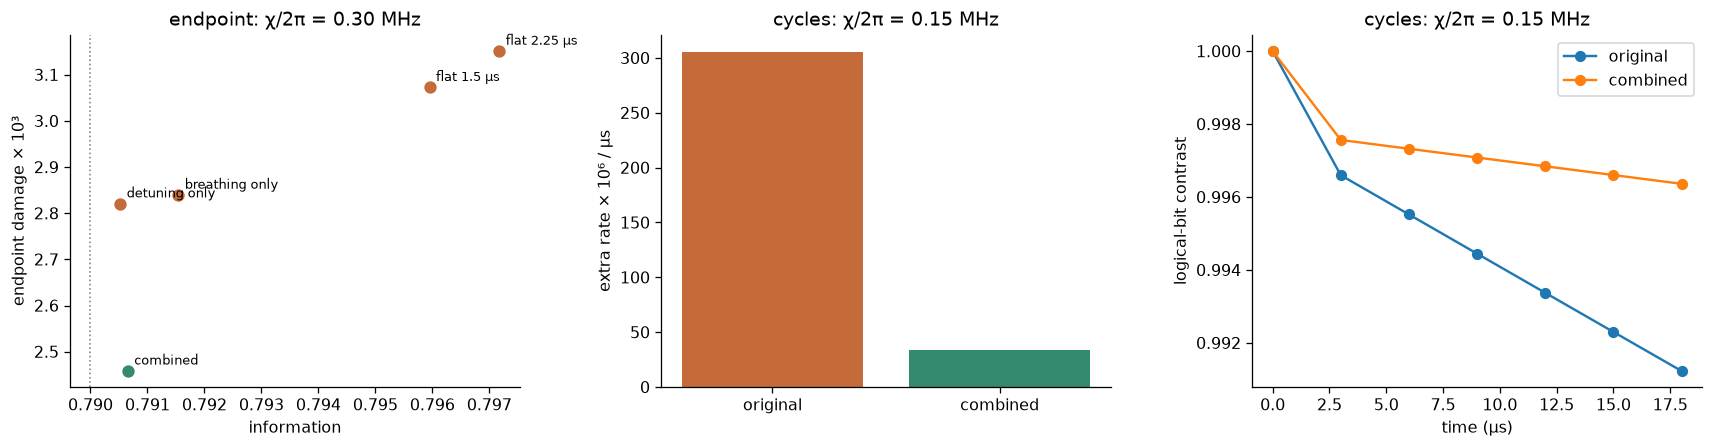

In [50]:
import json  # keep the exact control settings beside the result tables
from pathlib import Path  # saved artifacts make the section quick after restart
import numpy as np  # finite-time information and rate calculations
import pandas as pd  # compare all baselines in one table
import matplotlib.pyplot as plt  # make the trade-off visible
from IPython.display import Markdown, display  # show the conclusion beside the data

detuning_folder = Path("artifacts")  # all generated tables stay with the notebook
detuning_recompute = False  # true reruns the nonlinear master equations below
detuning_buffer_fraction = 0.45  # temporary increase relative to the idle buffer drive
detuning_factor = 1.0  # compensation in units of the tested chi alpha squared shift
detuning_memory_scale = 1.185  # recalibrated memory-drive scale at the strong-chi test
detuning_chi = 2*np.pi*0.30  # the stronger cross-kerr stress value in rad per microsecond


def detuning_nonlinear_run(na, nb, buffer_fraction, frequency_factor, drive_scale, sign):
    h, jumps, ops, a, b = two_mode(na, nb)  # begin with the challenge's two-mode model
    number_a, number_b = a.dag()@a, b.dag()@b  # number operators for the nonlinear corrections
    h = h + (2*np.pi*3.3)/2*(b.dag()@b.dag()@b@b)  # buffer self-kerr stress term
    h = h + detuning_chi*(number_a@number_b)  # memory-buffer cross-kerr stress term
    jumps = [*jumps, np.sqrt(2*np.pi*0.001)*number_a]  # memory dephasing stress channel
    spec = selected_specs["closed"]  # the same memory waveform used by the earlier readout
    memory_envelope = extension_waveform(spec)  # only its calibrated height changes

    def pulse_ramp(t):
        inside = (t >= 0) & (t < spec["duration"])  # only the extra ramp ends; the static detuning stays on
        return jnp.where(inside, jnp.sin(jnp.pi*t/spec["duration"])**2, 0.0)

    shifted = h - frequency_factor*detuning_chi*alpha**2*number_b  # static part of the prescribed compensation
    driven = shifted + dq.modulated(lambda t: drive_scale*memory_envelope(t), a+a.dag())
    driven = driven + dq.modulated(lambda t: -g2*alpha**2*buffer_fraction*pulse_ramp(t), b+b.dag())
    driven = driven + dq.modulated(lambda t: -frequency_factor*detuning_chi*alpha**2*buffer_fraction*pulse_ramp(t), number_b)
    times = np.linspace(0, 3, 601)  # same measurement horizon as the original pulse
    initial = dq.tensor(dq.coherent(na, sign*alpha), dq.fock(nb, 0))  # test both logical wells
    run = evolve(driven, jumps, initial, times, ops, (na, nb), rtol=2e-10, atol=2e-12)
    even = np.asarray(dq.to_numpy(cat_ket(na, alpha, 1))).ravel()  # original codeword basis
    odd = np.asarray(dq.to_numpy(cat_ket(na, alpha, -1))).ravel()
    wrong = (even-sign*odd)/np.sqrt(2)  # orthogonal wrong codeword for this input
    final_memory = run["rho"][-1]
    wrong_probability = np.einsum("i,ij,j->", wrong.conj(), final_memory, wrong).real
    code_probability = sum(np.einsum("i,ij,j->", cat.conj(), final_memory, cat).real for cat in [even, odd])
    return run, {"wrong": float(wrong_probability), "leakage": float(1-code_probability),
                 "memory tail max": float(run["e"][5].real.max()),
                 "buffer tail max": float(run["e"][6].real.max())}


def detuning_nonlinear_compare(na, nb, buffer_fraction, frequency_factor, drive_scale):
    plus, plus_result = detuning_nonlinear_run(na, nb, buffer_fraction, frequency_factor, drive_scale, +1)
    minus, minus_result = detuning_nonlinear_run(na, nb, buffer_fraction, frequency_factor, drive_scale, -1)
    difference = (plus["e"][3].real-minus["e"][3].real)/2  # common buffer motion cancels here
    damages = [result["wrong"]+result["leakage"] for result in [plus_result, minus_result]]
    return {"information": float(4*kb*np.trapezoid(difference**2, plus["t"])),
            "worst damage": float(max(damages)),
            "wrong plus": plus_result["wrong"], "wrong minus": minus_result["wrong"],
            "leakage plus": plus_result["leakage"], "leakage minus": minus_result["leakage"],
            "memory tail max": max(plus_result["memory tail max"], minus_result["memory tail max"]),
            "buffer tail max": max(plus_result["buffer tail max"], minus_result["buffer tail max"])}


if detuning_recompute:
    if any(name not in globals() for name in ["two_mode", "selected_specs", "extension_waveform", "evolve", "dq", "jnp"]):
        raise RuntimeError("run the earlier model cells before starting new nonlinear solves")
    for cutoff in [(32, 8), (36, 10)]:
        row = detuning_nonlinear_compare(*cutoff, detuning_buffer_fraction, detuning_factor, detuning_memory_scale)
        pd.DataFrame([row]).to_csv(detuning_folder / f"pump_detuning_recompute_{cutoff[0]}_{cutoff[1]}.csv", index=False)

detuning_ideal = pd.read_csv(detuning_folder / "pump_detuning_factorial_32_8.csv")  # chi/2pi = 0.15 MHz
detuning_strong = pd.read_csv(detuning_folder / "pump_detuning_chi0p30_recalibrated_32_8.csv")
detuning_strong_high = pd.read_csv(detuning_folder / "pump_detuning_chi0p30_recalibrated_36_10.csv")
detuning_flat = pd.read_csv(detuning_folder / "pump_detuning_chi0p30_flat_matched_32_8.csv")
detuning_only = pd.read_csv(detuning_folder / "pump_detuning_chi0p30_detuning_only_calibrated_32_8.csv").iloc[0]
detuning_ablation = pd.read_csv(detuning_folder / "pump_detuning_chi0p30_ablation_32_8.csv")
detuning_breathing_only = detuning_ablation.query("condition == 'breathing only at cap'").iloc[0]
detuning_cycles = pd.read_csv(detuning_folder / "pump_detuning_nonlinear_cycles_32_8.csv")
detuning_cycle_settings = json.loads((detuning_folder / "pump_detuning_cycle_settings.json").read_text())  # separate chi=0.15 MHz experiment
detuning_quadrature = pd.read_csv(detuning_folder / "pump_quadrature_training.csv")  # the failed sideband attempt

detuning_strong_table = pd.DataFrame([
    {"condition": "flat 1.5 μs", "information": detuning_flat.loc[0, "information"], "damage": detuning_flat.loc[0, "worst damage"]},
    {"condition": "flat 2.25 μs", "information": detuning_flat.loc[1, "information"], "damage": detuning_flat.loc[1, "worst damage"]},
    {"condition": "breathing only", "information": detuning_breathing_only["information"], "damage": detuning_breathing_only["worst damage"]},
    {"condition": "detuning only", "information": detuning_only["information"], "damage": detuning_only["worst damage"]},
    {"condition": "combined", "information": detuning_strong.loc[1, "information"], "damage": detuning_strong.loc[1, "worst damage"]},
])
detuning_strong_table["damage x 1e3"] = 1e3*detuning_strong_table["damage"]  # readable plotting scale
detuning_strong_table.to_csv(detuning_folder / "pump_detuning_strong_comparison.csv", index=False)
display(detuning_strong_table.round(7))  # fair strong-chi comparison
display(detuning_ideal.round(7))  # the same ablation in the milder stress model

detuning_active_rates = detuning_cycles.groupby("condition")["rate per us"].first()
detuning_original_excess_rate = float(detuning_active_rates["original"]-detuning_active_rates["original idle"])
detuning_combined_excess_rate = float(detuning_active_rates["combined"]-detuning_active_rates["combined idle"])
detuning_cycle_summary = pd.DataFrame([{"protocol": "original", "active rate per us": detuning_active_rates["original"],
                                       "idle rate per us": detuning_active_rates["original idle"],
                                       "extra readout rate per us": detuning_original_excess_rate},
                                      {"protocol": "combined", "active rate per us": detuning_active_rates["combined"],
                                       "idle rate per us": detuning_active_rates["combined idle"],
                                       "extra readout rate per us": detuning_combined_excess_rate}])
display(detuning_cycle_summary.round(8))  # compare each readout to its own idle control

fig, axes = plt.subplots(1, 3, figsize=(15, 4))  # one panel for each part of the claim
axes[0].scatter(detuning_strong_table["information"], detuning_strong_table["damage x 1e3"], color="#777777")
for _, row in detuning_strong_table.iterrows():
    color = "#348a71" if row["condition"] == "combined" else "#c46b39"
    axes[0].annotate(row["condition"], (row["information"], row["damage x 1e3"]), xytext=(4, 4), textcoords="offset points", fontsize=8)
    axes[0].scatter([row["information"]], [row["damage x 1e3"]], color=color, s=45)
axes[0].axvline(0.79, color="gray", ls=":", lw=1)  # common target information
axes[0].set(xlabel="information", ylabel="endpoint damage × 10³", title="endpoint: χ/2π = 0.30 MHz")
axes[1].bar(["original", "combined"], [1e6*detuning_original_excess_rate, 1e6*detuning_combined_excess_rate], color=["#c46b39", "#348a71"])
axes[1].set(ylabel="extra rate × 10⁶ / μs", title="cycles: χ/2π = 0.15 MHz")
axes[2].plot(detuning_cycles.query("condition == 'original'")["time"], detuning_cycles.query("condition == 'original'")["contrast"], "o-", label="original")
axes[2].plot(detuning_cycles.query("condition == 'combined'")["time"], detuning_cycles.query("condition == 'combined'")["contrast"], "o-", label="combined")
axes[2].set(xlabel="time (μs)", ylabel="logical-bit contrast", title="cycles: χ/2π = 0.15 MHz")
axes[2].legend()
fig.tight_layout()
fig.savefig(detuning_folder / "24_cross_kerr_aware_readout.png", dpi=170, bbox_inches="tight")
plt.show()
plt.close(fig)

the control has a real operating boundary

in the strong `chi/2pi = 0.30 MHz` stress model, the combined pulse reaches
`0.791` information at `32×8` and `0.791` again at `36×10`. the matched flat
baselines are around `0.796` and `0.797`, but have larger endpoint damage.
breathing alone and detuning alone each help; the combined pulse has the
smallest endpoint damage in this comparison.

the separate repeated-cycle test uses `chi/2pi = 0.15 MHz`, six 3 μs cycles,
no buffer reset, detuning factor 1.5, and memory-drive scale 1.190 (original:
1.166). these are different settings from the 0.30 MHz endpoint experiment.
subtracting each protocol's own idle rate gives `3.06e-4/us` extra decay for the original and
`3.36e-5/us` for the combined pulse, an 89% reduction. the total active rate
is still not zero, so this is a lower-damage readout rather than perfect
nondemolition measurement.

at stronger cross-kerr the detuning must be recalibrated. a factor of 1.5
lost the information target while factors near 0.5–1.0 recovered it. this
turns the idea into a calibration rule: estimate the buffer shift from the
cross-kerr, then choose the detuning and memory-drive scale together under
the peak limit. the orthogonal buffer quadrature did not improve damage.

In [51]:
detuning_best = detuning_strong_table.query("condition == 'combined'").iloc[0]
detuning_flat_best = detuning_strong_table.query("condition == 'flat 1.5 μs'").iloc[0]
detuning_rate_reduction = 100*(1-detuning_combined_excess_rate/detuning_original_excess_rate)
detuning_damage_reduction = 100*(1-detuning_best["damage"]/detuning_flat_best["damage"])
detuning_text = (
    f"at chi/2pi = 0.30 MHz, the cross-kerr-aware joint pulse reaches information {detuning_best['information']:.3f} at 32×8 and "
    f"{detuning_strong_high.loc[1, 'information']:.3f} at 36×10. its endpoint damage is "
    f"{detuning_damage_reduction:.1f}% below the matched 1.5 μs flat baseline. "
    f"in a separate six-cycle test at chi/2pi = 0.15 MHz, subtracting each idle control gives an "
    f"extra-rate reduction of {detuning_rate_reduction:.1f}%. "
    "the receiver and hardware limits remain separate tests; this is a model-backed control proposal, not a claim of experimental proof."
)
display(Markdown(detuning_text))  # keep the headline and its boundary together
(detuning_folder / "pump_detuning_findings.md").write_text(detuning_text + "\n")

at chi/2pi = 0.30 MHz, the cross-kerr-aware joint pulse reaches information 0.791 at 32×8 and 0.791 at 36×10. its endpoint damage is 20.0% below the matched 1.5 μs flat baseline. in a separate six-cycle test at chi/2pi = 0.15 MHz, subtracting each idle control gives an extra-rate reduction of 89.0%. the receiver and hardware limits remain separate tests; this is a model-backed control proposal, not a claim of experimental proof.

433

a small check of the phase recipe

this cell runs independently after a kernel restart. it checks the Hamiltonian,
Lindblad jumps, and measured quadrature, then evolves the chirped and effective
descriptions separately and compares their states after transforming frames.
the 4 x 3 matrices and mixed initial state are only an algebra/solver test.
the cat-performance numbers above still come from the larger cutoff studies.
the saved audit is in artifacts/pump_detuning_phase_audit.json.

In [52]:
import json  # save the frame check alongside the other audits
from pathlib import Path  # make this cell work after a fresh kernel restart
import numpy as np  # finite matrices are enough to test a frame transformation
from scipy.integrate import solve_ivp  # evolve both descriptions independently

frame_na, frame_nb = 4, 3  # small dimensions test identities, not cat convergence
frame_g2, frame_kb, frame_ka = 2*np.pi*np.array([0.763, 2.6, 0.0093])  # rad/us
frame_chi, frame_kerr, frame_phi = 2*np.pi*np.array([0.30, 3.3, 0.001])  # stress values
frame_alpha, frame_q, frame_f, frame_T = 2.1, 0.45, 1.0, 1.5  # actual chirp settings
frame_a = np.kron(np.diag(np.sqrt(np.arange(1, frame_na)), 1), np.eye(frame_nb))  # memory
frame_b = np.kron(np.eye(frame_na), np.diag(np.sqrt(np.arange(1, frame_nb)), 1))  # buffer
frame_n_a, frame_n_b = frame_a.conj().T@frame_a, frame_b.conj().T@frame_b  # number operators
frame_exchange = frame_a@frame_a@frame_b.conj().T  # two memory photons to one buffer photon
frame_nl = frame_chi*frame_n_a@frame_n_b + frame_kerr/2*frame_b.conj().T@frame_b.conj().T@frame_b@frame_b  # Kerr terms
frame_jumps = [np.sqrt(frame_kb)*frame_b, np.sqrt(frame_ka)*frame_a, np.sqrt(frame_phi)*frame_n_a]  # same baths


def frame_controls(t):
    ramp = np.sin(np.pi*t/frame_T)**2 if 0 <= t < frame_T else 0.0  # temporary part
    elapsed = np.clip(t, 0, frame_T)  # the integral keeps its accumulated phase after the ramp
    ramp_area = elapsed/2-frame_T*np.sin(2*np.pi*elapsed/frame_T)/(4*np.pi)  # exact integral
    correction = frame_f*frame_chi*frame_alpha**2*(1+frame_q*ramp)  # C(t) = -delta_b(t)
    phase = frame_f*frame_chi*frame_alpha**2*(t+frame_q*ramp_area)  # A(t), including the static shift
    buffer_drive = frame_g2*frame_alpha**2*(1+frame_q*ramp)  # same amplitude envelope
    return ramp, correction, phase, buffer_drive


def frame_hamiltonian(t, chirped):
    ramp, correction, phase, buffer_drive = frame_controls(t)  # both descriptions use these settings
    h = frame_nl + 0.25*frame_g2*ramp*(frame_a+frame_a.conj().T)  # any real memory pulse obeys the identity
    if chirped:
        h = h + frame_g2*(np.exp(-1j*phase)*frame_exchange + np.exp(1j*phase)*frame_exchange.conj().T)  # pump phase
        return h-buffer_drive*(np.exp(1j*phase)*frame_b+np.exp(-1j*phase)*frame_b.conj().T)  # buffer phase
    h = h + frame_g2*(frame_exchange+frame_exchange.conj().T)  # real exchange in the chirped frame
    return h-buffer_drive*(frame_b+frame_b.conj().T)-correction*frame_n_b  # simulated detuning has a minus sign


def frame_dissipator(jump, rho):
    product = jump.conj().T@jump  # anticommutator part of the Lindblad term
    return jump@rho@jump.conj().T-0.5*(product@rho+rho@product)  # D_L[rho]


frame_rng = np.random.default_rng(20261025)  # fixed state makes the audit reproducible
frame_ket = frame_rng.normal(size=frame_na*frame_nb)+1j*frame_rng.normal(size=frame_na*frame_nb)  # test coherences too
frame_ket = frame_ket/np.linalg.norm(frame_ket)  # normalize before mixing
frame_initial = 0.8*np.outer(frame_ket, frame_ket.conj())+0.2*np.eye(frame_na*frame_nb)/(frame_na*frame_nb)  # positive state
frame_times = np.unique(np.r_[np.linspace(0, 3, 61), 0.17, 1.49, 1.51, 2.2])  # sample ramp and ringdown
frame_h_errors, frame_d_errors, frame_lo_errors, frame_phase_errors = [], [], [], []  # keep separate diagnostics
for t in frame_times:
    _, correction, phase, _ = frame_controls(t)  # all phases are relative to their nominal carriers
    u = np.diag(np.exp(-1j*phase*np.diag(frame_n_b)))  # U = exp(-i A n_b)
    transformed_h = u.conj().T@frame_hamiltonian(t, True)@u-correction*frame_n_b  # include -i Udag dot U
    frame_h_errors.append(np.linalg.norm(transformed_h-frame_hamiltonian(t, False))/max(1, np.linalg.norm(transformed_h)))  # relative
    for jump in frame_jumps:
        rotated_jump = u.conj().T@jump@u  # the buffer jump acquires only a scalar phase
        frame_d_errors.append(np.linalg.norm(frame_dissipator(rotated_jump, frame_initial)-frame_dissipator(jump, frame_initial)))  # bath invariance
    frame_lo_errors.append(np.linalg.norm(u.conj().T@(np.exp(1j*phase)*frame_b)@u-frame_b))  # same measured quadrature
    step = 1e-5  # finite difference independently checks the analytic phase integral
    phase_derivative = (frame_controls(t+step)[2]-frame_controls(t-step)[2])/(2*step)  # dA/dt
    frame_phase_errors.append(abs(phase_derivative-correction))  # should equal C(t), including after T


def frame_rhs(t, vector, chirped):
    rho = vector.reshape(frame_initial.shape)  # density matrix in the chosen frame
    h = frame_hamiltonian(t, chirped)  # distinct Hamiltonians, integrated separately
    rate = -1j*(h@rho-rho@h)  # unitary part
    for jump in frame_jumps:
        rate = rate+frame_dissipator(jump, rho)  # same unconditional baths
    return rate.ravel()  # solve_ivp expects a vector


frame_solutions = []  # two independent adaptive integrations
for chirped in [False, True]:
    solution = solve_ivp(lambda t, y: frame_rhs(t, y, chirped), (0, 3), frame_initial.ravel(),
                         t_eval=frame_times, method="DOP853", rtol=2e-10, atol=2e-12)  # tight enough for a sign test
    assert solution.success, solution.message  # never hide an integration failure
    frame_solutions.append(solution.y.T.reshape((-1, *frame_initial.shape)))  # back to density matrices

frame_state_error, frame_signal_error, frame_fixed_lo_difference = 0.0, 0.0, 0.0  # maximum absolute discrepancies
for t, effective_rho, chirped_rho in zip(frame_times, *frame_solutions):
    phase = frame_controls(t)[2]  # receiver follows the same phase accumulator
    u = np.diag(np.exp(-1j*phase*np.diag(frame_n_b)))  # no memory rotation is needed
    frame_state_error = max(frame_state_error, float(np.linalg.norm(effective_rho-u.conj().T@chirped_rho@u)))  # full state
    effective_b, chirped_b = np.trace(frame_b@effective_rho), np.trace(frame_b@chirped_rho)  # complex signals
    frame_signal_error = max(frame_signal_error, float(abs(effective_b-np.exp(1j*phase)*chirped_b)))  # tracked receiver
    frame_fixed_lo_difference = max(frame_fixed_lo_difference, float(abs(effective_b.real-chirped_b.real)))  # untracked receiver

frame_summary = {
    "scope": "small-matrix phase identity and independent Lindblad integration; not a physical cutoff study",
    "cutoff": [frame_na, frame_nb], "time unit": "microsecond",
    "max relative Hamiltonian error": float(max(frame_h_errors)),
    "max dissipator error": float(max(frame_d_errors)),
    "max receiver operator error": float(max(frame_lo_errors)),
    "max phase derivative error per us": float(max(frame_phase_errors)),
    "max density matrix Frobenius error": frame_state_error,
    "max tracked buffer signal error": frame_signal_error,
    "max fixed LO real signal difference": frame_fixed_lo_difference,
    "idle buffer shift MHz": float(frame_f*frame_chi*frame_alpha**2/(2*np.pi)),
    "peak buffer shift MHz": float(frame_f*frame_chi*frame_alpha**2*(1+frame_q)/(2*np.pi)),
}  # the scalar diagnostics are enough to reproduce the claim
assert max(frame_h_errors) < 1e-12 and max(frame_d_errors) < 1e-12  # Hamiltonian and baths
assert max(frame_lo_errors) < 1e-12 and max(frame_phase_errors) < 1e-7  # receiver and phase derivative
assert frame_state_error < 2e-8 and frame_signal_error < 2e-8  # both independently evolved descriptions agree
Path("artifacts").mkdir(exist_ok=True)  # allow this cell to run independently
Path("artifacts/pump_detuning_phase_audit.json").write_text(json.dumps(frame_summary, indent=2)+"\n")  # generated numerical audit
print(json.dumps(frame_summary, indent=2))  # keep the evidence visible in the notebook

{
  "scope": "small-matrix phase identity and independent Lindblad integration; not a physical cutoff study",
  "cutoff": [
    4,
    3
  ],
  "time unit": "microsecond",
  "max relative Hamiltonian error": 1.1452003110340984e-14,
  "max dissipator error": 1.2200847424558842e-13,
  "max receiver operator error": 4.063416270128073e-14,
  "max phase derivative error per us": 6.135181251920585e-10,
  "max density matrix Frobenius error": 4.4753200908567565e-09,
  "max tracked buffer signal error": 6.687864411676254e-10,
  "max fixed LO real signal difference": 0.665463491556334,
  "idle buffer shift MHz": 1.323,
  "peak buffer shift MHz": 1.91835
}


final checks requested by the feedback

the earlier damage result did not establish either final-pulse assignment
accuracy or preservation of idle bit protection. this audit tests them
separately in the same strong nonlinear model: chi/2pi = 0.30 MHz, buffer
Kerr/2pi = 3.3 MHz, memory dephasing/2pi = 1 kHz, and detector efficiency one.

the plan in artifacts/final_validation_plan.json fixes the controls, sample
counts, seeds, horizons, fit windows, and thresholds before these new outcomes.
the operational accuracy target is a 95% upper error bound no greater than 5%
after seven 3 μs cycles. the operational preservation limit is a total active
contrast-decay rate no more than 1.10 times the corresponding idle rate.
these are our audit thresholds, not organizer-specified rules.

the idle comparison retains the joint pulse's buffer controls and removes only
its memory readout drive. we also report the original unmodified idle rate.
a reduction in active-minus-idle decay is not a preservation test.

the matched filter uses both deterministic buffer means. with
$\mu_\pm(t)=2\sqrt{\kappa_b}\operatorname{Re}\langle b\rangle_\pm(t)$,

$$
S=\frac{\int(\mu_+-\mu_-)
[dY-\frac12(\mu_++\mu_-)\,dt]}
{\sqrt{\int(\mu_+-\mu_-)^2\,dt}}.
$$

the sign of S assigns the initial bit. the deterministic midpoint removes any
common buffer offset; no noisy labels choose the template or threshold.
3 μs is a secondary result and 21 μs is the fixed primary horizon.
no state is reset between cycles. the homodyne reference is the chirped one
derived above.

we unravel all three channels to keep trajectory states small, then give only
the buffer record to the receiver. the unobserved records are discarded; they
are never used for feedback or classification. this gives the buffer-record
marginal, not a buffer-only conditional state. see the
[Dynamiqs stochastic-solver documentation](https://www.dynamiqs.org/stable/python_api/integrators/dsmesolve.html).

the original fast ket-normalized scheme failed an ensemble check in this
nonlinear model: it produced about 8.05 photons where the master equation gives
4.406. its apparent assignment errors are retained as rejected numerical
results, not used for physical accuracy claims. the corrected runs normalize the
Kraus map as well as the ket, and must pass an ensemble photon-number check.
artifacts/final_validation_numerics.json records this solver revision; controls,
seeds, sample counts, horizons, and claim thresholds are unchanged. computational
batches are larger to amortize the state-independent matrix normalization.

the normalized Rouchon map is precomputed at Hamiltonian midpoint bins of
5 ns for speed. the half-step check halves both the stochastic step and this
Hamiltonian bin. the code checks operator actions against the Dynamiqs model,
checks Kraus-map completeness, and compares a full update with its dense formula.
this is a numerical implementation change, not a change to the physical model.

main receiver tests use 512 records per bit at 24 x 6. independent half-step and
larger-cutoff checks use 128 records per bit. error intervals, paired differences,
and a conservative 3-percentage-point equivalence test are shown. an unresolved
difference remains unresolved.

the protection fits use 32 x 8, repeat the joint and idle cases at 36 x 10,
tighten solver tolerances, and vary the fitting window. cutoff/tolerance/window
changes form a numerical sensitivity indicator, not a statistical confidence
interval. the small-cat stationary Gamma_X from Task 2.1 and this repeated-cycle
contrast rate remain different quantities.

the following cells are independent of the earlier setup. leave the final
recompute switch false to inspect saved evidence; true regenerates this audit
and reuses setting-keyed checkpoints. the entire calculation, including the
repeated-cycle tests, is now included here.

In [53]:
import os  # put the numerical caches in the project
from pathlib import Path  # the audit is self-contained after a kernel restart
os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd()/".cache"/"matplotlib"))
os.environ.setdefault("XDG_CACHE_HOME", str(Path.cwd()/".cache"))
import json, hashlib, time  # record settings, cache identity, and solve times
import importlib.metadata as metadata  # keep the actual numerical environment
import numpy as np  # analyze expectations and noisy records
import pandas as pd  # save the audit tables
from scipy.stats import norm  # normal quantiles for Wilson intervals
import dynamiqs as dq  # integrate the requested two-mode Lindblad model
import jax  # independent, reproducible trajectory keys
import jax.numpy as jnp  # time-dependent Hamiltonian envelopes

dq.set_precision("double")  # rare decay rates need double precision
dq.set_progress_meter(False)  # print one line per completed batch instead
fv_folder = Path("artifacts")  # inputs and computed evidence travel with the notebook
fv_plan = json.loads((fv_folder/"final_validation_plan.json").read_text())
fv_numerics = json.loads((fv_folder/"final_validation_numerics.json").read_text())  # reject the unstable fast variant
fv_plan_hash = hashlib.sha256(json.dumps(fv_plan, sort_keys=True).encode()).hexdigest()
fv_versions = {name: metadata.version(name) for name in ["dynamiqs", "jax", "numpy", "scipy", "pandas"]}
fv_g, fv_kb, fv_ka, fv_chi, fv_kerr, fv_phi = 2*np.pi*np.array([fv_plan[key] for key in
    ["g2_over_2pi_MHz", "kb_over_2pi_MHz", "ka_over_2pi_MHz", "chi_over_2pi_MHz", "buffer_Kerr_over_2pi_MHz", "memory_dephasing_over_2pi_MHz"]])
fv_alpha, fv_period, fv_duration = fv_plan["alpha"], fv_plan["period_us"], fv_plan["drive_duration_us"]
fv_times = np.linspace(0, fv_plan["primary_horizon_us"], round(fv_plan["primary_horizon_us"]/fv_plan["record_bin_us"])+1)


def fv_model(label, na, nb):
    spec = fv_plan["protocols"][label]  # all candidates were frozen before this audit
    a, b = dq.destroy(na, nb)  # full memory-buffer tensor operators
    n_a, n_b = a.dag()@a, b.dag()@b
    h0 = fv_g*(a@a@b.dag()+a.dag()@a.dag()@b)-fv_g*fv_alpha**2*(b+b.dag())
    h0 = h0+fv_chi*(n_a@n_b)+fv_kerr/2*(b.dag()@b.dag()@b@b)
    h0 = h0-spec["detuning_factor"]*fv_chi*fv_alpha**2*n_b  # static correction remains between cycles
    coefficients = jnp.asarray(fv_plan["closed_coefficients"])

    def ramp(t):
        u = jnp.mod(t, fv_period)  # no state reset at a cycle boundary
        return jnp.where(u < fv_duration, jnp.sin(jnp.pi*u/fv_duration)**2, 0.0)

    def memory(t):
        u = jnp.mod(t, fv_period)
        if spec["kind"] == "flat":
            edge = jnp.minimum(jnp.minimum(u, fv_duration-u)/0.02, 1.0)
            value = spec["memory_peak_over_g2"]*fv_g*jnp.sin(jnp.pi*edge/2)**2
        else:
            value = spec["memory_scale"]*fv_plan["closed_peak"]*ramp(t)*jnp.sum(
                coefficients*jnp.cos(jnp.arange(len(coefficients))*jnp.pi*u/fv_duration))
        return jnp.where(u < fv_duration, value, 0.0)

    h = h0+dq.modulated(memory, a+a.dag())
    h = h+dq.modulated(lambda t: -fv_g*fv_alpha**2*spec["buffer_fraction"]*ramp(t), b+b.dag())
    h = h+dq.modulated(lambda t: -spec["detuning_factor"]*fv_chi*fv_alpha**2*spec["buffer_fraction"]*ramp(t), n_b)
    jumps = [np.sqrt(fv_kb)*b, np.sqrt(fv_ka)*a, np.sqrt(fv_phi)*n_a]  # only channel zero is supplied to the classifier
    even = dq.unit(dq.coherent(na, fv_alpha)+dq.coherent(na, -fv_alpha))
    odd = dq.unit(dq.coherent(na, fv_alpha)-dq.coherent(na, -fv_alpha))
    z_plus, z_minus = (even+odd)/np.sqrt(2), (even-odd)/np.sqrt(2)
    logical = dq.tensor(dq.todm(z_plus)-dq.todm(z_minus), dq.eye(nb))
    code = dq.tensor(dq.todm(even)+dq.todm(odd), dq.eye(nb))
    tail_a = dq.tensor(dq.fock_dm(na, na-2)+dq.fock_dm(na, na-1), dq.eye(nb))
    tail_b = dq.tensor(dq.eye(na), dq.fock_dm(nb, nb-1))
    return h, jumps, [b, logical, n_a, tail_a, tail_b, code]


def fv_cache_path(settings):
    settings = {"engine": "frozen-final-audit-v1", "plan": fv_plan_hash, "versions": fv_versions, **settings}
    digest = hashlib.sha256(json.dumps(settings, sort_keys=True).encode()).hexdigest()
    folder = fv_folder/"checkpoints"
    folder.mkdir(exist_ok=True)
    return folder/f"final-audit-{digest}.npz"


def fv_deterministic(label, na, nb, sign, tight=False):
    rtol = fv_plan["tighter_rtol" if tight else "primary_rtol"]
    atol = fv_plan["tighter_atol" if tight else "primary_atol"]
    path = fv_cache_path({"kind": "density", "protocol": label, "cutoff": [na, nb], "sign": sign, "rtol": rtol, "atol": atol})
    if path.exists():
        with np.load(path, allow_pickle=False) as data:
            return {key: data[key] for key in data.files}
    h, jumps, ops = fv_model(label, na, nb)
    initial = dq.tensor(dq.coherent(na, sign*fv_alpha), dq.fock(nb, 0))
    started = time.monotonic()
    result = dq.mesolve(h, jumps, initial, jnp.asarray(fv_times), exp_ops=ops,
        method=dq.method.Tsit5(rtol=rtol, atol=atol, max_steps=2_000_000), save_states=False)
    e = np.asarray(result.expects)
    rho = np.asarray(dq.to_numpy(result.final_state)).reshape(na*nb, na*nb)
    output = {"e": e, "trace_error": np.asarray(abs(np.trace(rho)-1)),
              "min_eigenvalue": np.asarray(np.linalg.eigvalsh((rho+rho.conj().T)/2).min()),
              "hermiticity_error": np.asarray(np.max(abs(rho-rho.conj().T)))}
    assert np.isfinite(e).all() and float(output["trace_error"]) < 1e-7
    np.savez_compressed(path, **output)  # every setting is included in the cache identity
    print(f"density: {label}, {na}x{nb}, bit {sign:+}, tight={tight}, {time.monotonic()-started:.1f}s", flush=True)
    return output


def fv_fit_rate(contrast, start):
    boundaries = np.arange(fv_plan["cycles"]+1)*round(fv_period/fv_plan["record_bin_us"])
    x, y = fv_times[boundaries][start:], np.log(contrast[boundaries][start:])
    slope, intercept = np.polyfit(x, y, 1)
    residual = y-(slope*x+intercept)
    slope_se = np.sqrt(np.sum(residual**2)/(len(x)-2)/np.sum((x-x.mean())**2))
    return float(-slope), float(slope_se), float(np.max(abs(residual)))


def fv_run_protection():
    rows = []
    configurations = [(label, *fv_plan["protection_primary_cutoff"], False) for label in fv_plan["protocols"]]
    configurations += [(label, *fv_plan["protection_larger_cutoff"], False) for label in ["joint", "joint idle"]]
    configurations += [(label, *fv_plan["protection_primary_cutoff"], True) for label in ["joint", "joint idle"]]
    for label, na, nb, tight in configurations:
        runs = [fv_deterministic(label, na, nb, sign, tight) for sign in [1, -1]]
        contrast = (runs[0]["e"][1].real-runs[1]["e"][1].real)/2  # cancels any common offset
        fits = [fv_fit_rate(contrast, start) for start in fv_plan["fit_start_cycles"]]
        plus, minus = runs[0]["e"][0], runs[1]["e"][0]
        first = fv_times <= fv_period+1e-9
        information = fv_kb*np.trapezoid((plus.real-minus.real)**2, fv_times)
        damage = [1-0.5*(run["e"][5].real+sign*run["e"][1].real) for sign, run in zip([1, -1], runs)]
        row = {"protocol": label, "na": na, "nb": nb, "tight": tight,
            "rate": fits[0][0], "fit standard error": fits[0][1], "fit max log residual": fits[0][2],
            "window change": max(abs(fit[0]-fits[0][0]) for fit in fits),
            "first cycle information": float(fv_kb*np.trapezoid((plus.real[first]-minus.real[first])**2, fv_times[first])),
            "total information": float(information), "first cycle worst damage": float(max(d[round(fv_period/fv_plan["record_bin_us"])] for d in damage)),
            "final worst damage": float(max(d[-1] for d in damage)),
            "max memory tail": float(max(run["e"][3].real.max() for run in runs)),
            "max buffer tail": float(max(run["e"][4].real.max() for run in runs)),
            "trace error": float(max(run["trace_error"] for run in runs)),
            "min eigenvalue": float(min(run["min_eigenvalue"] for run in runs))}
        rows.append(row)
        pd.DataFrame(rows).to_csv(fv_folder/"final_validation_protection.csv", index=False)  # keep completed cases if interrupted
        print("protection:", json.dumps(row), flush=True)
    return pd.DataFrame(rows)


def fv_templates(label, na, nb):
    plus, minus = [fv_deterministic(label, na, nb, sign)["e"][0].real for sign in [1, -1]]
    mu_plus, mu_minus = 2*np.sqrt(fv_kb)*plus, 2*np.sqrt(fv_kb)*minus
    weight = ((mu_plus-mu_minus)[:-1]+(mu_plus-mu_minus)[1:])/2
    midpoint = ((mu_plus+mu_minus)[:-1]+(mu_plus+mu_minus)[1:])/4
    return weight, midpoint  # no noisy labels are used to train or tune this receiver


def fv_record_batch(label, condition, sign, offset, count):
    settings = fv_plan["sampling"][condition]
    na, nb = settings["cutoff"]
    dt = settings["dt_us"]
    weight, midpoint = fv_templates(label, na, nb)
    path = fv_cache_path({"kind": "records", "protocol": label, "condition": condition, "sign": sign, "offset": offset, "count": count, "kraus_normalized": True, "implementation": "precomputed-midpoint-v1"})
    if path.exists():
        with np.load(path, allow_pickle=False) as data:
            return {key: data[key] for key in data.files}
    started = time.monotonic()
    record, final_kets = fv_precomputed_records(label, na, nb, sign, offset, count, settings)  # normalized Rouchon map
    widths = np.diff(fv_times)
    projections = []
    for horizon in [fv_plan["secondary_horizon_us"], fv_plan["primary_horizon_us"]]:
        mask = fv_times[1:] <= horizon+1e-9
        normalization = np.sqrt(np.sum(weight[mask]**2*widths[mask]))
        projections.append(((record[:, mask]-midpoint[mask])@(weight[mask]*widths[mask]))/normalization)
    n_diagonal = np.repeat(np.arange(na), nb)
    final_n = np.sum(abs(final_kets)**2*n_diagonal, axis=1).real
    output = {"scores": np.stack(projections, axis=1), "final_n": final_n,
              "record_sha256": np.asarray(hashlib.sha256(record.tobytes()).hexdigest())}
    assert np.isfinite(output["scores"]).all() and np.isfinite(final_n).all()
    np.savez_compressed(path, **output)  # retain frozen projections and raw-record hashes
    print(f"records: {label}, {condition}, bit {sign:+}, {offset+count}/{settings['shots_per_bit']}, {time.monotonic()-started:.1f}s", flush=True)
    return output


def fv_wilson(errors, count, z=1.959963984540054):
    p = errors/count
    center = (p+z*z/(2*count))/(1+z*z/count)
    half = z*np.sqrt(p*(1-p)/count+z*z/(4*count*count))/(1+z*z/count)
    return float(center-half), float(center+half)


def fv_run_receivers(conditions=None):
    rows = []
    for condition in (conditions or list(fv_plan["sampling"])):
        settings = fv_plan["sampling"][condition]
        for label in ["joint", "flat"]:
            all_scores, signs, final_numbers, hashes = [], [], [], []
            for sign in [1, -1]:
                for offset in range(0, settings["shots_per_bit"], fv_numerics["execution_batch_size"]):
                    count = min(fv_numerics["execution_batch_size"], settings["shots_per_bit"]-offset)
                    batch = fv_record_batch(label, condition, sign, offset, count)
                    all_scores.append(batch["scores"])
                    signs.extend([sign]*count)
                    final_numbers.extend(batch["final_n"])
                    hashes.append(str(batch["record_sha256"]))
            scores, signs = np.concatenate(all_scores), np.asarray(signs)
            filename = "final_validation_scores_"+condition.replace(" ", "_")+"_"+label+".npz"
            np.savez_compressed(fv_folder/filename, scores=scores, signs=signs, final_n=final_numbers, raw_record_hashes=hashes, plan_hash=fv_plan_hash)
            for col, horizon in enumerate([fv_plan["secondary_horizon_us"], fv_plan["primary_horizon_us"]]):
                errors = signs*scores[:, col] <= 0
                low, high = fv_wilson(int(errors.sum()), len(errors))
                expected_n = np.mean([fv_deterministic(label, *settings["cutoff"], s)["e"][2, -1].real for s in [1, -1]])
                n_se = float(np.std(final_numbers, ddof=1)/np.sqrt(len(final_numbers)))
                n_tolerance = max(fv_numerics["ensemble_photon_number_absolute_tolerance"], fv_numerics["ensemble_photon_number_standard_errors"]*n_se)
                row = {"protocol": label, "condition": condition, "horizon us": horizon, "shots": len(errors),
                       "errors": int(errors.sum()), "assignment error": float(errors.mean()), "95% low": low, "95% high": high,
                       "plus errors": int(errors[signs == 1].sum()), "minus errors": int(errors[signs == -1].sum()),
                       "accuracy threshold met": bool(high <= fv_plan["audit_thresholds"]["assignment_error_upper_95"]),
                       "expected final n": float(expected_n), "ensemble difference": float(np.mean(final_numbers)-expected_n),
                       "ensemble check passed": bool(abs(np.mean(final_numbers)-expected_n) <= n_tolerance),
                       "mean final n": float(np.mean(final_numbers)), "final n standard error": float(np.std(final_numbers, ddof=1)/np.sqrt(len(final_numbers)))}
                rows.append(row)
            pd.DataFrame(rows).to_csv(fv_folder/"final_validation_receiver.csv", index=False)
            print("receiver:", json.dumps(rows[-1]), flush=True)
    return pd.DataFrame(rows)


import scipy.linalg as fv_la  # precompute the state-independent Kraus normalization
fv_sampler_cache = {}  # reuse the compiled sampler for the two stored-bit signs


def fv_precomputed_bank(label, na, nb, dt, hstep):
    path = fv_cache_path({"kind": "Kraus bank", "protocol": label, "cutoff": [na, nb], "dt": dt, "hstep": hstep})
    if path.exists():
        with np.load(path, allow_pickle=False) as saved:
            return saved["normalizers"], saved["controls"]
    h, jumps, _ = fv_model(label, na, nb)
    base = np.asarray(dq.to_numpy(h(0.0)))
    a, b = dq.destroy(na, nb)
    memory = np.asarray(dq.to_numpy(a+a.dag()))
    buffer = np.asarray(dq.to_numpy(b+b.dag()))
    number_b = np.asarray(dq.to_numpy(b.dag()@b))
    loss = sum(np.asarray(dq.to_numpy(jump.dag()@jump)) for jump in jumps)
    spec = fv_plan["protocols"][label]
    times = (np.arange(round(fv_period/hstep))+0.5)*hstep
    u = np.mod(times, fv_period)
    ramp = np.where(u < fv_duration, np.sin(np.pi*u/fv_duration)**2, 0.0)
    if spec["kind"] == "flat":
        edge = np.minimum(np.minimum(u, fv_duration-u)/0.02, 1.0)
        z = np.where(u < fv_duration, spec["memory_peak_over_g2"]*fv_g*np.sin(np.pi*edge/2)**2, 0)
    else:
        z = spec["memory_scale"]*fv_plan["closed_peak"]*ramp*np.sum(
            np.asarray(fv_plan["closed_coefficients"])[None, :]*np.cos(np.pi*u[:, None]/fv_duration*np.arange(len(fv_plan["closed_coefficients"]))), axis=1)
    controls = np.stack([z, ramp], axis=1)
    eye = np.eye(na*nb)
    normalizers = np.empty((len(times), na*nb, na*nb), dtype=complex)
    for i, (t, (z_i, r_i)) in enumerate(zip(times, controls)):
        dense_h = base+z_i*memory-fv_g*fv_alpha**2*spec["buffer_fraction"]*r_i*buffer
        dense_h = dense_h-spec["detuning_factor"]*fv_chi*fv_alpha**2*spec["buffer_fraction"]*r_i*number_b
        if i in [0, len(times)//4, len(times)//2]:
            assert np.max(abs(dense_h-np.asarray(dq.to_numpy(h(t))))) < 1e-10  # controls match the continuous model
        m0 = eye-(1j*dense_h+0.5*loss)*dt
        s = m0.conj().T@m0+loss*dt
        chol = fv_la.cholesky(s, lower=True)
        normalizers[i] = fv_la.solve_triangular(chol.conj().T, eye, lower=False)
        if i in [0, len(times)//4, len(times)//2]:
            assert np.max(abs(normalizers[i].conj().T@s@normalizers[i]-eye)) < 1e-12  # completeness, before state normalization
    np.savez_compressed(path, normalizers=normalizers, controls=controls)
    print(f"precomputed Kraus bank: {label}, {na}x{nb}, {len(times)} Hamiltonian bins", flush=True)
    return normalizers, controls


def fv_precomputed_records(label, na, nb, sign, offset, count, settings, check_only=False):
    dt = settings["dt_us"]
    hstep = fv_plan["record_bin_us"]*(0.5 if settings == fv_plan["sampling"]["half step"] else 1.0)
    nsub = round(hstep/dt)
    assert abs(nsub*dt-hstep) < 1e-12
    bank, controls = fv_precomputed_bank(label, na, nb, dt, hstep)
    bank, controls = jnp.asarray(bank), jnp.asarray(controls)
    m, n = jnp.arange(na)[:, None], jnp.arange(nb)[None, :]
    root_m, root_n = jnp.sqrt(jnp.arange(1, na)), jnp.sqrt(jnp.arange(1, nb))
    pair = jnp.sqrt(jnp.arange(1, na-1)*jnp.arange(2, na))
    loss = fv_ka*m+fv_kb*n+fv_phi*m*m
    spec = fv_plan["protocols"][label]

    def lower(psi):
        a = jnp.pad(psi[:, 1:, :]*root_m[None, :, None], ((0, 0), (0, 1), (0, 0)))
        b = jnp.pad(psi[:, :, 1:]*root_n[None, None, :], ((0, 0), (0, 0), (0, 1)))
        return a, b

    def h_action(psi, z, ramp):
        a, b = lower(psi)
        ad = jnp.pad(psi[:, :-1, :]*root_m[None, :, None], ((0, 0), (1, 0), (0, 0)))
        bd = jnp.pad(psi[:, :, :-1]*root_n[None, None, :], ((0, 0), (0, 0), (1, 0)))
        forward = jnp.pad(psi[:, 2:, :-1]*pair[None, :, None]*root_n[None, None, :], ((0, 0), (0, 2), (1, 0)))
        backward = jnp.pad(psi[:, :-2, 1:]*pair[None, :, None]*root_n[None, None, :], ((0, 0), (2, 0), (0, 1)))
        diagonal = fv_chi*m*n+fv_kerr*n*(n-1)/2-spec["detuning_factor"]*fv_chi*fv_alpha**2*(1+spec["buffer_fraction"]*ramp)*n
        value = diagonal[None, :, :]*psi+fv_g*(forward+backward)+z*(a+ad)
        value = value-fv_g*fv_alpha**2*(1+spec["buffer_fraction"]*ramp)*(b+bd)
        return value

    initial = np.asarray(dq.to_numpy(dq.tensor(dq.coherent(na, sign*fv_alpha), dq.fock(nb, 0)))).reshape(na, nb)
    test = np.arange(na*nb).reshape(1, na, nb)*(1+0.2j)
    t_test = hstep/2
    h_full, step_jumps, _ = fv_model(label, na, nb)
    dense_action = np.asarray(dq.to_numpy(h_full(t_test)))@test.ravel()
    assert np.max(abs(np.asarray(h_action(jnp.asarray(test), *controls[0])).ravel()-dense_action)) < 1e-9  # check sparse actions
    test_psi = jnp.asarray(test/np.linalg.norm(test))
    test_x = (test_psi.reshape(1, -1)@bank[0].T).reshape(1, na, nb)
    a_x, b_x = lower(test_x)
    dy_test = np.array([0.01, -0.008, 0.02])  # arbitrary outcomes check the three-channel ordering
    sparse_step = test_x-dt*(1j*h_action(test_x, *controls[0])+0.5*loss[None, :, :]*test_x)
    sparse_step += np.sqrt(fv_kb)*b_x*dy_test[0]+np.sqrt(fv_ka)*a_x*dy_test[1]+np.sqrt(fv_phi)*m[None, :, :]*test_x*dy_test[2]
    dense_jumps = [np.asarray(dq.to_numpy(jump)) for jump in step_jumps]
    dense_loss = sum(jump.conj().T@jump for jump in dense_jumps)
    dense_map = np.eye(na*nb)-(1j*np.asarray(dq.to_numpy(h_full(t_test)))+0.5*dense_loss)*dt
    dense_map += sum(jump*dy for jump, dy in zip(dense_jumps, dy_test))
    dense_step = dense_map@np.asarray(test_x).ravel()
    assert np.max(abs(np.asarray(sparse_step).ravel()-dense_step)) < 1e-11  # agrees with the native normalized Rouchon update
    m0_check = np.eye(na*nb)-(1j*np.asarray(dq.to_numpy(h_full(t_test)))+0.5*dense_loss)*dt
    completeness = np.asarray(bank[0]).conj().T@(m0_check.conj().T@m0_check+dense_loss*dt)@np.asarray(bank[0])
    assert np.max(abs(completeness-np.eye(na*nb))) < 1e-12  # also validate a loaded normalization bank
    if check_only:
        return None, None  # permits an independent one-step check without regenerating trajectories
    keys = jax.vmap(lambda i: jax.random.fold_in(jax.random.fold_in(jax.random.key(settings["seed"]), int(sign < 0)), i))(
        jnp.arange(offset, offset+count, dtype=jnp.uint32))

    @jax.jit
    def integrate(psi0, keys, bank, controls):
        def block(psi, block_index):
            phase_index = block_index % bank.shape[0]
            normalizer = bank[phase_index]
            z, ramp = controls[phase_index]

            def step(i, carry):
                psi, record = carry
                a, b = lower(psi)
                means = jnp.stack([2*jnp.real(jnp.sum(psi.conj()*np.sqrt(fv_kb)*b, axis=(1, 2))),
                    2*jnp.real(jnp.sum(psi.conj()*np.sqrt(fv_ka)*a, axis=(1, 2))),
                    2*jnp.real(jnp.sum(psi.conj()*np.sqrt(fv_phi)*m[None, :, :]*psi, axis=(1, 2)))], axis=1)
                noise_keys = jax.vmap(lambda k: jax.random.fold_in(k, block_index*nsub+i))(keys)
                noise = jax.vmap(lambda k: jax.random.normal(k, (3,), dtype=jnp.float64))(noise_keys)*np.sqrt(dt)
                dy = means*dt+noise
                x = (psi.reshape(count, -1)@normalizer.T).reshape(count, na, nb)
                a_x, b_x = lower(x)
                updated = x-dt*(1j*h_action(x, z, ramp)+0.5*loss[None, :, :]*x)
                updated += np.sqrt(fv_kb)*b_x*dy[:, 0, None, None]+np.sqrt(fv_ka)*a_x*dy[:, 1, None, None]
                updated += np.sqrt(fv_phi)*m[None, :, :]*x*dy[:, 2, None, None]
                updated /= jnp.sqrt(jnp.sum(abs(updated)**2, axis=(1, 2)))[:, None, None]
                return updated, record+dy[:, 0]

            psi, record = jax.lax.fori_loop(0, nsub, step, (psi, jnp.zeros(count)))
            return psi, record
        return jax.lax.scan(block, psi0, jnp.arange(round(fv_plan["primary_horizon_us"]/hstep)))

    cache_key = (label, na, nb, dt, hstep, count)
    if cache_key not in fv_sampler_cache:
        fv_sampler_cache[cache_key] = integrate
    final, records = fv_sampler_cache[cache_key](jnp.broadcast_to(jnp.asarray(initial), (count, na, nb)), keys, bank, controls)
    final, records = np.asarray(final).reshape(count, -1), np.asarray(records)
    per_record = round(fv_plan["record_bin_us"]/hstep)
    record = records.reshape(-1, per_record, count).sum(axis=1).T/fv_plan["record_bin_us"]
    return record, final

In [54]:
from scipy.stats import beta  # exact bounds for sparse error/disagreement counts
import matplotlib.pyplot as plt  # show accuracy and idle cost together
from IPython.display import Markdown, display  # put claim decisions beside evidence


def fv_exact_bounds(events, count, tail=0.0125):
    low = 0.0 if events == 0 else float(beta.ppf(tail, events, count-events+1))
    high = 1.0 if events == count else float(beta.ppf(1-tail, events+1, count-events))
    return low, high  # two 97.5% intervals give a conservative 95% difference bound


def fv_analyze():
    protection = pd.read_csv(fv_folder/"final_validation_protection.csv")
    receiver = pd.read_csv(fv_folder/"final_validation_receiver.csv")
    primary = protection.query("na == 32 and nb == 8 and tight == False").set_index("protocol")
    indicators = {}
    for label in ["joint", "joint idle"]:
        base = primary.loc[label]
        alternatives = protection.query("protocol == @label")
        indicators[label] = max(float(abs(alternatives["rate"]-base["rate"]).max()),
            float(alternatives["window change"].max()), float(3*alternatives["fit standard error"].max()),
            fv_plan["audit_thresholds"]["rate_absolute_numerical_floor_per_us"])
    active, idle = float(primary.loc["joint", "rate"]), float(primary.loc["joint idle", "rate"])
    active_err, idle_err = indicators["joint"], indicators["joint idle"]
    idle_resolved = idle > 3*idle_err
    lower = max(0.0, active-active_err)/(idle+idle_err)
    upper = (active+active_err)/(idle-idle_err) if idle > idle_err else float("inf")
    limit = fv_plan["audit_thresholds"]["maximum_active_over_idle_rate"]
    status = "inconclusive" if not idle_resolved else ("supported" if upper <= limit else ("failed" if lower > limit else "inconclusive"))
    ratio = {"active rate": active, "matched idle rate": idle, "active/idle": active/idle,
        "active numerical indicator": active_err, "idle numerical indicator": idle_err,
        "sensitivity lower ratio": lower, "sensitivity upper ratio": upper,
        "threshold": limit, "idle resolved": bool(idle_resolved), "preservation test": status,
        "strict original idle rate": float(primary.loc["original idle", "rate"]),
        "note": "sensitivity bounds from cutoffs/tolerance/fit windows; not statistical confidence intervals"}
    pd.DataFrame([ratio]).to_csv(fv_folder/"final_validation_idle_test.csv", index=False)

    comparisons, convergence = [], []
    for horizon, col in [(3.0, 0), (21.0, 1)]:
        with np.load(fv_folder/"final_validation_scores_main_joint.npz", allow_pickle=False) as saved:
            signs = saved["signs"]
            new_errors = signs*saved["scores"][:, col] <= 0
        with np.load(fv_folder/"final_validation_scores_main_flat.npz", allow_pickle=False) as saved:
            assert np.array_equal(signs, saved["signs"])
            old_errors = signs*saved["scores"][:, col] <= 0
        worse, better = int(np.sum(new_errors & ~old_errors)), int(np.sum(old_errors & ~new_errors))
        worse_bounds, better_bounds = fv_exact_bounds(worse, len(signs)), fv_exact_bounds(better, len(signs))
        low, high = worse_bounds[0]-better_bounds[1], worse_bounds[1]-better_bounds[0]
        comparisons.append({"horizon us": horizon, "paired shots": len(signs),
            "joint minus flat error": float(new_errors.mean()-old_errors.mean()),
            "paired 95% low": low, "paired 95% high": high,
            "accuracy improvement resolved": bool(high < 0)})
    pd.DataFrame(comparisons).to_csv(fv_folder/"final_validation_accuracy_comparison.csv", index=False)

    for label in ["joint", "flat"]:
        base = receiver[(receiver["protocol"] == label) & (receiver["condition"] == "main") & (receiver["horizon us"] == 21)].iloc[0]
        base_bounds = fv_exact_bounds(int(base["errors"]), int(base["shots"]))
        for condition in ["half step", "larger cutoff"]:
            checked = receiver[(receiver["protocol"] == label) & (receiver["condition"] == condition) & (receiver["horizon us"] == 21)].iloc[0]
            checked_bounds = fv_exact_bounds(int(checked["errors"]), int(checked["shots"]))
            low, high = checked_bounds[0]-base_bounds[1], checked_bounds[1]-base_bounds[0]
            margin = fv_plan["audit_thresholds"]["trajectory_equivalence_margin"]
            convergence.append({"protocol": label, "check": condition,
                "error difference": float(checked["assignment error"]-base["assignment error"]),
                "95% low": low, "95% high": high, "margin": margin,
                "equivalence supported": bool(low > -margin and high < margin)})
    pd.DataFrame(convergence).to_csv(fv_folder/"final_validation_receiver_convergence.csv", index=False)
    convergence_frame = pd.DataFrame(convergence)
    joint = receiver[(receiver["protocol"] == "joint") & (receiver["condition"] == "main") & (receiver["horizon us"] == 21)].iloc[0]
    reference = pd.read_csv(fv_folder/"pump_detuning_chi0p30_recalibrated_32_8.csv").query("condition == 'combined recalibrated'").iloc[0]
    reference_information_error = abs(float(primary.loc["joint", "first cycle information"])-reference["information"])
    reference_damage_error = abs(float(primary.loc["joint", "first cycle worst damage"])-reference["worst damage"])
    summary = {"plan_sha256": fv_plan_hash, "software_versions": fv_versions,
        "model": "chi/2pi = 0.30 MHz, buffer Kerr/2pi = 3.3 MHz, memory dephasing/2pi = 1 kHz, ideal detector",
        "primary_horizon_us": 21.0, "shots": int(joint["shots"]), "assignment_errors": int(joint["errors"]),
        "assignment_error": float(joint["assignment error"]),
        "assignment_95_interval": [float(joint["95% low"]), float(joint["95% high"])],
        "receiver_ensemble_checks_passed": bool(receiver["ensemble check passed"].all()),
        "absolute_accuracy_threshold_met": bool(joint["accuracy threshold met"] and joint["ensemble check passed"]),
        "joint_receiver_convergence_supported": bool(convergence_frame.query("protocol == 'joint'")["equivalence supported"].all() and receiver.query("protocol == 'joint'")["ensemble check passed"].all()),
        "accuracy_improvement_vs_flat_resolved": comparisons[-1]["accuracy improvement resolved"],
        "idle_protection": ratio,
        "recomputed_first_cycle_information_difference": float(reference_information_error),
        "recomputed_first_cycle_damage_difference": float(reference_damage_error),
        "reference_endpoint_reproduced": bool(reference_information_error < 1e-6 and reference_damage_error < 1e-7)}
    summary["both_requested_claims_supported"] = bool(summary["absolute_accuracy_threshold_met"] and
        summary["joint_receiver_convergence_supported"] and status == "supported")
    (fv_folder/"final_validation_summary.json").write_text(json.dumps(summary, indent=2)+"\n")
    display(receiver)
    display(pd.DataFrame([ratio]))
    display(convergence_frame)
    display(pd.DataFrame(comparisons))
    text = (f"the final nonlinear joint pulse has {int(joint['errors'])}/{int(joint['shots'])} assignment errors "
        f"after 21 μs: {100*joint['assignment error']:.2f}% "
        f"(95% interval {100*joint['95% low']:.2f}–{100*joint['95% high']:.2f}%). "
        f"ensemble photon-number sanity checks: {summary['receiver_ensemble_checks_passed']}. "
        f"the absolute 5% accuracy test is {'met' if summary['absolute_accuracy_threshold_met'] else 'not met'}. "
        f"the joint receiver's timestep/cutoff equivalence tests are "
        f"{'supported' if summary['joint_receiver_convergence_supported'] else 'not all resolved'}. "
        f"the total active/idle contrast-rate ratio is {active/idle:.3f}; "
        f"the predeclared 10% preservation test is {status}. "
        f"accuracy improvement over matched flat readout is "
        f"{'resolved' if comparisons[-1]['accuracy improvement resolved'] else 'not statistically resolved'}. "
        "these are separate claims, and reduced excess damage cannot substitute for an idle-rate test.")
    display(Markdown(text))
    (fv_folder/"final_validation_findings.md").write_text(text+"\n")
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for label, offset, color in [("joint", -0.12, "#348a71"), ("flat", 0.12, "#c46b39")]:
        rows = receiver.query("protocol == @label and condition == 'main'").sort_values("horizon us")
        x = np.arange(len(rows))+offset
        axes[0].errorbar(x, 100*rows["assignment error"],
            yerr=[100*(rows["assignment error"]-rows["95% low"]), 100*(rows["95% high"]-rows["assignment error"])],
            fmt="o", capsize=4, color=color, label=label)
    axes[0].axhline(5, color="gray", ls=":", label="audit target: 5%")
    axes[0].set(xticks=[0, 1], xticklabels=["3 μs", "21 μs"], ylabel="assignment error (%)", title="final pulse, nonlinear model")
    axes[0].legend()
    axes[1].errorbar([0], [active/idle], yerr=[[active/idle-lower], [upper-active/idle]], fmt="o", color="#348a71", capsize=5)
    axes[1].axhline(1, color="gray", ls="--", label="idle rate")
    axes[1].axhline(limit, color="#c46b39", ls=":", label="audit limit: 1.10")
    axes[1].set(xticks=[0], xticklabels=["joint / matched idle"], ylabel="total contrast-rate ratio", title=f"preservation test: {status}")
    axes[1].legend()
    fig.tight_layout()
    fig.savefig(fv_folder/"25_final_claim_audit.png", dpi=170, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    return summary

,protocol,condition,horizon us,shots,errors,assignment error,95% low,95% high,plus errors,minus errors,accuracy threshold met,expected final n,ensemble difference,ensemble check passed,mean final n,final n standard error
0,joint,main,3.0,1024,209,0.204102,0.180543,0.229872,99,110,False,4.405857,-0.005398,True,4.400459,0.005383
1,joint,main,21.0,1024,14,0.013672,0.008161,0.022818,9,5,True,4.405857,-0.005398,True,4.400459,0.005383
2,flat,main,3.0,1024,187,0.182617,0.160154,0.207453,96,91,False,4.406317,-0.004828,True,4.401490,0.005565
3,flat,main,21.0,1024,9,0.008789,0.004631,0.016619,5,4,True,4.406317,-0.004828,True,4.401490,0.005565
4,joint,half step,3.0,256,54,0.210938,0.165422,0.265000,25,29,False,4.405857,-0.006516,True,4.399341,0.010324
5,joint,half step,21.0,256,3,0.011719,0.003993,0.033882,2,1,True,4.405857,-0.006516,True,4.399341,0.010324
6,flat,half step,3.0,256,56,0.218750,0.172472,0.273344,31,25,False,4.406317,-0.009549,True,4.396768,0.010902
7,flat,half step,21.0,256,6,0.023438,0.010785,0.050181,4,2,False,4.406317,-0.009549,True,4.396768,0.010902
8,joint,larger cutoff,3.0,256,46,0.179688,0.137502,0.231344,26,20,False,4.405842,-0.014021,True,4.391821,0.010181
9,joint,larger cutoff,21.0,256,2,0.007812,0.002145,0.028033,1,1,True,4.405842,-0.014021,True,4.391821,0.010181


,active rate,matched idle rate,active/idle,active numerical indicator,idle numerical indicator,sensitivity lower ratio,sensitivity upper ratio,threshold,idle resolved,preservation test,strict original idle rate,note
0,0.000108,0.000065,1.669989,4.339416e-08,1.000000e-08,1.669058,1.67092,1.1,True,failed,0.000052,sensitivity bounds from cutoffs/tolerance/fit ...


,protocol,check,error difference,95% low,95% high,margin,equivalence supported
0,joint,half step,-0.001953,-0.022410,0.030712,0.03,False
1,joint,larger cutoff,-0.005859,-0.023613,0.024516,0.03,True
2,flat,half step,0.014648,-0.010493,0.051062,0.03,False
3,flat,larger cutoff,0.006836,-0.014415,0.039872,0.03,False


,horizon us,paired shots,joint minus flat error,paired 95% low,paired 95% high,accuracy improvement resolved
0,3.0,1024,0.021484,-0.030352,0.073159,False
1,21.0,1024,0.004883,-0.011033,0.020703,False


the final nonlinear joint pulse has 14/1024 assignment errors after 21 μs: 1.37% (95% interval 0.82–2.28%). ensemble photon-number sanity checks: True. the absolute 5% accuracy test is met. the joint receiver's timestep/cutoff equivalence tests are not all resolved. the total active/idle contrast-rate ratio is 1.670; the predeclared 10% preservation test is failed. accuracy improvement over matched flat readout is not statistically resolved. these are separate claims, and reduced excess damage cannot substitute for an idle-rate test.

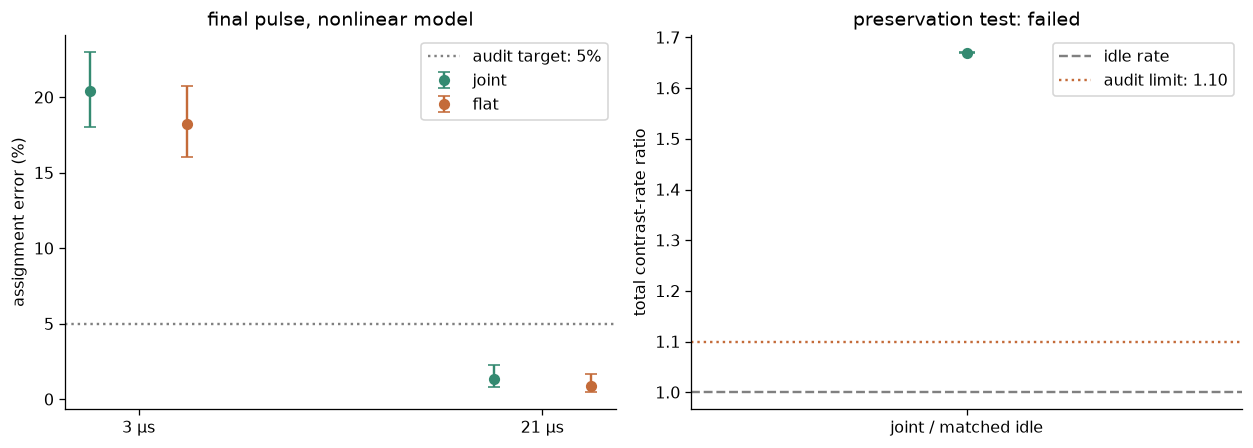

In [55]:
final_validation_recompute = False  # true reruns this audit, with compatible checkpoints reused
if final_validation_recompute:
    print("frozen final audit plan:", fv_plan_hash)  # identify the controls and acceptance thresholds
    fv_run_protection()  # active rates, corresponding idle rates, cutoff and tolerance checks
    fv_run_receivers()  # independent final-pulse homodyne records and validation samples

final_validation_result = fv_analyze()  # decide each claim from its own evidence